In [ ]:
# ============================================================
# MODULE 1 — CELL 1
# DRIVE + PATHS + SOURCE ZIP INVENTORY
# No extraction, no training, no class remapping.
# ============================================================

from pathlib import Path, PurePosixPath
from collections import Counter
import json
import zipfile

import pandas as pd
import yaml
from IPython.display import display
from google.colab import drive

# -------------------- FIXED PATHS ----------------------------

SOURCE_ZIP = Path(
    "/content/drive/MyDrive/training_dataset/"
    "yolo_dataset-20261001T214553Z-1-001.zip"
)

OUTPUT_ROOT = Path(
    "/content/drive/MyDrive/training_dataset/extra_data"
)

DATASET_MODULE_DIR = OUTPUT_ROOT / "module_1_dataset"
DATASET_REPORT_DIR = DATASET_MODULE_DIR / "reports"
PREPARED_DATASET_DIR = DATASET_MODULE_DIR / "prepared_dataset"

TRAINING_MODULE_DIR = OUTPUT_ROOT / "module_2_training"

# -------------------- MOUNT DRIVE ----------------------------

if not Path("/content/drive/MyDrive").is_dir():
    drive.mount("/content/drive")

if not SOURCE_ZIP.is_file():
    raise FileNotFoundError(f"Source ZIP not found:\n{SOURCE_ZIP}")

if not zipfile.is_zipfile(SOURCE_ZIP):
    raise ValueError(f"Not a valid ZIP:\n{SOURCE_ZIP}")

DATASET_REPORT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp"
}

# -------------------- HELPERS --------------------------------

def read_raw_class_names(config):
    names = config.get("names")

    if isinstance(names, list):
        mapping = dict(enumerate(names))
    elif isinstance(names, dict):
        mapping = {}

        for key, value in names.items():
            key_text = str(key).strip()

            if not key_text.isdigit():
                raise ValueError(f"Invalid class ID: {key!r}")

            class_id = int(key_text)

            if class_id in mapping:
                raise ValueError(f"Duplicate numeric class ID: {class_id}")

            mapping[class_id] = value
    else:
        raise ValueError("'names' must be a list or dictionary")

    if not mapping:
        raise ValueError("Empty class map")

    if sorted(mapping) != list(range(len(mapping))):
        raise ValueError(f"Non-contiguous class IDs: {mapping}")

    if any(
        not isinstance(name, str) or not name.strip()
        for name in mapping.values()
    ):
        raise ValueError(f"Invalid class names: {mapping}")

    if "nc" in config and int(config["nc"]) != len(mapping):
        raise ValueError(
            f"nc={config['nc']} does not match {len(mapping)} names"
        )

    return mapping


def files_under(member_paths, directory, extensions):
    return [
        path for path in member_paths
        if directory in path.parents
        and path.suffix.lower() in extensions
    ]


# -------------------- INSPECT ZIP ----------------------------

inventory_rows = []
class_rows = []
source_records = []
issues = []

with zipfile.ZipFile(SOURCE_ZIP, "r") as archive:
    members = [
        info for info in archive.infolist()
        if not info.is_dir()
        and "__MACOSX" not in PurePosixPath(info.filename).parts
    ]

    # Unsafe paths are rejected before later extraction.
    unsafe_paths = [
        info.filename
        for info in members
        if (
            PurePosixPath(info.filename).is_absolute()
            or ".." in PurePosixPath(info.filename).parts
            or "\\" in info.filename
        )
    ]

    if unsafe_paths:
        raise ValueError(
            "Unsafe archive paths detected:\n"
            + "\n".join(unsafe_paths[:20])
        )

    member_counts = Counter(info.filename for info in members)
    duplicate_entries = [
        name for name, count in member_counts.items()
        if count > 1
    ]

    if duplicate_entries:
        raise ValueError(
            "Duplicate ZIP member names detected:\n"
            + "\n".join(duplicate_entries[:20])
        )

    member_paths = [
        PurePosixPath(info.filename) for info in members
    ]

    yaml_members = sorted(
        path for path in member_paths
        if path.name.lower() in {"data.yaml", "data.yml"}
    )

    for yaml_member in yaml_members:
        dataset_root = yaml_member.parent

        # Recognize dataset roots containing standard split folders.
        has_images = any(
            files_under(
                member_paths,
                dataset_root / split / "images",
                IMAGE_EXTENSIONS,
            )
            for split in ("train", "valid", "val", "test")
        )

        if not has_images:
            issues.append({
                "source": str(yaml_member),
                "issue": "YAML has no recognized split/images structure",
            })
            continue

        try:
            config = yaml.safe_load(
                archive.read(str(yaml_member)).decode("utf-8-sig")
            )

            if not isinstance(config, dict):
                raise ValueError("YAML root must be a dictionary")

            raw_names = read_raw_class_names(config)

        except Exception as error:
            issues.append({
                "source": str(yaml_member),
                "issue": f"YAML/class-map error: {error}",
            })
            continue

        source_id = str(dataset_root)

        source_records.append({
            "source_id": source_id,
            "yaml_member": str(yaml_member),
            "raw_names": raw_names,
            "yaml_split_paths": {
                key: config.get(key)
                for key in ("path", "train", "val", "test")
            },
        })

        for class_id, class_name in sorted(raw_names.items()):
            class_rows.append({
                "source": source_id,
                "raw_class_id": class_id,
                "raw_class_name": class_name,
            })

        for split in ("train", "valid", "val", "test"):
            images_dir = dataset_root / split / "images"
            labels_dir = dataset_root / split / "labels"

            images = files_under(
                member_paths, images_dir, IMAGE_EXTENSIONS
            )
            labels = files_under(
                member_paths, labels_dir, {".txt"}
            )

            if not images and not labels:
                continue

            # Relative paths preserve any nested directories.
            image_keys = [
                str(path.relative_to(images_dir).with_suffix(""))
                for path in images
            ]
            label_keys = [
                str(path.relative_to(labels_dir).with_suffix(""))
                for path in labels
            ]

            image_key_set = set(image_keys)
            label_key_set = set(label_keys)

            ambiguous_image_stems = sum(
                count > 1
                for count in Counter(image_keys).values()
            )

            inventory_rows.append({
                "source": source_id,
                "split": split,
                "images": len(images),
                "labels": len(labels),
                "missing_labels": len(
                    image_key_set - label_key_set
                ),
                "orphan_labels": len(
                    label_key_set - image_key_set
                ),
                "ambiguous_image_stems": ambiguous_image_stems,
            })

    archive_summary = {
        "zip_size_mb": round(SOURCE_ZIP.stat().st_size / 1024**2, 2),
        "file_members": len(members),
        "uncompressed_size_mb": round(
            sum(info.file_size for info in members) / 1024**2, 2
        ),
    }

# -------------------- SAVE ORGANIZED REPORTS -----------------

inventory_df = pd.DataFrame(inventory_rows)
raw_classes_df = pd.DataFrame(class_rows)

report = {
    "source_zip": str(SOURCE_ZIP),
    "output_root": str(OUTPUT_ROOT),
    "archive": archive_summary,
    "discovered_dataset_count": len(source_records),
    "sources": source_records,
    "split_inventory": inventory_rows,
    "issues": issues,
    "scope": (
        "Archive inventory only. Image decoding, polygon validation, "
        "duplicate-image checks and diagnosis verification are pending."
    ),
}

report_path = DATASET_REPORT_DIR / "01_source_inventory.json"

with report_path.open("w", encoding="utf-8") as file:
    json.dump(report, file, indent=2, ensure_ascii=False)

if not inventory_df.empty:
    inventory_df.to_csv(
        DATASET_REPORT_DIR / "01_split_inventory.csv",
        index=False,
    )

if not raw_classes_df.empty:
    raw_classes_df.to_csv(
        DATASET_REPORT_DIR / "01_raw_class_mapping.csv",
        index=False,
    )

# -------------------- DISPLAY --------------------------------

print("=" * 90)
print("MODULE 1 — SOURCE DATASET INVENTORY")
print("=" * 90)
print("Source ZIP       :", SOURCE_ZIP)
print("Output folder    :", OUTPUT_ROOT)
print("ZIP size         :", archive_summary["zip_size_mb"], "MB")
print("Uncompressed size:", archive_summary["uncompressed_size_mb"], "MB")
print("Datasets found   :", len(source_records))

print("\nRAW CLASS IDS AND EXACT NAMES")
display(raw_classes_df)

print("\nSOURCE SPLIT INVENTORY")
display(inventory_df)

if not inventory_df.empty:
    print("\nTOTALS")
    display(
        inventory_df[
            ["images", "labels", "missing_labels", "orphan_labels"]
        ].sum().to_frame("count")
    )

if issues:
    print("\nSTRUCTURE / CONFIGURATION ISSUES")
    display(pd.DataFrame(issues))

print("\nReport:", report_path)
print(
    "\nNo images extracted. No samples removed. "
    "No class IDs changed."
)

if not source_records:
    raise RuntimeError(
        "No usable dataset roots found. Review the saved inventory."
    )

print("\nCell 1 complete. Share the displayed output.")

MODULE 1 — SOURCE DATASET INVENTORY
Source ZIP       : /content/drive/MyDrive/training_dataset/yolo_dataset-20261001T214553Z-1-001.zip
Output folder    : /content/drive/MyDrive/training_dataset/extra_data
ZIP size         : 45.1 MB
Uncompressed size: 45.09 MB
Datasets found   : 5

RAW CLASS IDS AND EXACT NAMES


,source,raw_class_id,raw_class_name
0,yolo_dataset/cancer_detection.v2i.yolov11,0,cancer-detection
1,yolo_dataset/cancer_detection.v2i.yolov11,1,processing_area
2,yolo_dataset/leukoplakia_detection.v2i.yolov11,0,leukoplakia-detection
3,yolo_dataset/leukoplakia_detection.v2i.yolov11,1,processing_area
4,yolo_dataset/leukoplakia_like_detection.v3i.yo...,0,leukoplakia-like-detection
5,yolo_dataset/leukoplakia_like_detection.v3i.yo...,1,processing_area
6,yolo_dataset/processing_area.v3i.yolov11,0,processing_area
7,yolo_dataset/ulcer_detection.v4i.yolov11,0,processing_area
8,yolo_dataset/ulcer_detection.v4i.yolov11,1,ulcer-detection



SOURCE SPLIT INVENTORY


,source,split,images,labels,missing_labels,orphan_labels,ambiguous_image_stems
0,yolo_dataset/cancer_detection.v2i.yolov11,train,170,170,0,0,0
1,yolo_dataset/cancer_detection.v2i.yolov11,valid,21,21,0,0,0
2,yolo_dataset/cancer_detection.v2i.yolov11,test,10,10,0,0,0
3,yolo_dataset/leukoplakia_detection.v2i.yolov11,train,175,175,0,0,0
4,yolo_dataset/leukoplakia_detection.v2i.yolov11,valid,49,49,0,0,0
5,yolo_dataset/leukoplakia_detection.v2i.yolov11,test,26,26,0,0,0
6,yolo_dataset/leukoplakia_like_detection.v3i.yo...,train,176,176,0,0,0
7,yolo_dataset/leukoplakia_like_detection.v3i.yo...,valid,49,49,0,0,0
8,yolo_dataset/leukoplakia_like_detection.v3i.yo...,test,25,25,0,0,0
9,yolo_dataset/processing_area.v3i.yolov11,train,190,190,0,0,0



TOTALS


,count
images,1166
labels,1166
missing_labels,0
orphan_labels,0



Report: /content/drive/MyDrive/training_dataset/extra_data/module_1_dataset/reports/01_source_inventory.json

No images extracted. No samples removed. No class IDs changed.

Cell 1 complete. Share the displayed output.


In [ ]:
# ============================================================
# MODULE 1 — CELL 2
# IMAGE + ANNOTATION AUDIT + DUPLICATE REVIEW
# Reads directly from ZIP; does not extract or delete images.
# ============================================================

from pathlib import Path, PurePosixPath
from collections import Counter, defaultdict
from PIL import Image
from IPython.display import display

import io
import re
import json
import hashlib
import zipfile
import numpy as np
import pandas as pd

SOURCE_ZIP = Path(
    "/content/drive/MyDrive/training_dataset/"
    "yolo_dataset-20261001T214553Z-1-001.zip"
)

REPORT_DIR = Path(
    "/content/drive/MyDrive/training_dataset/extra_data/"
    "module_1_dataset/reports"
)

INVENTORY_PATH = REPORT_DIR / "01_source_inventory.json"

if not INVENTORY_PATH.is_file():
    raise FileNotFoundError("Cell 1 ka inventory report nahi mila.")

with INVENTORY_PATH.open("r", encoding="utf-8") as file:
    inventory = json.load(file)

if inventory["source_zip"] != str(SOURCE_ZIP):
    raise ValueError("Cell 1 aur Cell 2 ke source paths different hain.")

if not SOURCE_ZIP.is_file():
    raise FileNotFoundError(SOURCE_ZIP)

REPORT_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp"
}

# Source identities only; classifier class IDs are NOT assigned.
SOURCE_CATEGORY = {
    "cancer-detection": "Cancer",
    "leukoplakia-detection": "Leukoplakia",
    "leukoplakia-like-detection": "Leukoplakia-like Conditions",
    "ulcer-detection": "Ulcer",
}

APPROVED_RAW_NAMES = {"processing_area"} | set(SOURCE_CATEGORY)

def filename_family_candidate(filename):
    """Filename evidence only; not a confirmed patient/source group."""
    name = PurePosixPath(filename).stem.lower()
    name = re.sub(r"\.rf\.[a-z0-9]+$", "", name)
    previous = None

    while previous != name:
        previous = name
        name = re.sub(
            r"^(?:copy[-_ ]of[-_ ]|aug[-_ ]\d+[-_ ])", "", name
        )

    return name


def parse_polygons(text, names):
    polygons = []
    errors = []

    for line_number, line in enumerate(text.splitlines(), start=1):
        if not line.strip():
            continue

        try:
            tokens = line.split()

            if len(tokens) < 7:
                raise ValueError("Fewer than three polygon points")

            if not re.fullmatch(r"\d+", tokens[0]):
                raise ValueError("Class ID must be a non-negative integer")

            class_id = int(tokens[0])

            if class_id not in names:
                raise ValueError("Class ID absent from source YAML")

            if (len(tokens) - 1) % 2:
                raise ValueError("Odd coordinate count")

            points = np.asarray(
                [float(value) for value in tokens[1:]],
                dtype=np.float64,
            ).reshape(-1, 2)

            if not np.isfinite(points).all():
                raise ValueError("NaN/infinite coordinates")

            if ((points < 0) | (points > 1)).any():
                raise ValueError("Coordinates outside [0, 1]")

            if len(np.unique(points, axis=0)) < 3:
                raise ValueError("Fewer than three distinct vertices")

            x, y = points[:, 0], points[:, 1]
            area = float(
                abs(
                    np.dot(x, np.roll(y, -1))
                    - np.dot(y, np.roll(x, -1))
                ) / 2
            )

            if area <= 1e-12:
                raise ValueError("Zero/degenerate polygon area")

            polygons.append({
                "line_number": line_number,
                "raw_class_id": class_id,
                "raw_class_name": names[class_id],
                "points": points.tolist(),
                "normalized_area": area,
            })

        except Exception as error:
            errors.append({
                "line_number": line_number,
                "reason": str(error),
            })

    return polygons, errors


records = []
polygons_manifest = []
problems = []
source_configuration = []

with zipfile.ZipFile(SOURCE_ZIP, "r") as archive:
    members = [
        info for info in archive.infolist()
        if not info.is_dir()
        and "__MACOSX" not in PurePosixPath(info.filename).parts
    ]

    counts = Counter(info.filename for info in members)

    if any(count > 1 for count in counts.values()):
        raise ValueError("Duplicate ZIP member names; rerun source checks.")

    member_names = set(counts)
    member_paths = [PurePosixPath(name) for name in member_names]

    for source in inventory["sources"]:
        root = PurePosixPath(source["source_id"])
        names = {
            int(key): value
            for key, value in source["raw_names"].items()
        }

        unknown = sorted(set(names.values()) - APPROVED_RAW_NAMES)

        if unknown:
            raise ValueError(
                f"Unknown raw classes in {root}: {unknown}"
            )

        disease_names = [
            name for name in names.values()
            if name in SOURCE_CATEGORY
        ]

        if len(disease_names) > 1:
            raise ValueError(
                f"Multiple disease names in source {root}: "
                f"{disease_names}. Explicit mapping required."
            )

        category = (
            SOURCE_CATEGORY[disease_names[0]]
            if disease_names
            else "Processing-area-only (diagnosis unverified)"
        )

        source_configuration.append({
            "source_id": str(root),
            "source_category": category,
            "raw_names": names,
        })

        print(f"\nChecking: {root.name}")

        for split in ("train", "valid", "val", "test"):
            images_dir = root / split / "images"
            labels_dir = root / split / "labels"

            images = sorted(
                path for path in member_paths
                if images_dir in path.parents
                and path.suffix.lower() in IMAGE_EXTENSIONS
            )

            if not images:
                continue

            print(f"  {split}: {len(images)} images")

            for image_number, image_path in enumerate(images, start=1):
                relative_image = image_path.relative_to(images_dir)
                label_path = (
                    labels_dir / relative_image.with_suffix(".txt")
                )

                row = {
                    "source_id": str(root),
                    "source_category": category,
                    "original_split": (
                        "valid" if split == "val" else split
                    ),
                    "image_member": str(image_path),
                    "label_member": str(label_path),
                    "filename_family_candidate":
                        filename_family_candidate(image_path.name),
                    "file_sha256": "",
                    "decoded_rgb_sha256": "",
                    "width": None,
                    "height": None,
                    "image_valid": False,
                    "label_present": str(label_path) in member_names,
                    "empty_label": False,
                    "annotation_valid": False,
                    "processing_instances": 0,
                    "lesion_instances": 0,
                }

                try:
                    image_bytes = archive.read(str(image_path))
                    row["file_sha256"] = hashlib.sha256(
                        image_bytes
                    ).hexdigest()

                    # Decode all pixels; this checks more than file headers.
                    with Image.open(io.BytesIO(image_bytes)) as image:
                        image.load()
                        rgb = np.asarray(
                            image.convert("RGB"), dtype=np.uint8
                        )
                        row["width"], row["height"] = image.size

                    digest = hashlib.sha256()
                    digest.update(
                        f"{row['width']}x{row['height']}|RGB|".encode()
                    )
                    digest.update(rgb.tobytes())
                    row["decoded_rgb_sha256"] = digest.hexdigest()
                    row["image_valid"] = True

                except Exception as error:
                    problems.append({
                        "image_member": str(image_path),
                        "issue": "image_decode_error",
                        "line_number": None,
                        "detail": str(error),
                    })

                if not row["label_present"]:
                    problems.append({
                        "image_member": str(image_path),
                        "issue": "missing_label",
                        "line_number": None,
                        "detail": str(label_path),
                    })
                else:
                    try:
                        text = archive.read(
                            str(label_path)
                        ).decode("utf-8-sig")

                        row["empty_label"] = not text.strip()
                        parsed, errors = parse_polygons(text, names)

                        row["annotation_valid"] = (
                            not row["empty_label"] and not errors
                        )

                        for error in errors:
                            problems.append({
                                "image_member": str(image_path),
                                "issue": "invalid_polygon",
                                "line_number": error["line_number"],
                                "detail": error["reason"],
                            })

                        if row["empty_label"]:
                            problems.append({
                                "image_member": str(image_path),
                                "issue": "empty_label",
                                "line_number": None,
                                "detail": "Requires annotation review",
                            })

                        for polygon in parsed:
                            is_processing = (
                                polygon["raw_class_name"]
                                == "processing_area"
                            )

                            row[
                                "processing_instances"
                                if is_processing
                                else "lesion_instances"
                            ] += 1

                            polygons_manifest.append({
                                "image_member": str(image_path),
                                "label_member": str(label_path),
                                **polygon,
                            })

                        if (
                            row["annotation_valid"]
                            and row["processing_instances"] == 0
                        ):
                            problems.append({
                                "image_member": str(image_path),
                                "issue": "processing_annotation_absent",
                                "line_number": None,
                                "detail": "Primary ROI requires review",
                            })

                        if (
                            disease_names
                            and row["annotation_valid"]
                            and row["lesion_instances"] == 0
                        ):
                            problems.append({
                                "image_member": str(image_path),
                                "issue": "disease_source_without_lesion",
                                "line_number": None,
                                "detail": "Requires label review",
                            })

                    except Exception as error:
                        problems.append({
                            "image_member": str(image_path),
                            "issue": "label_read_error",
                            "line_number": None,
                            "detail": str(error),
                        })

                records.append(row)

                if image_number % 100 == 0:
                    print(f"    Checked {image_number}/{len(images)}")

audit_df = pd.DataFrame(records)

if audit_df.empty:
    raise RuntimeError("No images audited.")

# Necessary technical condition, not clinical label approval.
audit_df["technically_eligible_primary_roi"] = (
    audit_df["image_valid"]
    & audit_df["annotation_valid"]
    & (audit_df["processing_instances"] > 0)
)

duplicate_rows = []

for hash_column in ("file_sha256", "decoded_rgb_sha256"):
    hashed = audit_df[audit_df[hash_column] != ""]

    for hash_value, group in hashed.groupby(hash_column):
        if len(group) < 2:
            continue

        duplicate_rows.append({
            "evidence": hash_column,
            "hash": hash_value,
            "copies": len(group),
            "crosses_splits":
                group["original_split"].nunique() > 1,
            "crosses_source_categories":
                group["source_category"].nunique() > 1,
            "splits": " | ".join(
                sorted(group["original_split"].unique())
            ),
            "categories": " | ".join(
                sorted(group["source_category"].unique())
            ),
            "image_members": " | ".join(group["image_member"]),
        })

# Filename candidates are NOT automatically treated as duplicates.
family_rows = []

for family, group in audit_df.groupby("filename_family_candidate"):
    if len(group) < 2:
        continue

    if (
        group["original_split"].nunique() > 1
        or group["source_id"].nunique() > 1
    ):
        family_rows.append({
            "filename_family_candidate": family,
            "copies": len(group),
            "crosses_splits":
                group["original_split"].nunique() > 1,
            "crosses_source_categories":
                group["source_category"].nunique() > 1,
            "categories": " | ".join(
                sorted(group["source_category"].unique())
            ),
            "image_members": " | ".join(group["image_member"]),
            "status": "Candidate only — visual/source review required",
        })

problems_df = pd.DataFrame(
    problems,
    columns=["image_member", "issue", "line_number", "detail"],
)

duplicates_df = pd.DataFrame(
    duplicate_rows,
    columns=[
        "evidence", "hash", "copies", "crosses_splits",
        "crosses_source_categories", "splits",
        "categories", "image_members",
    ],
)

families_df = pd.DataFrame(
    family_rows,
    columns=[
        "filename_family_candidate", "copies", "crosses_splits",
        "crosses_source_categories", "categories",
        "image_members", "status",
    ],
)

summary_df = (
    audit_df.groupby("source_category", as_index=False)
    .agg(
        images=("image_member", "size"),
        readable_images=("image_valid", "sum"),
        valid_nonempty_annotations=("annotation_valid", "sum"),
        empty_labels=("empty_label", "sum"),
        processing_objects=("processing_instances", "sum"),
        lesion_objects=("lesion_instances", "sum"),
        technically_eligible_primary_roi=(
            "technically_eligible_primary_roi", "sum"
        ),
    )
)

# -------------------- SAVE REPORTS ----------------------------

audit_df.to_csv(REPORT_DIR / "02_image_audit.csv", index=False)
problems_df.to_csv(REPORT_DIR / "02_annotation_issues.csv", index=False)
duplicates_df.to_csv(REPORT_DIR / "02_exact_duplicates.csv", index=False)
families_df.to_csv(
    REPORT_DIR / "02_filename_review_candidates.csv", index=False
)
summary_df.to_csv(REPORT_DIR / "02_audit_summary.csv", index=False)

with (
    REPORT_DIR / "02_polygon_manifest.json"
).open("w", encoding="utf-8") as file:
    json.dump(polygons_manifest, file, indent=2, ensure_ascii=False)

with (
    REPORT_DIR / "02_source_configuration.json"
).open("w", encoding="utf-8") as file:
    json.dump(source_configuration, file, indent=2, ensure_ascii=False)

print("\n" + "=" * 90)
print("CELL 2 — AUDIT SUMMARY")
print("=" * 90)
display(summary_df)

print("\nANNOTATION / IMAGE ISSUES")
if problems_df.empty:
    print("No structural issues detected.")
else:
    display(
        problems_df["issue"]
        .value_counts()
        .rename_axis("issue")
        .reset_index(name="count")
    )

print("\nEXACT DUPLICATE GROUPS BY EVIDENCE")
if duplicates_df.empty:
    print("No file-identical or decoded-pixel-identical duplicates.")
else:
    display(
        duplicates_df.groupby("evidence", as_index=False)
        .agg(
            groups=("hash", "size"),
            cross_split_groups=("crosses_splits", "sum"),
            cross_category_groups=("crosses_source_categories", "sum"),
        )
    )
    print(
        "The same images can appear under both hash methods; "
        "do not add these group counts together."
    )
    display(
        duplicates_df.drop(columns=["image_members"]).head(20)
    )

print("\nFILENAME REVIEW CANDIDATES")
print("Candidate groups:", len(families_df))
print("Filename matches alone do not confirm duplicate images.")

print("\nReports saved in:", REPORT_DIR)
print(
    "\nNo images removed. No crops generated. "
    "No classes remapped or balanced."
)
print(
    "This audit does not establish patient independence, "
    "clinical diagnosis correctness or polygon self-intersection."
)
print("\nCell 2 complete. Share the summary output.")


Checking: cancer_detection.v2i.yolov11
  train: 170 images
    Checked 100/170
  valid: 21 images
  test: 10 images

Checking: leukoplakia_detection.v2i.yolov11
  train: 175 images
    Checked 100/175
  valid: 49 images
  test: 26 images

Checking: leukoplakia_like_detection.v3i.yolov11
  train: 176 images
    Checked 100/176
  valid: 49 images
  test: 25 images

Checking: processing_area.v3i.yolov11
  train: 190 images
    Checked 100/190
  valid: 50 images
  test: 25 images

Checking: ulcer_detection.v4i.yolov11
  train: 140 images
    Checked 100/140
  valid: 40 images
  test: 20 images

CELL 2 — AUDIT SUMMARY


,source_category,images,readable_images,valid_nonempty_annotations,empty_labels,processing_objects,lesion_objects,technically_eligible_primary_roi
0,Cancer,201,201,200,1,208,216,200
1,Leukoplakia,250,250,249,1,267,307,248
2,Leukoplakia-like Conditions,250,250,250,0,258,305,250
3,Processing-area-only (diagnosis unverified),265,265,264,1,268,0,264
4,Ulcer,200,200,195,5,201,227,194



ANNOTATION / IMAGE ISSUES


,issue,count
0,empty_label,8
1,processing_annotation_absent,2
2,disease_source_without_lesion,1



EXACT DUPLICATE GROUPS BY EVIDENCE


,evidence,groups,cross_split_groups,cross_category_groups
0,decoded_rgb_sha256,1,1,1
1,file_sha256,1,1,1


The same images can appear under both hash methods; do not add these group counts together.


,evidence,hash,copies,crosses_splits,crosses_source_categories,splits,categories
0,file_sha256,b2e905838e9497c2691ccc6b3096027d1469116ef0e5ef...,2,True,True,test | valid,Leukoplakia | Leukoplakia-like Conditions
1,decoded_rgb_sha256,d55044c40edf24c89db32cd5f71dfd6b227f43cc4060a7...,2,True,True,test | valid,Leukoplakia | Leukoplakia-like Conditions



FILENAME REVIEW CANDIDATES
Candidate groups: 87
Filename matches alone do not confirm duplicate images.

Reports saved in: /content/drive/MyDrive/training_dataset/extra_data/module_1_dataset/reports

No images removed. No crops generated. No classes remapped or balanced.
This audit does not establish patient independence, clinical diagnosis correctness or polygon self-intersection.

Cell 2 complete. Share the summary output.


PROVISIONAL PREPARATION STATUS


preparation_status,candidate,hold
source_category,,
Cancer,200,1
Leukoplakia,246,4
Leukoplakia-like Conditions,249,1
Processing-area-only (diagnosis unverified),264,1
Ulcer,194,6



HOLD REASONS — counts may overlap
processing_annotation_absent            10
empty_or_invalid_annotation              8
disease_source_without_lesion            8
exact_image_source_category_conflict     2

Review candidate groups: 87
Review CSV: /content/drive/MyDrive/training_dataset/extra_data/module_1_dataset/reports/03_source_review.csv


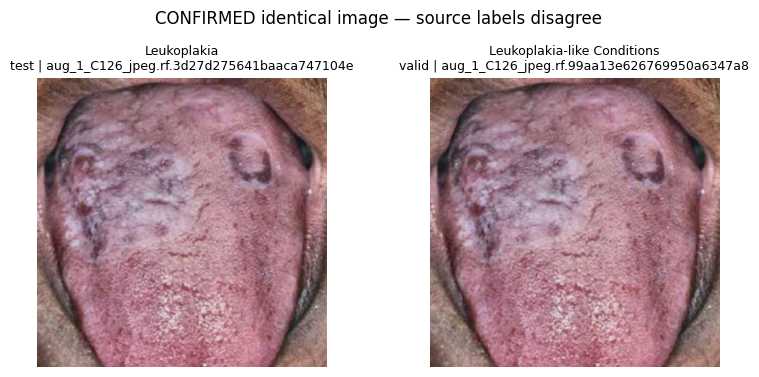

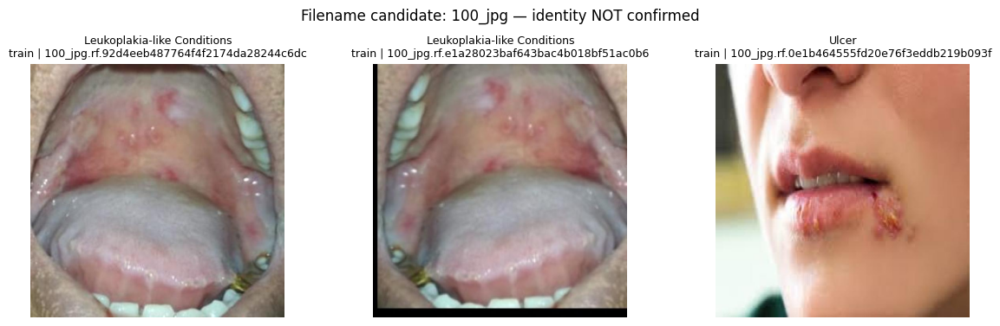

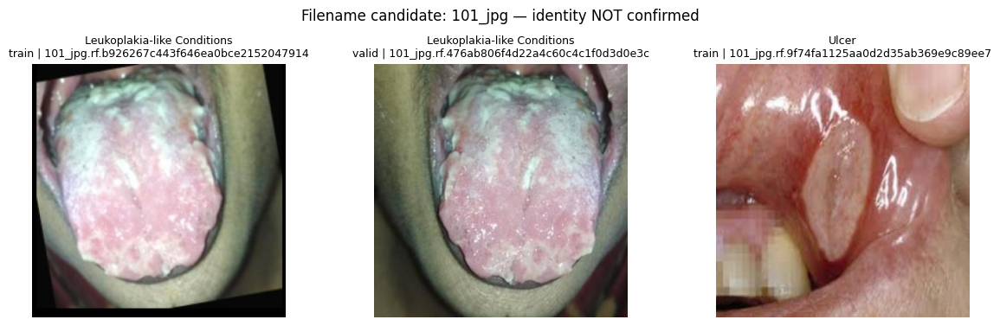

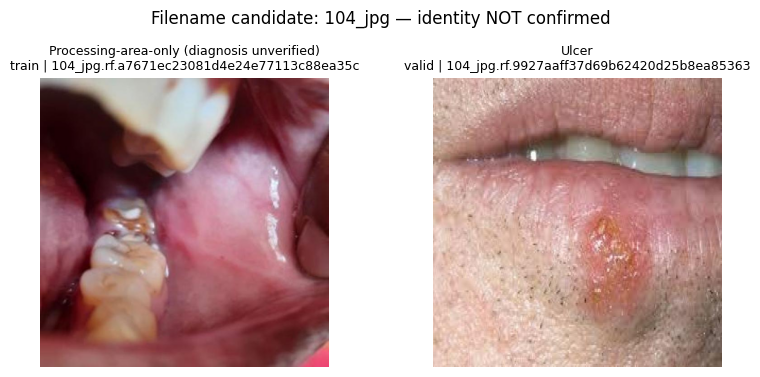

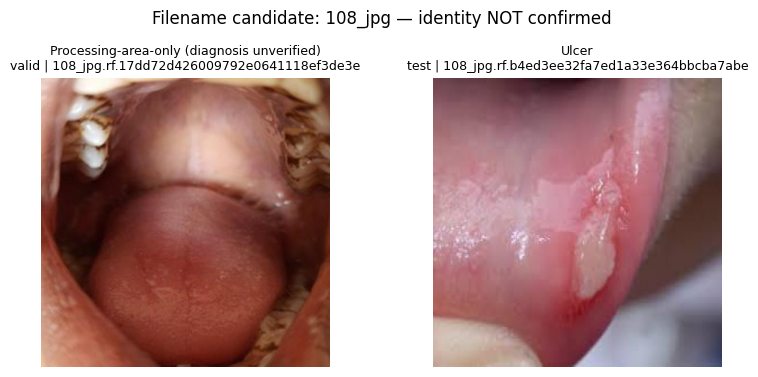

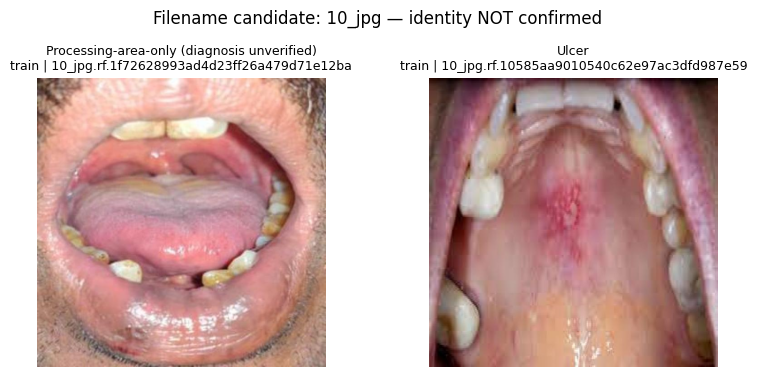

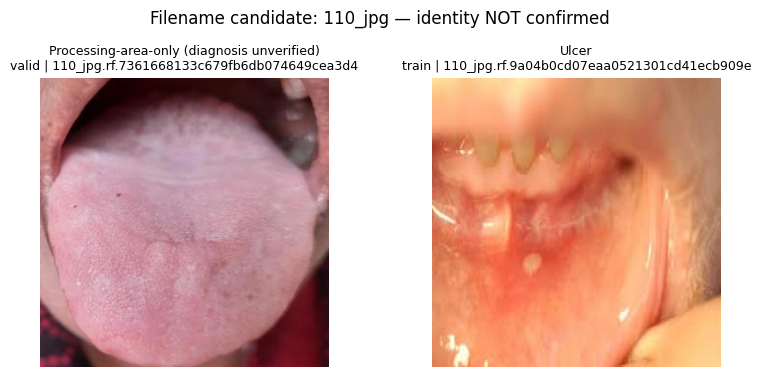


Cell 3 complete.
Candidate = technically usable, NOT final diagnosis approval.
No original files deleted; no final split or balancing performed.


In [ ]:
# ============================================================
# MODULE 1 — CELL 3
# PROVISIONAL CLEAN MANIFEST + SOURCE REVIEW
# No final classifier mapping, splitting or balancing.
# ============================================================

from pathlib import Path
from collections import defaultdict
import io
import json
import zipfile

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

SOURCE_ZIP = Path(
    "/content/drive/MyDrive/training_dataset/"
    "yolo_dataset-20261001T214553Z-1-001.zip"
)

REPORT_DIR = Path(
    "/content/drive/MyDrive/training_dataset/extra_data/"
    "module_1_dataset/reports"
)

AUDIT_PATH = REPORT_DIR / "02_image_audit.csv"
REVIEW_PATH = REPORT_DIR / "03_source_review.csv"

if not AUDIT_PATH.is_file():
    raise FileNotFoundError("Cell 2 audit missing. Pehle Cell 2 run karo.")

df = pd.read_csv(AUDIT_PATH, keep_default_na=False)

if df.empty or df["image_member"].duplicated().any():
    raise ValueError("Audit empty hai ya image-member rows duplicated hain.")

def strict_bool(value):
    text = str(value).strip().lower()
    if text in {"true", "1"}:
        return True
    if text in {"false", "0"}:
        return False
    raise ValueError(f"Unexpected boolean: {value!r}")

for column in ("image_valid", "annotation_valid", "empty_label"):
    df[column] = df[column].map(strict_bool)

for column in ("processing_instances", "lesion_instances"):
    df[column] = pd.to_numeric(df[column], errors="raise").astype(int)

# ---------------- EXACT CONTENT GROUPS -----------------------
# Connect matches under either byte hash or decoded RGB hash.
# Filename similarity does NOT participate in this grouping.

parent = list(range(len(df)))

def find(index):
    while parent[index] != index:
        parent[index] = parent[parent[index]]
        index = parent[index]
    return index

def union(a, b):
    a, b = find(a), find(b)
    if a != b:
        parent[max(a, b)] = min(a, b)

for hash_column in ("file_sha256", "decoded_rgb_sha256"):
    first_seen = {}
    for index, value in enumerate(df[hash_column]):
        if not value:
            continue
        if value in first_seen:
            union(index, first_seen[value])
        else:
            first_seen[value] = index

groups = defaultdict(list)
for index in range(len(df)):
    groups[find(index)].append(index)

df["exact_content_group"] = ""
df["preparation_status"] = "candidate"
reasons = defaultdict(list)

# Technical eligibility only; does not verify disease diagnosis.
for index, row in df.iterrows():
    if not row["image_valid"]:
        reasons[index].append("image_decode_failure")
    if not row["annotation_valid"]:
        reasons[index].append("empty_or_invalid_annotation")
    if row["processing_instances"] == 0:
        reasons[index].append("processing_annotation_absent")
    if (
        row["source_category"]
        != "Processing-area-only (diagnosis unverified)"
        and row["lesion_instances"] == 0
    ):
        reasons[index].append("disease_source_without_lesion")

duplicate_decisions = []

for indices in groups.values():
    members = sorted(df.loc[indices, "image_member"])
    # Stable identity derived from group contents.
    import hashlib
    group_id = hashlib.sha256(
        "\n".join(members).encode("utf-8")
    ).hexdigest()[:20]

    df.loc[indices, "exact_content_group"] = group_id

    if len(indices) < 2:
        continue

    group = df.loc[indices]
    category_conflict = group["source_category"].nunique() > 1

    if category_conflict:
        # Quarantine ALL copies; do not guess the correct diagnosis.
        for index in indices:
            reasons[index].append("exact_image_source_category_conflict")

        action = "all_copies_pending_label_review"
        retained_member = ""

    else:
        # Keep one technically usable copy deterministically.
        eligible = [index for index in indices if not reasons[index]]

        if eligible:
            retained = min(
                eligible, key=lambda index: df.at[index, "image_member"]
            )
            retained_member = df.at[retained, "image_member"]

            for index in indices:
                if index != retained:
                    reasons[index].append("redundant_exact_copy")

            action = "one_copy_retained_pending_group_split"
        else:
            action = "no_technically_eligible_copy"
            retained_member = ""

    duplicate_decisions.append({
        "exact_content_group": group_id,
        "copies": len(indices),
        "categories": " | ".join(
            sorted(group["source_category"].unique())
        ),
        "original_splits": " | ".join(
            sorted(group["original_split"].unique())
        ),
        "action": action,
        "retained_member": retained_member,
        "image_members": " | ".join(members),
    })

df["preparation_reasons"] = [
    " | ".join(reasons[index]) for index in range(len(df))
]
df.loc[df["preparation_reasons"] != "", "preparation_status"] = "hold"

# ---------------- FILENAME REVIEW QUEUE ----------------------
# Preserve existing user review entries on reruns.

review_records = []

for family, group in df.groupby("filename_family_candidate"):
    if len(group) < 2:
        continue

    if (
        group["original_split"].nunique() > 1
        or group["source_id"].nunique() > 1
    ):
        for _, row in group.iterrows():
            review_records.append({
                "filename_family_candidate": family,
                "image_member": row["image_member"],
                "source_category": row["source_category"],
                "original_split": row["original_split"],
                "exact_content_group": row["exact_content_group"],
                "verified_source_group": "",
                "verified_diagnosis": "",
                "review_notes": "",
            })

review_columns = [
    "filename_family_candidate", "image_member",
    "source_category", "original_split", "exact_content_group",
    "verified_source_group", "verified_diagnosis", "review_notes",
]
review_df = pd.DataFrame(review_records, columns=review_columns)

if REVIEW_PATH.is_file():
    previous = pd.read_csv(REVIEW_PATH, keep_default_na=False)

    if previous["image_member"].duplicated().any():
        raise ValueError("Existing review CSV contains duplicate rows.")

    previous = previous.set_index("image_member")

    for column in (
        "verified_source_group", "verified_diagnosis", "review_notes"
    ):
        if column in previous.columns:
            review_df[column] = (
                review_df["image_member"]
                .map(previous[column])
                .fillna("")
            )

review_df.to_csv(REVIEW_PATH, index=False)

df.to_csv(
    REPORT_DIR / "03_provisional_manifest.csv", index=False
)

df[df["preparation_status"] == "hold"].to_csv(
    REPORT_DIR / "03_held_samples.csv", index=False
)

pd.DataFrame(
    duplicate_decisions,
    columns=[
        "exact_content_group", "copies", "categories",
        "original_splits", "action",
        "retained_member", "image_members",
    ],
).to_csv(
    REPORT_DIR / "03_exact_duplicate_decisions.csv", index=False
)

print("=" * 90)
print("PROVISIONAL PREPARATION STATUS")
print("=" * 90)

summary = pd.crosstab(
    df["source_category"], df["preparation_status"]
).reindex(columns=["candidate", "hold"], fill_value=0)

display(summary)

print("\nHOLD REASONS — counts may overlap")
reason_counts = pd.Series(
    [reason for values in reasons.values() for reason in values],
    dtype="object",
).value_counts()
print(reason_counts.to_string())

print("\nReview candidate groups:",
      review_df["filename_family_candidate"].nunique())
print("Review CSV:", REVIEW_PATH)

# ---------------- INLINE IMAGE REVIEW ------------------------
# Show confirmed conflicts first, then filename candidates.
# Set REVIEW_START to 6 on next run for the next six groups.
# Rerunning does not erase existing review notes.

REVIEW_START = 0
REVIEW_GROUPS_TO_SHOW = 6

conflict_indices = [
    index for index in range(len(df))
    if "exact_image_source_category_conflict" in reasons[index]
]

panels = []

if REVIEW_START == 0 and conflict_indices:
    panels.append((
        "CONFIRMED identical image — source labels disagree",
        df.loc[conflict_indices],
    ))

families = sorted(
    review_df["filename_family_candidate"].unique()
)

for family in families[
    REVIEW_START:REVIEW_START + REVIEW_GROUPS_TO_SHOW
]:
    panels.append((
        f"Filename candidate: {family} — identity NOT confirmed",
        df[df["filename_family_candidate"] == family],
    ))

with zipfile.ZipFile(SOURCE_ZIP, "r") as archive:
    for title, group in panels:
        rows = list(group.iterrows())
        columns = min(4, len(rows))
        grid_rows = (len(rows) + columns - 1) // columns

        fig, axes = plt.subplots(
            grid_rows, columns,
            figsize=(4 * columns, 3.8 * grid_rows),
            squeeze=False,
        )

        for axis in axes.flat:
            axis.axis("off")

        for axis, (_, row) in zip(axes.flat, rows):
            try:
                with Image.open(
                    io.BytesIO(archive.read(row["image_member"]))
                ) as image:
                    axis.imshow(image.convert("RGB"))
            except Exception as error:
                axis.text(
                    0.5, 0.5, f"Image read failed:\n{error}",
                    ha="center", va="center",
                )

            axis.set_title(
                f"{row['source_category']}\n"
                f"{row['original_split']} | "
                f"{Path(row['image_member']).name[:42]}",
                fontsize=9,
            )

        fig.suptitle(title, fontsize=12)
        plt.tight_layout()
        plt.show()

print("\nCell 3 complete.")
print("Candidate = technically usable, NOT final diagnosis approval.")
print("No original files deleted; no final split or balancing performed.")

FROZEN CLASSIFIER CLASS CONTRACT


,class_id,class_name
0,0,Cancer
1,1,Leukoplakia
2,2,Leukoplakia-like Conditions
3,3,Normal Buccal Mucosa
4,4,Ulcers



CURRENT DATASET STATUS


dataset_stage_status,mapped_candidate_source_review_pending,normal_confirmation_pending,technical_or_exact_conflict_hold
source_category,,,
Cancer,200,0,1
Leukoplakia,246,0,4
Leukoplakia-like Conditions,249,0,1
Processing-area-only (diagnosis unverified),0,264,1
Ulcer,194,0,6


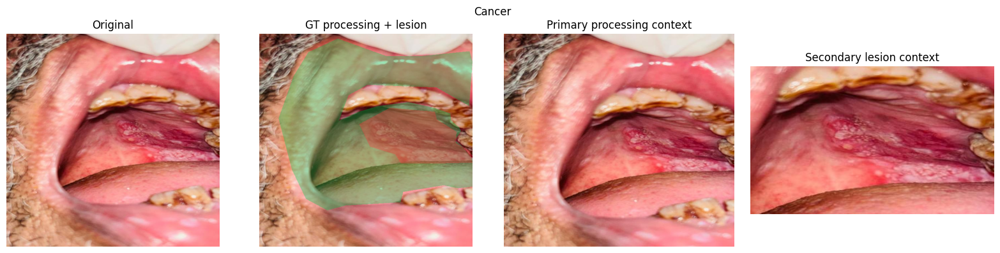

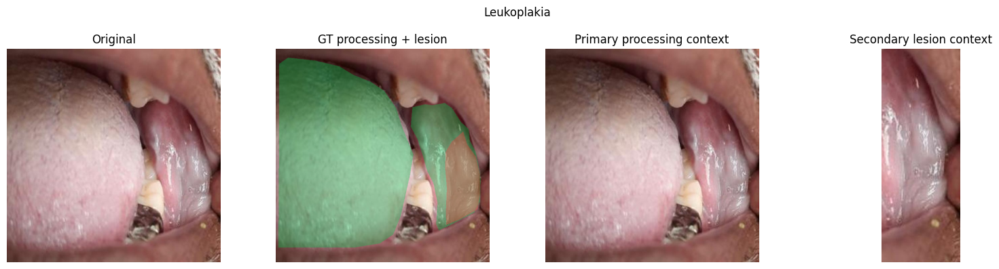

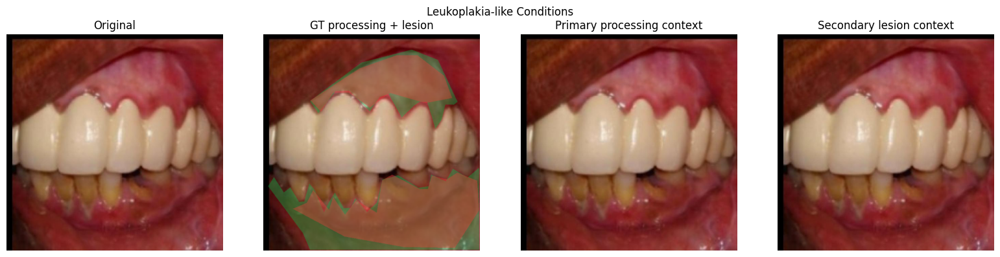

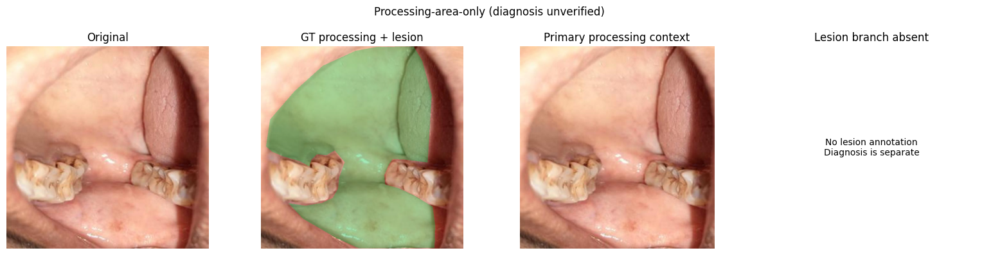

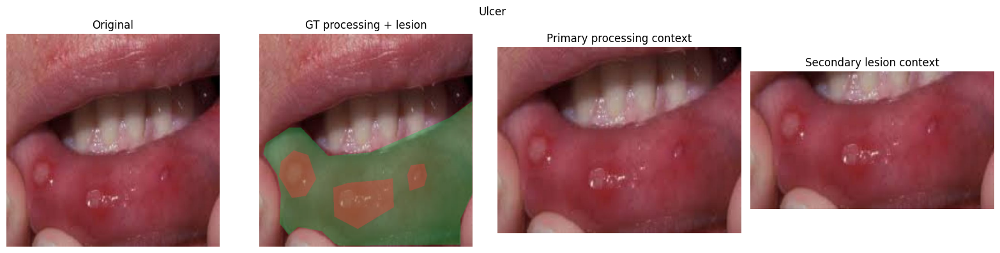


Cell 4 complete.
Classes 0–3 preserved; Ulcers added at ID 4.
Ground-truth masks used; no YOLO inference performed.
Final crop files, split and balancing are still pending.


In [ ]:
# ============================================================
# MODULE 1 — CELL 4
# FREEZE CLASS CONTRACT + GROUND-TRUTH MASK PREVIEW
# No YOLO predictions; no balancing or final split yet.
# ============================================================

from pathlib import Path
from collections import defaultdict
import io
import json
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import display

SOURCE_ZIP = Path(
    "/content/drive/MyDrive/training_dataset/"
    "yolo_dataset-20261001T214553Z-1-001.zip"
)

REPORT_DIR = Path(
    "/content/drive/MyDrive/training_dataset/extra_data/"
    "module_1_dataset/reports"
)

CLASS_NAMES = [
    "Cancer",
    "Leukoplakia",
    "Leukoplakia-like Conditions",
    "Normal Buccal Mucosa",
    "Ulcers",
]

CLASS_TO_INDEX = {
    name: index for index, name in enumerate(CLASS_NAMES)
}

# Source category -> classifier category.
# Processing-area-only is deliberately pending diagnosis confirmation.
SOURCE_TO_CLASS = {
    "Cancer": "Cancer",
    "Leukoplakia": "Leukoplakia",
    "Leukoplakia-like Conditions": "Leukoplakia-like Conditions",
    "Ulcer": "Ulcers",
}

RAW_LESION_NAMES = {
    "cancer-detection",
    "leukoplakia-detection",
    "leukoplakia-like-detection",
    "ulcer-detection",
}

manifest_path = REPORT_DIR / "03_provisional_manifest.csv"
polygons_path = REPORT_DIR / "02_polygon_manifest.json"

for path in (manifest_path, polygons_path, SOURCE_ZIP):
    if not path.is_file():
        raise FileNotFoundError(path)

df = pd.read_csv(manifest_path, keep_default_na=False)

with polygons_path.open("r", encoding="utf-8") as file:
    polygon_records = json.load(file)

polygons_by_image = defaultdict(list)
for record in polygon_records:
    polygons_by_image[record["image_member"]].append(record)

df["classifier_class_name"] = (
    df["source_category"].map(SOURCE_TO_CLASS).fillna("")
)

df["classifier_class_id"] = pd.array(
    [
        CLASS_TO_INDEX[name] if name else pd.NA
        for name in df["classifier_class_name"]
    ],
    dtype="Int64",
)

df["diagnosis_mapping_status"] = np.where(
    df["classifier_class_name"] != "",
    "source_category_mapped_not_clinically_verified",
    "normal_diagnosis_confirmation_pending",
)

# Preserve Cell 3 hold decisions and make pending diagnosis explicit.
df["dataset_stage_status"] = np.where(
    df["preparation_status"] == "hold",
    "technical_or_exact_conflict_hold",
    np.where(
        df["classifier_class_name"] == "",
        "normal_confirmation_pending",
        "mapped_candidate_source_review_pending",
    ),
)

contract = {
    "classifier_class_names": CLASS_NAMES,
    "classifier_class_to_index": CLASS_TO_INDEX,
    "num_classifier_classes": len(CLASS_NAMES),
    "preserved_legacy_class_ids": [0, 1, 2, 3],
    "added_class": {"id": 4, "name": "Ulcers"},
    "primary_roi": "ground_truth_processing_area_context",
    "secondary_roi": "ground_truth_lesion_context_when_available",
    "normal_source_mapping": "pending_user_confirmation",
    "source_category_mapping_is_clinical_verification": False,
    "detector_checkpoint_ids": (
        "Not assigned here; read actual checkpoint names at inference."
    ),
    "final_split_and_balancing_complete": False,
}

with (
    REPORT_DIR / "04_classifier_contract.json"
).open("w", encoding="utf-8") as file:
    json.dump(contract, file, indent=2, ensure_ascii=False)

df.to_csv(
    REPORT_DIR / "04_mapped_candidate_manifest.csv", index=False
)

print("=" * 90)
print("FROZEN CLASSIFIER CLASS CONTRACT")
print("=" * 90)
display(pd.DataFrame({
    "class_id": range(len(CLASS_NAMES)),
    "class_name": CLASS_NAMES,
}))

print("\nCURRENT DATASET STATUS")
display(pd.crosstab(
    df["source_category"], df["dataset_stage_status"]
))

# ---------------- GROUND-TRUTH MASK HELPERS -------------------

def rasterize_mask(records, width, height, accepted_names):
    mask_image = Image.new("L", (width, height), 0)
    drawer = ImageDraw.Draw(mask_image)

    for record in records:
        if record["raw_class_name"] not in accepted_names:
            continue

        # Normalized coordinates -> original-image pixel coordinates.
        points = [
            (
                int(round(min(width - 1, max(0, x * width)))),
                int(round(min(height - 1, max(0, y * height)))),
            )
            for x, y in record["points"]
        ]

        drawer.polygon(points, fill=255)

    return np.asarray(mask_image, dtype=np.uint8)


def padded_mask_bbox(mask, padding_ratio):
    ys, xs = np.where(mask > 0)
    if not len(xs):
        return None

    height, width = mask.shape
    x1, y1 = int(xs.min()), int(ys.min())
    x2, y2 = int(xs.max()) + 1, int(ys.max()) + 1

    pad_x = int(round((x2 - x1) * padding_ratio))
    pad_y = int(round((y2 - y1) * padding_ratio))

    return (
        max(0, x1 - pad_x),
        max(0, y1 - pad_y),
        min(width, x2 + pad_x),
        min(height, y2 + pad_y),
    )


def overlay_mask(rgb, mask, color, alpha=0.35):
    output = rgb.copy()
    selected = mask > 0
    output[selected] = np.clip(
        (1 - alpha) * rgb[selected].astype(np.float32)
        + alpha * np.asarray(color, dtype=np.float32),
        0, 255,
    ).astype(np.uint8)
    return output

# Preview padding only; final ROI settings must match inference.
PROCESSING_PADDING_RATIO = 0.12
LESION_CONTEXT_PADDING_RATIO = 0.30

preview_records = []

with zipfile.ZipFile(SOURCE_ZIP, "r") as archive:
    for category, group in df[
        df["preparation_status"] == "candidate"
    ].groupby("source_category"):

        # Deterministic example; no model-based selection.
        row = group.sort_values("image_member").iloc[0]
        member = row["image_member"]

        with Image.open(io.BytesIO(archive.read(member))) as image:
            rgb = np.asarray(image.convert("RGB"))

        height, width = rgb.shape[:2]
        records = polygons_by_image.get(member, [])

        processing_mask = rasterize_mask(
            records, width, height, {"processing_area"}
        )
        lesion_mask = rasterize_mask(
            records, width, height, RAW_LESION_NAMES
        )

        processing_bbox = padded_mask_bbox(
            processing_mask, PROCESSING_PADDING_RATIO
        )
        lesion_bbox = padded_mask_bbox(
            lesion_mask, LESION_CONTEXT_PADDING_RATIO
        )

        if processing_bbox is None:
            raise RuntimeError(
                f"Candidate has empty rasterized processing mask: {member}"
            )

        x1, y1, x2, y2 = processing_bbox
        processing_crop = rgb[y1:y2, x1:x2]

        fig, axes = plt.subplots(1, 4, figsize=(16, 4))

        axes[0].imshow(rgb)
        axes[0].set_title("Original")

        overlay = overlay_mask(rgb, processing_mask, [0, 200, 80])
        overlay = overlay_mask(overlay, lesion_mask, [255, 60, 60])
        axes[1].imshow(overlay)
        axes[1].set_title("GT processing + lesion")

        axes[2].imshow(processing_crop)
        axes[2].set_title("Primary processing context")

        if lesion_bbox is not None:
            lx1, ly1, lx2, ly2 = lesion_bbox
            axes[3].imshow(rgb[ly1:ly2, lx1:lx2])
            axes[3].set_title("Secondary lesion context")
        else:
            axes[3].text(
                0.5, 0.5,
                "No lesion annotation\nDiagnosis is separate",
                ha="center", va="center",
            )
            axes[3].set_title("Lesion branch absent")

        for axis in axes:
            axis.axis("off")

        fig.suptitle(category, fontsize=12)
        plt.tight_layout()
        plt.show()

        preview_records.append({
            "source_category": category,
            "image_member": member,
            "processing_bbox": processing_bbox,
            "lesion_bbox": lesion_bbox,
            "processing_pixels": int(np.count_nonzero(processing_mask)),
            "lesion_pixels": int(np.count_nonzero(lesion_mask)),
        })

with (
    REPORT_DIR / "04_gt_preview_metadata.json"
).open("w", encoding="utf-8") as file:
    json.dump(preview_records, file, indent=2, ensure_ascii=False)

print("\nCell 4 complete.")
print("Classes 0–3 preserved; Ulcers added at ID 4.")
print("Ground-truth masks used; no YOLO inference performed.")
print("Final crop files, split and balancing are still pending.")

In [ ]:
# ============================================================
# MODULE 1 — CELL 5
# NORMAL MAPPING + GROUP SPLIT + BALANCED TRAIN MANIFEST
# No crops generated yet. Original ZIP remains untouched.
# ============================================================

from pathlib import Path
from collections import defaultdict
import hashlib
import json

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from IPython.display import display

REPORT_DIR = Path(
    "/content/drive/MyDrive/training_dataset/extra_data/"
    "module_1_dataset/reports"
)

SEED = 42

CLASS_NAMES = [
    "Cancer",
    "Leukoplakia",
    "Leukoplakia-like Conditions",
    "Normal Buccal Mucosa",
    "Ulcers",
]

CLASS_TO_INDEX = {
    name: index for index, name in enumerate(CLASS_NAMES)
}

SOURCE_TO_CLASS = {
    "Cancer": "Cancer",
    "Leukoplakia": "Leukoplakia",
    "Leukoplakia-like Conditions": "Leukoplakia-like Conditions",
    "Processing-area-only (diagnosis unverified)":
        "Normal Buccal Mucosa",
    "Ulcer": "Ulcers",
}

manifest_path = REPORT_DIR / "03_provisional_manifest.csv"
review_path = REPORT_DIR / "03_source_review.csv"

if not manifest_path.is_file():
    raise FileNotFoundError("Cell 3 manifest missing.")

df = pd.read_csv(manifest_path, keep_default_na=False)

if df.empty or df["image_member"].duplicated().any():
    raise ValueError("Manifest empty or duplicate image rows detected.")

unknown = set(df["source_category"]) - set(SOURCE_TO_CLASS)
if unknown:
    raise ValueError(f"Unknown source categories: {sorted(unknown)}")

df["class_name"] = df["source_category"].map(SOURCE_TO_CLASS)
df["class_index"] = df["class_name"].map(CLASS_TO_INDEX).astype(int)

# User confirmed doctor-reviewed source labels and Normal source.
# Existing exact-content conflicts remain on hold.
df["label_basis"] = "user_confirmed_doctor_reviewed_source"

# -------------------- OPTIONAL REVIEWED SOURCE GROUPS --------

df["verified_source_group"] = ""

if review_path.is_file():
    review = pd.read_csv(review_path, keep_default_na=False)

    if review["image_member"].duplicated().any():
        raise ValueError("Review CSV has duplicate image rows.")

    if "verified_source_group" in review.columns:
        group_mapping = review.set_index(
            "image_member"
        )["verified_source_group"]

        df["verified_source_group"] = (
            df["image_member"].map(group_mapping).fillna("").str.strip()
        )

    # Do not silently apply diagnosis corrections.
    if "verified_diagnosis" in review.columns:
        entered = review[
            review["verified_diagnosis"].astype(str).str.strip() != ""
        ]
        if not entered.empty:
            original_labels = df.set_index("image_member")["class_name"]
            for _, row in entered.iterrows():
                diagnosis = str(row["verified_diagnosis"]).strip()
                original = original_labels.get(row["image_member"])
                if original is not None and diagnosis != original:
                    raise ValueError(
                        "Review contains a diagnosis correction requiring "
                        "explicit reconciliation:\n"
                        f"{row['image_member']}\n"
                        f"{original} -> {diagnosis}"
                    )

# -------------------- BUILD CONNECTED SOURCE GROUPS -----------

parent = list(range(len(df)))

def find(index):
    while parent[index] != index:
        parent[index] = parent[parent[index]]
        index = parent[index]
    return index

def union(a, b):
    a, b = find(a), find(b)
    if a != b:
        parent[max(a, b)] = min(a, b)

# Group exact-content matches, filename-family candidates and
# manually verified source groups. Filename grouping is conservative:
# it can join unrelated images with the same name.
for column in (
    "exact_content_group",
    "filename_family_candidate",
    "verified_source_group",
):
    first_seen = {}
    for index, value in enumerate(df[column]):
        value = str(value).strip()
        if not value:
            continue
        if value in first_seen:
            union(index, first_seen[value])
        else:
            first_seen[value] = index

components = defaultdict(list)
for index in range(len(df)):
    components[find(index)].append(index)

df["source_group"] = ""
df["selection_status"] = "eligible"
df["selection_reason"] = ""

for indices in components.values():
    members = sorted(df.loc[indices, "image_member"])
    group_id = hashlib.sha256(
        "\n".join(members).encode("utf-8")
    ).hexdigest()[:20]

    df.loc[indices, "source_group"] = group_id

    # This is a review hold, NOT a claim that labels are incorrect.
    if df.loc[indices, "class_name"].nunique() > 1:
        df.loc[indices, "selection_status"] = "hold"
        df.loc[indices, "selection_reason"] = (
            "unresolved_cross_class_source_family_candidate"
        )

technical_hold = df["preparation_status"] == "hold"

df.loc[technical_hold, "selection_status"] = "hold"
df.loc[technical_hold, "selection_reason"] = (
    df.loc[technical_hold, "selection_reason"]
    + " | "
    + df.loc[technical_hold, "preparation_reasons"]
).str.strip(" |")

df.to_csv(
    REPORT_DIR / "05_grouped_source_manifest.csv", index=False
)

df[df["selection_status"] == "hold"].to_csv(
    REPORT_DIR / "05_held_source_manifest.csv", index=False
)

eligible = df[
    df["selection_status"] == "eligible"
].copy().reset_index(drop=True)

if eligible.empty:
    raise RuntimeError("No eligible samples after grouping.")

# Each retained group must have a single classifier label.
if eligible.groupby("source_group")["class_index"].nunique().max() != 1:
    raise RuntimeError("Retained groups contain conflicting class labels.")

group_table = (
    eligible.groupby(
        ["source_group", "class_index", "class_name"],
        as_index=False,
    )
    .agg(images=("image_member", "size"))
)

print("=" * 90)
print("ELIGIBLE SOURCE GROUPS BEFORE SPLITTING")
print("=" * 90)

group_summary = (
    group_table.groupby("class_name")
    .agg(groups=("source_group", "size"), images=("images", "sum"))
    .reindex(CLASS_NAMES, fill_value=0)
)
display(group_summary)

if (group_summary["groups"] < 10).any():
    raise RuntimeError(
        "A class has fewer than 10 eligible source groups. "
        "Review held groups before creating the final split."
    )

# -------------------- PER-CLASS GROUP SPLIT -------------------
# Ratios apply to groups; image ratios can differ slightly.

split_assignments = {}

for class_index in range(len(CLASS_NAMES)):
    class_groups = sorted(
        group_table.loc[
            group_table["class_index"] == class_index,
            "source_group",
        ].tolist()
    )

    train_groups, remaining_groups = train_test_split(
        class_groups,
        test_size=0.30,
        random_state=SEED,
        shuffle=True,
    )

    valid_groups, test_groups = train_test_split(
        remaining_groups,
        test_size=0.50,
        random_state=SEED,
        shuffle=True,
    )

    for split, groups in (
        ("train", train_groups),
        ("valid", valid_groups),
        ("test", test_groups),
    ):
        for group in groups:
            split_assignments[group] = split

eligible["split"] = eligible["source_group"].map(split_assignments)

if eligible["split"].isna().any():
    raise RuntimeError("Some groups did not receive a split.")

train_counts = (
    eligible[eligible["split"] == "train"]["class_index"]
    .value_counts()
    .reindex(range(len(CLASS_NAMES)), fill_value=0)
)

target_per_class = int(train_counts.min())

if target_per_class < 1:
    raise RuntimeError("A training class is empty.")

# -------------------- BALANCE TRAIN ONLY ---------------------
# Sample images within their assigned training groups.
# Every derivative/crop of a selected image will share its split.

eligible["selected"] = True
eligible["selection_reason"] = ""

for class_index in range(len(CLASS_NAMES)):
    class_train = eligible[
        (eligible["split"] == "train")
        & (eligible["class_index"] == class_index)
    ].sort_values("image_member")

    selected_indices = set(
        class_train.sample(
            n=target_per_class,
            random_state=SEED,
        ).index
    )

    excluded_indices = [
        index for index in class_train.index
        if index not in selected_indices
    ]

    eligible.loc[excluded_indices, "selected"] = False
    eligible.loc[excluded_indices, "selection_reason"] = (
        "training_class_balance_downsampling"
    )

selected = eligible[eligible["selected"]].copy()

# -------------------- VERIFY ---------------------------------

for split_a, split_b in (
    ("train", "valid"),
    ("train", "test"),
    ("valid", "test"),
):
    groups_a = set(
        selected.loc[selected["split"] == split_a, "source_group"]
    )
    groups_b = set(
        selected.loc[selected["split"] == split_b, "source_group"]
    )
    if groups_a & groups_b:
        raise RuntimeError(f"Group overlap: {split_a}/{split_b}")

    for hash_column in ("file_sha256", "decoded_rgb_sha256"):
        hashes_a = set(
            selected.loc[selected["split"] == split_a, hash_column]
        ) - {""}
        hashes_b = set(
            selected.loc[selected["split"] == split_b, hash_column]
        ) - {""}
        if hashes_a & hashes_b:
            raise RuntimeError(
                f"Exact-content overlap: {split_a}/{split_b}"
            )

final_train_counts = (
    selected[selected["split"] == "train"]["class_index"]
    .value_counts()
    .reindex(range(len(CLASS_NAMES)), fill_value=0)
)

if not (final_train_counts == target_per_class).all():
    raise RuntimeError("Training classes are not balanced.")

# -------------------- SAVE -----------------------------------

eligible.to_csv(
    REPORT_DIR / "05_split_selection_manifest.csv", index=False
)

selected.to_csv(
    REPORT_DIR / "05_selected_dataset_manifest.csv", index=False
)

eligible[~eligible["selected"]].to_csv(
    REPORT_DIR / "05_balance_excluded_manifest.csv", index=False
)

contract_path = REPORT_DIR / "04_classifier_contract.json"
with contract_path.open("r", encoding="utf-8") as file:
    contract = json.load(file)

if contract["classifier_class_names"] != CLASS_NAMES:
    raise ValueError("Frozen class contract differs from this cell.")

contract.update({
    "normal_source_mapping":
        "user_confirmed_Normal Buccal Mucosa",
    "source_labels_basis": "user_confirmed_doctor_reviewed",
    "split_policy": "70/15/15 per conservative source group",
    "grouping_limitations": (
        "Filename groups are conservative proxies. Patient identifiers "
        "and all visually similar derivatives are not established."
    ),
    "balanced_training_images_per_class": target_per_class,
    "final_split_and_balancing_complete": True,
    "crop_generation_complete": False,
})

with contract_path.open("w", encoding="utf-8") as file:
    json.dump(contract, file, indent=2, ensure_ascii=False)

summary = pd.crosstab(
    selected["class_name"], selected["split"]
).reindex(
    index=CLASS_NAMES,
    columns=["train", "valid", "test"],
    fill_value=0,
)

summary["total"] = summary.sum(axis=1)
summary.to_csv(REPORT_DIR / "05_selected_split_summary.csv")

print("\nSELECTED DATASET — BALANCED TRAINING")
display(summary)

print("\nTraining images per class:", target_per_class)
print("Selected images:", len(selected))
print("Held images:", int((df["selection_status"] == "hold").sum()))
print("Downsampled training images:", int((~eligible["selected"]).sum()))
print("\nReports:", REPORT_DIR)

print("\nCell 5 complete.")
print("Existing class IDs 0–3 unchanged; ID 4 = Ulcers.")
print("Normal source mapped using your confirmation.")
print("No crops generated and no original images deleted.")
print("Group/hash overlap checks passed for this grouping policy.")
print("Patient-level independence is not established by filenames.")

ELIGIBLE SOURCE GROUPS BEFORE SPLITTING


,groups,images
class_name,,
Cancer,196,196
Leukoplakia,234,234
Leukoplakia-like Conditions,196,204
Normal Buccal Mucosa,212,212
Ulcers,119,121



SELECTED DATASET — BALANCED TRAINING


split,train,valid,test,total
class_name,,,,
Cancer,85,29,30,144
Leukoplakia,85,35,36,156
Leukoplakia-like Conditions,85,30,32,147
Normal Buccal Mucosa,85,32,32,149
Ulcers,85,18,18,121



Training images per class: 85
Selected images: 717
Held images: 199
Downsampled training images: 250

Reports: /content/drive/MyDrive/training_dataset/extra_data/module_1_dataset/reports

Cell 5 complete.
Existing class IDs 0–3 unchanged; ID 4 = Ulcers.
Normal source mapped using your confirmation.
No crops generated and no original images deleted.
Group/hash overlap checks passed for this grouping policy.
Patient-level independence is not established by filenames.


In [ ]:
# ============================================================
# MODULE 1 — CELL 6
# GENERATE GROUND-TRUTH CROPS + MASKS + TRAINING MANIFEST
# No YOLO inference. Original ZIP remains untouched.
# ============================================================

from pathlib import Path
from collections import defaultdict
import io
import json
import hashlib
import zipfile

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw
from IPython.display import display

ROOT = Path(
    "/content/drive/MyDrive/training_dataset/extra_data"
)
REPORT_DIR = ROOT / "module_1_dataset/reports"
DATASET_DIR = ROOT / "module_1_dataset/prepared_dataset"

SOURCE_ZIP = Path(
    "/content/drive/MyDrive/training_dataset/"
    "yolo_dataset-20261001T214553Z-1-001.zip"
)

SELECTED_PATH = REPORT_DIR / "05_selected_dataset_manifest.csv"
POLYGON_PATH = REPORT_DIR / "02_polygon_manifest.json"
CONTRACT_PATH = REPORT_DIR / "04_classifier_contract.json"

IMAGE_SIZE = 300
PROCESSING_PADDING_RATIO = 0.12
LESION_CONTEXT_PADDING_RATIO = 0.30

CLASS_NAMES = [
    "Cancer",
    "Leukoplakia",
    "Leukoplakia-like Conditions",
    "Normal Buccal Mucosa",
    "Ulcers",
]

LESION_NAMES = {
    "cancer-detection",
    "leukoplakia-detection",
    "leukoplakia-like-detection",
    "ulcer-detection",
}

for path in (SOURCE_ZIP, SELECTED_PATH, POLYGON_PATH, CONTRACT_PATH):
    if not path.is_file():
        raise FileNotFoundError(path)

selected = pd.read_csv(SELECTED_PATH, keep_default_na=False)

with CONTRACT_PATH.open("r", encoding="utf-8") as file:
    contract = json.load(file)

if contract["classifier_class_names"] != CLASS_NAMES:
    raise ValueError("Frozen class mapping mismatch.")

if not contract.get("final_split_and_balancing_complete"):
    raise RuntimeError("Cell 5 split preparation incomplete.")

if selected.empty or selected["image_member"].duplicated().any():
    raise ValueError("Selected manifest empty or duplicated.")

for _, row in selected.iterrows():
    if row["split"] not in {"train", "valid", "test"}:
        raise ValueError("Unexpected split.")
    class_id = int(row["class_index"])
    if not 0 <= class_id < len(CLASS_NAMES):
        raise ValueError("Invalid classifier class ID.")
    if CLASS_NAMES[class_id] != row["class_name"]:
        raise ValueError("Class name/ID mismatch.")

with POLYGON_PATH.open("r", encoding="utf-8") as file:
    polygons = json.load(file)

by_image = defaultdict(list)
for polygon in polygons:
    by_image[polygon["image_member"]].append(polygon)

# Dedicated generated-data folder only.
# Repeated execution overwrites matching generated files.
# Unexpected stale files cause a verification failure; no deletion.
DATASET_DIR.mkdir(parents=True, exist_ok=True)

# Mark preparation incomplete until generation + verification finish.
contract["crop_generation_complete"] = False
with CONTRACT_PATH.open("w", encoding="utf-8") as file:
    json.dump(contract, file, indent=2, ensure_ascii=False)


def rasterize(records, width, height, accepted_names):
    canvas = Image.new("L", (width, height), 0)
    drawer = ImageDraw.Draw(canvas)

    for record in records:
        if record["raw_class_name"] not in accepted_names:
            continue

        points = [
            (
                int(round(np.clip(x * width, 0, width - 1))),
                int(round(np.clip(y * height, 0, height - 1))),
            )
            for x, y in record["points"]
        ]
        drawer.polygon(points, fill=255)

    return np.asarray(canvas, dtype=np.uint8)


def bbox_from_mask(mask, padding):
    ys, xs = np.where(mask > 0)
    if len(xs) == 0:
        return None

    height, width = mask.shape
    x1, y1 = int(xs.min()), int(ys.min())
    x2, y2 = int(xs.max()) + 1, int(ys.max()) + 1

    px = int(round((x2 - x1) * padding))
    py = int(round((y2 - y1) * padding))

    return [
        max(0, x1 - px),
        max(0, y1 - py),
        min(width, x2 + px),
        min(height, y2 + py),
    ]


def resized_crop(array, bbox, is_mask=False):
    x1, y1, x2, y2 = bbox
    crop = array[y1:y2, x1:x2]

    if crop.size == 0:
        raise ValueError("Empty crop.")

    image = Image.fromarray(crop)
    resampling = (
        Image.Resampling.NEAREST
        if is_mask else Image.Resampling.BILINEAR
    )
    image = image.resize(
        (IMAGE_SIZE, IMAGE_SIZE), resample=resampling
    )

    if is_mask:
        image = Image.fromarray(
            (np.asarray(image) > 127).astype(np.uint8) * 255
        )

    return image


records = []
failures = []
expected_files = set()

with zipfile.ZipFile(SOURCE_ZIP, "r") as archive:
    for position, (_, row) in enumerate(
        selected.sort_values(
            ["split", "class_index", "image_member"]
        ).iterrows(), start=1
    ):
        member = row["image_member"]

        try:
            image_bytes = archive.read(member)

            if hashlib.sha256(image_bytes).hexdigest() != row["file_sha256"]:
                raise ValueError("Source image changed since audit.")

            with Image.open(io.BytesIO(image_bytes)) as image:
                rgb = np.asarray(image.convert("RGB"))

            height, width = rgb.shape[:2]
            annotations = by_image.get(member, [])

            processing_mask = rasterize(
                annotations, width, height, {"processing_area"}
            )
            lesion_mask = rasterize(
                annotations, width, height, LESION_NAMES
            )

            processing_bbox = bbox_from_mask(
                processing_mask, PROCESSING_PADDING_RATIO
            )
            lesion_bbox = bbox_from_mask(
                lesion_mask, LESION_CONTEXT_PADDING_RATIO
            )

            if processing_bbox is None:
                raise ValueError("Ground-truth processing mask is empty.")

            is_normal = int(row["class_index"]) == 3

            if is_normal and lesion_mask.any():
                raise ValueError("Normal sample has a lesion annotation.")

            if not is_normal and lesion_bbox is None:
                raise ValueError("Disease sample has no lesion annotation.")

            lesion_present = int(lesion_bbox is not None)

            # Collision-safe name includes source folder and member hash.
            source_name = Path(row["source_id"]).name
            source_name = "".join(
                c if c.isalnum() else "_" for c in source_name
            )
            member_hash = hashlib.sha256(
                member.encode("utf-8")
            ).hexdigest()[:20]
            stem = f"{source_name}__{member_hash}"

            class_folder = (
                f"{int(row['class_index']):02d}_"
                + row["class_name"].replace(" ", "_")
            )
            destination = (
                DATASET_DIR / row["split"] / class_folder
            )
            destination.mkdir(parents=True, exist_ok=True)

            paths = {
                "processing_roi_path":
                    destination / f"{stem}_processing_rgb.jpg",
                "processing_mask_path":
                    destination / f"{stem}_processing_mask.png",
                "lesion_in_processing_mask_path":
                    destination / f"{stem}_lesion_in_processing_mask.png",
                "lesion_roi_path":
                    destination / f"{stem}_lesion_rgb.jpg",
                "lesion_mask_path":
                    destination / f"{stem}_lesion_mask.png",
            }

            outputs = {
                "processing_roi_path": resized_crop(
                    rgb, processing_bbox
                ),
                "processing_mask_path": resized_crop(
                    processing_mask, processing_bbox, is_mask=True
                ),
                "lesion_in_processing_mask_path": resized_crop(
                    lesion_mask, processing_bbox, is_mask=True
                ),
            }

            if lesion_present:
                outputs["lesion_roi_path"] = resized_crop(
                    rgb, lesion_bbox
                )
                outputs["lesion_mask_path"] = resized_crop(
                    lesion_mask, lesion_bbox, is_mask=True
                )
            else:
                # Consistent file layout for Normal samples.
                # Training must use lesion_present=0 to disable this branch.
                outputs["lesion_roi_path"] = Image.new(
                    "RGB", (IMAGE_SIZE, IMAGE_SIZE), 0
                )
                outputs["lesion_mask_path"] = Image.new(
                    "L", (IMAGE_SIZE, IMAGE_SIZE), 0
                )

            for key, output in outputs.items():
                path = paths[key]
                if path.suffix == ".jpg":
                    output.save(path, quality=95)
                else:
                    output.save(path)

                expected_files.add(path.resolve())

            record = {
                "sample_id": stem,
                "source_image_member": member,
                "source_zip": str(SOURCE_ZIP),
                "source_id": row["source_id"],
                "source_group": row["source_group"],
                "file_sha256": row["file_sha256"],
                "decoded_rgb_sha256": row["decoded_rgb_sha256"],
                "split": row["split"],
                "class_name": row["class_name"],
                "class_index": int(row["class_index"]),
                "lesion_present": lesion_present,
                "processing_bbox": json.dumps(processing_bbox),
                "lesion_bbox": json.dumps(lesion_bbox),
                "processing_source": "ground_truth_annotation",
                "image_size": IMAGE_SIZE,
                **{key: str(path) for key, path in paths.items()},
            }
            records.append(record)

        except Exception as error:
            failures.append({
                "image_member": member,
                "reason": str(error),
            })

        if position % 100 == 0 or position == len(selected):
            print(f"Generated {position}/{len(selected)} samples")

manifest = pd.DataFrame(records)

failure_df = pd.DataFrame(
    failures, columns=["image_member", "reason"]
)
failure_df.to_csv(
    REPORT_DIR / "06_generation_failures.csv", index=False
)

# Save candidate manifest even on failure for diagnosis.
manifest.to_csv(
    REPORT_DIR / "06_generated_roi_manifest.csv", index=False
)

if failures:
    display(failure_df)
    raise RuntimeError(
        "Generation failures found. Dataset is NOT training-ready; "
        "do not continue to training."
    )

if len(manifest) != len(selected):
    raise RuntimeError("Generated sample count mismatch.")

# -------------------- VERIFY SAVED FILES ----------------------

for _, row in manifest.iterrows():
    for column in (
        "processing_roi_path",
        "processing_mask_path",
        "lesion_in_processing_mask_path",
        "lesion_roi_path",
        "lesion_mask_path",
    ):
        with Image.open(row[column]) as image:
            image.load()
            if image.size != (IMAGE_SIZE, IMAGE_SIZE):
                raise RuntimeError(f"Wrong size: {row[column]}")

            array = np.asarray(image)

            if "mask" in column:
                if image.mode != "L":
                    raise RuntimeError("Mask must be single-channel.")
                if not set(np.unique(array)).issubset({0, 255}):
                    raise RuntimeError("Saved mask is not binary.")
                if (
                    int(row["class_index"]) == 3
                    and column != "processing_mask_path"
                    and array.any()
                ):
                    raise RuntimeError("Normal lesion mask is not empty.")
            elif image.mode != "RGB":
                raise RuntimeError("RGB crop has incorrect color mode.")

    with Image.open(row["processing_mask_path"]) as image:
        if not np.asarray(image).any():
            raise RuntimeError("Processing mask vanished after resizing.")

    if int(row["lesion_present"]) == 1:
        with Image.open(row["lesion_mask_path"]) as image:
            if not np.asarray(image).any():
                raise RuntimeError("Lesion mask vanished after resizing.")

actual_files = {
    path.resolve()
    for path in DATASET_DIR.rglob("*")
    if path.is_file()
}

unexpected = actual_files - expected_files
missing = expected_files - actual_files

if unexpected or missing:
    raise RuntimeError(
        "Generated-folder contents do not match this manifest.\n"
        f"Unexpected files: {len(unexpected)}; missing: {len(missing)}.\n"
        "No files deleted. Review folder before proceeding."
    )

train_counts = (
    manifest[manifest["split"] == "train"]["class_index"]
    .value_counts()
    .reindex(range(5), fill_value=0)
)

if (
    (train_counts == 0).any()
    or train_counts.nunique() != 1
):
    raise RuntimeError("Training balance verification failed.")

if manifest.groupby("source_group")["split"].nunique().max() != 1:
    raise RuntimeError("Source group crosses splits.")

# Publish training-ready manifest only after all checks pass.
manifest.to_csv(DATASET_DIR / "manifest.csv", index=False)

contract.update({
    "crop_generation_complete": True,
    "prepared_dataset_dir": str(DATASET_DIR),
    "training_manifest": str(DATASET_DIR / "manifest.csv"),
    "image_size": IMAGE_SIZE,
    "processing_padding_ratio": PROCESSING_PADDING_RATIO,
    "lesion_context_padding_ratio": LESION_CONTEXT_PADDING_RATIO,
    "mask_policy": "union_of_ground_truth_instances_per_class",
    "rgb_resize": "PIL_BILINEAR",
    "mask_resize": "PIL_NEAREST",
    "normal_lesion_branch": "placeholder_RGB_and_empty_mask; presence=0",
})

with CONTRACT_PATH.open("w", encoding="utf-8") as file:
    json.dump(contract, file, indent=2, ensure_ascii=False)

with (DATASET_DIR / "dataset_config.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(contract, file, indent=2, ensure_ascii=False)

summary = pd.crosstab(
    manifest["class_name"], manifest["split"]
).reindex(
    index=CLASS_NAMES,
    columns=["train", "valid", "test"],
    fill_value=0,
)

print("\n" + "=" * 90)
print("GROUND-TRUTH DATASET GENERATED AND VERIFIED")
print("=" * 90)
display(summary)

print("\nSamples:", len(manifest))
print("Files per sample: 5")
print("Dataset:", DATASET_DIR)
print("Training manifest:", DATASET_DIR / "manifest.csv")
print("Generation failures:", len(failure_df))
print("\nCell 6 complete.")

Generated 100/717 samples
Generated 200/717 samples
Generated 300/717 samples
Generated 400/717 samples
Generated 500/717 samples
Generated 600/717 samples
Generated 700/717 samples
Generated 717/717 samples

GROUND-TRUTH DATASET GENERATED AND VERIFIED


split,train,valid,test
class_name,,,
Cancer,85,29,30
Leukoplakia,85,35,36
Leukoplakia-like Conditions,85,30,32
Normal Buccal Mucosa,85,32,32
Ulcers,85,18,18



Samples: 717
Files per sample: 5
Dataset: /content/drive/MyDrive/training_dataset/extra_data/module_1_dataset/prepared_dataset
Training manifest: /content/drive/MyDrive/training_dataset/extra_data/module_1_dataset/prepared_dataset/manifest.csv
Generation failures: 0

Cell 6 complete.


Verified 200/717 samples
Verified 400/717 samples
Verified 600/717 samples
Verified 717/717 samples


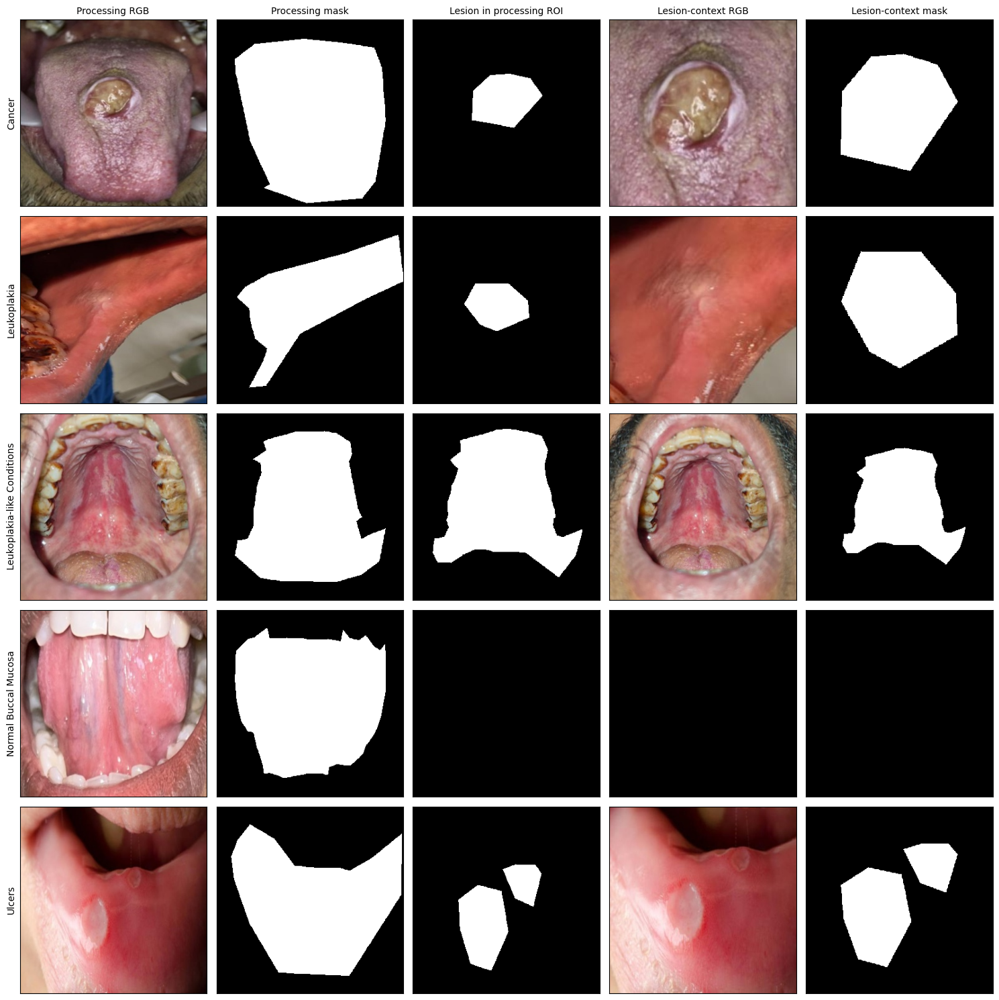


MODULE 1 — STRUCTURAL VERIFICATION COMPLETE


split,train,valid,test
class_name,,,
Cancer,85,29,30
Leukoplakia,85,35,36
Leukoplakia-like Conditions,85,30,32
Normal Buccal Mucosa,85,32,32
Ulcers,85,18,18



Training balanced: True
Images per training class: 85
Train / valid / test: 425 144 148
File errors: 0
Readiness report: /content/drive/MyDrive/training_dataset/extra_data/module_1_dataset/reports/07_dataset_readiness.json

Next stage: Module 2 — classifier training.


In [ ]:
# ============================================================
# MODULE 1 — CELL 7
# FINAL DATASET CHECK + SAVED-CROP PREVIEW
# ============================================================

from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

ROOT = Path(
    "/content/drive/MyDrive/training_dataset/extra_data"
)
DATASET_DIR = ROOT / "module_1_dataset/prepared_dataset"
REPORT_DIR = ROOT / "module_1_dataset/reports"

CLASS_NAMES = [
    "Cancer",
    "Leukoplakia",
    "Leukoplakia-like Conditions",
    "Normal Buccal Mucosa",
    "Ulcers",
]

MANIFEST_PATH = DATASET_DIR / "manifest.csv"
CONFIG_PATH = DATASET_DIR / "dataset_config.json"
READY_PATH = REPORT_DIR / "07_dataset_readiness.json"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

# Invalidate any previous readiness result before checking again.
with READY_PATH.open("w", encoding="utf-8") as file:
    json.dump(
        {"ready_for_training": False, "status": "verification_in_progress"},
        file, indent=2
    )

for path in (MANIFEST_PATH, CONFIG_PATH):
    if not path.is_file():
        raise FileNotFoundError(path)

df = pd.read_csv(MANIFEST_PATH, keep_default_na=False)

with CONFIG_PATH.open("r", encoding="utf-8") as file:
    config = json.load(file)

expected_mapping = {
    name: index for index, name in enumerate(CLASS_NAMES)
}

if config["classifier_class_names"] != CLASS_NAMES:
    raise ValueError("Class names/order mismatch.")

if config["classifier_class_to_index"] != expected_mapping:
    raise ValueError("Class ID mapping mismatch.")

if not config.get("crop_generation_complete"):
    raise RuntimeError("Crop generation is incomplete.")

if df.empty:
    raise ValueError("Dataset manifest is empty.")

required = {
    "sample_id", "source_image_member", "source_group",
    "file_sha256", "decoded_rgb_sha256",
    "split", "class_name", "class_index", "lesion_present",
    "processing_roi_path", "processing_mask_path",
    "lesion_in_processing_mask_path",
    "lesion_roi_path", "lesion_mask_path",
}

missing_columns = required - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing columns: {sorted(missing_columns)}")

for column in ("sample_id", "source_image_member"):
    if df[column].duplicated().any():
        raise ValueError(f"Duplicate values in {column}.")

if not set(df["split"]).issubset({"train", "valid", "test"}):
    raise ValueError("Unexpected split name.")

for _, row in df.iterrows():
    class_id = int(row["class_index"])
    if not 0 <= class_id < len(CLASS_NAMES):
        raise ValueError("Invalid class ID.")
    if row["class_name"] != CLASS_NAMES[class_id]:
        raise ValueError("Class ID/name mismatch.")
    if int(row["lesion_present"]) not in (0, 1):
        raise ValueError("Invalid lesion_present value.")

summary = pd.crosstab(
    df["class_name"], df["split"]
).reindex(
    index=CLASS_NAMES,
    columns=["train", "valid", "test"],
    fill_value=0,
)

if (summary == 0).any().any():
    raise RuntimeError("A class is absent from a split.")

if summary["train"].nunique() != 1:
    raise RuntimeError("Training classes are not balanced.")

# -------------------- SPLIT OVERLAP ---------------------------

overlap_records = []

for key in (
    "source_group",
    "file_sha256",
    "decoded_rgb_sha256",
):
    if (df[key].astype(str).str.strip() == "").any():
        raise ValueError(f"Missing identity/hash values: {key}")

    cross_split = df.groupby(key)["split"].nunique()
    overlapping = cross_split[cross_split > 1]

    overlap_records.append({
        "identity": key,
        "cross_split_groups": len(overlapping),
    })

    if not overlapping.empty:
        raise RuntimeError(f"Cross-split overlap detected: {key}")

# -------------------- VERIFY ALL SAVED FILES ------------------

rgb_columns = ["processing_roi_path", "lesion_roi_path"]
mask_columns = [
    "processing_mask_path",
    "lesion_in_processing_mask_path",
    "lesion_mask_path",
]
path_columns = rgb_columns + mask_columns
expected_size = (int(config["image_size"]),) * 2

all_paths = []
file_errors = []

for position, (_, row) in enumerate(df.iterrows(), start=1):
    for column in path_columns:
        path = Path(row[column])
        all_paths.append(str(path.resolve()))

        try:
            if not path.is_file():
                raise FileNotFoundError(path)

            if not path.resolve().is_relative_to(DATASET_DIR.resolve()):
                raise ValueError("File outside prepared dataset folder.")

            with Image.open(path) as image:
                image.load()

                if image.size != expected_size:
                    raise ValueError(f"Wrong dimensions: {image.size}")

                array = np.asarray(image)

                if column in rgb_columns:
                    if image.mode != "RGB":
                        raise ValueError("Crop is not RGB.")
                else:
                    if image.mode != "L":
                        raise ValueError("Mask is not single-channel.")
                    if not set(np.unique(array)).issubset({0, 255}):
                        raise ValueError("Mask is not binary.")

                    if column == "processing_mask_path" and not array.any():
                        raise ValueError("Empty processing mask.")

                    if int(row["class_index"]) == 3:
                        if (
                            column != "processing_mask_path"
                            and array.any()
                        ):
                            raise ValueError("Normal lesion mask is nonempty.")

                    if (
                        column == "lesion_mask_path"
                        and int(row["lesion_present"]) == 1
                        and not array.any()
                    ):
                        raise ValueError("Present lesion has an empty mask.")

        except Exception as error:
            file_errors.append({
                "sample_id": row["sample_id"],
                "file_role": column,
                "path": str(path),
                "error": str(error),
            })

    if position % 200 == 0 or position == len(df):
        print(f"Verified {position}/{len(df)} samples")

if len(all_paths) != len(set(all_paths)):
    raise RuntimeError("Generated files are shared across sample rows.")

errors_df = pd.DataFrame(
    file_errors,
    columns=["sample_id", "file_role", "path", "error"],
)
errors_df.to_csv(
    REPORT_DIR / "07_file_verification_errors.csv", index=False
)

if file_errors:
    display(errors_df.head(30))
    raise RuntimeError("File verification failed; training not ready.")

normal = df[df["class_index"] == 3]
disease = df[df["class_index"] != 3]

if (normal["lesion_present"].astype(int) != 0).any():
    raise RuntimeError("Normal lesion-present flags are incorrect.")

if (disease["lesion_present"].astype(int) != 1).any():
    raise RuntimeError("Disease samples lack annotated lesion input.")

# -------------------- PREVIEW ACTUAL SAVED FILES --------------

fig, axes = plt.subplots(
    len(CLASS_NAMES), 5,
    figsize=(15, 3 * len(CLASS_NAMES)),
    squeeze=False,
)

titles = [
    "Processing RGB",
    "Processing mask",
    "Lesion in processing ROI",
    "Lesion-context RGB",
    "Lesion-context mask",
]
display_columns = [
    "processing_roi_path",
    "processing_mask_path",
    "lesion_in_processing_mask_path",
    "lesion_roi_path",
    "lesion_mask_path",
]

preview_samples = []

for class_id, class_name in enumerate(CLASS_NAMES):
    row = (
        df[
            (df["split"] == "train")
            & (df["class_index"] == class_id)
        ]
        .sort_values("sample_id")
        .iloc[0]
    )
    preview_samples.append(row["sample_id"])

    for column_index, column in enumerate(display_columns):
        with Image.open(row[column]) as image:
            array = np.asarray(image)

        axis = axes[class_id, column_index]

        if array.ndim == 2:
            axis.imshow(array, cmap="gray", vmin=0, vmax=255)
        else:
            axis.imshow(array)

        axis.set_xticks([])
        axis.set_yticks([])

        if class_id == 0:
            axis.set_title(titles[column_index], fontsize=10)
        if column_index == 0:
            axis.set_ylabel(class_name, fontsize=10)

plt.tight_layout()
plt.show()

# -------------------- SAVE FINAL STATUS ----------------------

summary.to_csv(REPORT_DIR / "07_final_dataset_counts.csv")

readiness = {
    "ready_for_training": True,
    "status": "structural_verification_passed",
    "dataset_dir": str(DATASET_DIR),
    "training_manifest": str(MANIFEST_PATH),
    "class_names": CLASS_NAMES,
    "class_to_index": expected_mapping,
    "image_size": int(config["image_size"]),
    "samples": len(df),
    "train_samples": int(summary["train"].sum()),
    "valid_samples": int(summary["valid"].sum()),
    "test_samples": int(summary["test"].sum()),
    "training_images_per_class": int(summary["train"].iloc[0]),
    "balanced_training": True,
    "file_errors": 0,
    "overlap_checks": overlap_records,
    "preview_sample_ids": preview_samples,
    "limitations": [
        "Patient independence is not established by filename grouping.",
        "Held filename candidates are not confirmed diagnosis errors.",
        "Ground-truth crop checks do not measure predicted-crop performance.",
        "This status verifies files and metadata, not visual clinical quality.",
    ],
}

with READY_PATH.open("w", encoding="utf-8") as file:
    json.dump(readiness, file, indent=2, ensure_ascii=False)

print("\n" + "=" * 90)
print("MODULE 1 — STRUCTURAL VERIFICATION COMPLETE")
print("=" * 90)
display(summary)

print("\nTraining balanced:", True)
print("Images per training class:", int(summary["train"].iloc[0]))
print("Train / valid / test:",
      int(summary["train"].sum()),
      int(summary["valid"].sum()),
      int(summary["test"].sum()))
print("File errors:", len(file_errors))
print("Readiness report:", READY_PATH)
print("\nNext stage: Module 2 — classifier training.")

In [ ]:
# ============================================================
# MODULE 2 — CELL 1
# ENVIRONMENT + DATASET CONTRACT + TRAINING CONFIGURATION
# ============================================================

# Existing PyTorch/NumPy/Pandas ko blindly upgrade nahi karna.
%pip install -q timm scikit-learn

from pathlib import Path
import sys
import json
import random
import platform
import importlib.metadata

import numpy as np
import pandas as pd
import torch
import torchvision
import timm

from google.colab import drive
from IPython.display import display

if not Path("/content/drive/MyDrive").is_dir():
    drive.mount("/content/drive")

ROOT = Path(
    "/content/drive/MyDrive/training_dataset/extra_data"
)

DATASET_DIR = ROOT / "module_1_dataset/prepared_dataset"
DATASET_REPORT_DIR = ROOT / "module_1_dataset/reports"

TRAINING_DIR = ROOT / "module_2_training"
MODEL_DIR = TRAINING_DIR / "models"
TRAINING_REPORT_DIR = TRAINING_DIR / "reports"

for directory in (MODEL_DIR, TRAINING_REPORT_DIR):
    directory.mkdir(parents=True, exist_ok=True)

MANIFEST_PATH = DATASET_DIR / "manifest.csv"
DATASET_CONFIG_PATH = DATASET_DIR / "dataset_config.json"
READINESS_PATH = DATASET_REPORT_DIR / "07_dataset_readiness.json"

# Final model destination.
SAVE_PATH = MODEL_DIR / "ai_c2_best.pt"

CLASS_NAMES = [
    "Cancer",
    "Leukoplakia",
    "Leukoplakia-like Conditions",
    "Normal Buccal Mucosa",
    "Ulcers",
]

CLASS_TO_INDEX = {
    name: index for index, name in enumerate(CLASS_NAMES)
}

# Internal disease-head order; external IDs remain unchanged.
DISEASE_CLASS_IDS = [0, 1, 2, 4]
NORMAL_CLASS_ID = 3

# Keep C1 backbone for a controlled C2 pipeline comparison.
BACKBONE_NAME = "tf_efficientnetv2_b3"
SEED = 42
BATCH_SIZE = 16
NUM_WORKERS = 2

# Proposed settings; best performance must be measured.
HEAD_WARMUP_EPOCHS = 5
MAX_EPOCHS = 80
EARLY_STOPPING_PATIENCE = 12

HEAD_LR = 3e-4
BACKBONE_LR = 1e-5
WEIGHT_DECAY = 1e-4
DROPOUT = 0.30
LESION_BRANCH_DROPOUT = 0.15

# Dataset already balanced: no weighted sampler/weighted loss.
USE_WEIGHTED_SAMPLER = False
USE_CLASS_WEIGHTED_LOSS = False
USE_BLUR_AUGMENTATION = False

for path in (
    MANIFEST_PATH, DATASET_CONFIG_PATH, READINESS_PATH
):
    if not path.is_file():
        raise FileNotFoundError(path)

with READINESS_PATH.open("r", encoding="utf-8") as file:
    readiness = json.load(file)

with DATASET_CONFIG_PATH.open("r", encoding="utf-8") as file:
    dataset_config = json.load(file)

if readiness.get("ready_for_training") is not True:
    raise RuntimeError("Module 1 readiness checks have not passed.")

if not dataset_config.get("crop_generation_complete"):
    raise RuntimeError("Dataset generation is incomplete.")

if (
    dataset_config["classifier_class_names"] != CLASS_NAMES
    or dataset_config["classifier_class_to_index"] != CLASS_TO_INDEX
):
    raise ValueError("Frozen class contract mismatch.")

IMAGE_SIZE = int(dataset_config["image_size"])

manifest_df = pd.read_csv(
    MANIFEST_PATH, keep_default_na=False
)

if len(manifest_df) != int(readiness["samples"]):
    raise ValueError("Manifest count differs from readiness report.")

if manifest_df["sample_id"].duplicated().any():
    raise ValueError("Duplicate sample IDs.")

for _, row in manifest_df.iterrows():
    class_id = int(row["class_index"])
    if not 0 <= class_id < len(CLASS_NAMES):
        raise ValueError("Invalid class ID.")
    if CLASS_NAMES[class_id] != row["class_name"]:
        raise ValueError("Class ID/name mismatch.")

split_counts = pd.crosstab(
    manifest_df["class_name"], manifest_df["split"]
).reindex(
    index=CLASS_NAMES,
    columns=["train", "valid", "test"],
    fill_value=0,
)

if (split_counts == 0).any().any():
    raise RuntimeError("A class is missing from a split.")

if split_counts["train"].nunique() != 1:
    raise RuntimeError("Training dataset is not balanced.")

if (
    manifest_df.groupby("source_group")["split"].nunique().max()
    != 1
):
    raise RuntimeError("Source groups cross splits.")

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU not available. Colab runtime mein GPU select karo."
    )

DEVICE = torch.device("cuda")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

versions = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "timm": timm.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": importlib.metadata.version("scikit-learn"),
}

training_config = {
    "model_id": "ai_c2",
    "backbone": BACKBONE_NAME,
    "architecture_plan": "dual_roi_hierarchical_classifier",
    "class_names": CLASS_NAMES,
    "class_to_index": CLASS_TO_INDEX,
    "normal_class_id": NORMAL_CLASS_ID,
    "disease_head_class_ids": DISEASE_CLASS_IDS,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "head_warmup_epochs": HEAD_WARMUP_EPOCHS,
    "max_epochs": MAX_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "head_lr": HEAD_LR,
    "backbone_lr": BACKBONE_LR,
    "weight_decay": WEIGHT_DECAY,
    "dropout": DROPOUT,
    "lesion_branch_dropout": LESION_BRANCH_DROPOUT,
    "weighted_sampler": USE_WEIGHTED_SAMPLER,
    "class_weighted_loss": USE_CLASS_WEIGHTED_LOSS,
    "blur_augmentation": USE_BLUR_AUGMENTATION,
    "seed": SEED,
    "save_path": str(SAVE_PATH),
    "manifest_path": str(MANIFEST_PATH),
    "dataset_preprocessing": dataset_config,
    "versions": versions,
    "test_policy": "untouched_until_final_model_selection",
}

with (
    TRAINING_REPORT_DIR / "01_training_configuration.json"
).open("w", encoding="utf-8") as file:
    json.dump(training_config, file, indent=2, ensure_ascii=False)

print("=" * 90)
print("MODULE 2 — TRAINING SETUP")
print("=" * 90)

print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory:",
      round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
      "GB")
print("Backbone:", BACKBONE_NAME)
print("Image size:", IMAGE_SIZE)
print("Final best checkpoint:", SAVE_PATH)
print("\nVersions:", versions)

print("\nFROZEN CLASSES")
display(pd.DataFrame({
    "class_id": range(len(CLASS_NAMES)),
    "class_name": CLASS_NAMES,
}))

print("\nDATASET COUNTS")
display(split_counts)

print("\nBalanced training: True")
print("Weighted sampler: False")
print("Class-weighted loss: False")
print("Blur augmentation: False")
print("\nModule 2 Cell 1 complete. Training has not started.")

MODULE 2 — TRAINING SETUP
GPU: NVIDIA A100-SXM4-40GB
GPU memory: 39.49 GB
Backbone: tf_efficientnetv2_b3
Image size: 300
Final best checkpoint: /content/drive/MyDrive/training_dataset/extra_data/module_2_training/models/ai_c2_best.pt

Versions: {'python': '3.13.15', 'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'timm': '1.0.29', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scikit-learn': '1.6.1'}

FROZEN CLASSES


,class_id,class_name
0,0,Cancer
1,1,Leukoplakia
2,2,Leukoplakia-like Conditions
3,3,Normal Buccal Mucosa
4,4,Ulcers



DATASET COUNTS


split,train,valid,test
class_name,,,
Cancer,85,29,30
Leukoplakia,85,35,36
Leukoplakia-like Conditions,85,30,32
Normal Buccal Mucosa,85,32,32
Ulcers,85,18,18



Balanced training: True
Weighted sampler: False
Class-weighted loss: False
Blur augmentation: False

Module 2 Cell 1 complete. Training has not started.


In [ ]:
# ============================================================
# MODULE 2 — CELL 2
# DATALOADERS + DUAL-ROI HIERARCHICAL MODEL + FORWARD CHECK
# ============================================================

import random
import json
import numpy as np

import torch
import torch.nn as nn
import torch.nn.functional as F

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode
from timm.data import resolve_model_data_config

required_variables = [
    "manifest_df", "CLASS_NAMES", "CLASS_TO_INDEX",
    "BACKBONE_NAME", "IMAGE_SIZE", "DEVICE",
    "BATCH_SIZE", "NUM_WORKERS", "SEED", "DROPOUT",
    "LESION_BRANCH_DROPOUT", "TRAINING_REPORT_DIR",
    "training_config",
]

missing = [
    name for name in required_variables
    if name not in globals()
]
if missing:
    raise RuntimeError(f"Module 2 Cell 1 run karo. Missing: {missing}")


# -------------------- MODEL ----------------------------------

class OralScanC2(nn.Module):
    def __init__(
        self,
        backbone_name,
        dropout=0.30,
        pretrained=True,
    ):
        super().__init__()

        self.backbone_name = backbone_name
        self.backbone = timm.create_model(
            backbone_name,
            pretrained=pretrained,
            num_classes=0,
            global_pool="avg",
        )

        feature_dim = self.backbone.num_features

        self.missing_lesion_embedding = nn.Parameter(
            torch.zeros(1, feature_dim)
        )
        nn.init.normal_(
            self.missing_lesion_embedding, std=0.02
        )

        def projection():
            return nn.Sequential(
                nn.LayerNorm(feature_dim),
                nn.Linear(feature_dim, 256),
                nn.SiLU(),
                nn.Dropout(dropout),
            )

        self.processing_projection = projection()
        self.lesion_projection = projection()

        self.lesion_gate = nn.Sequential(
            nn.Linear(feature_dim + 1, 128),
            nn.SiLU(),
            nn.Linear(128, 1),
            nn.Sigmoid(),
        )

        self.fusion = nn.Sequential(
            nn.LayerNorm(513),
            nn.Linear(513, 256),
            nn.SiLU(),
            nn.Dropout(dropout),
        )

        # Binary head: positive logit means abnormal.
        self.abnormal_head = nn.Linear(256, 1)

        # Internal order: Cancer, Leukoplakia,
        # Leukoplakia-like Conditions, Ulcers.
        self.disease_head = nn.Linear(256, 4)

        self.freeze_backbone_bn = True

    def train(self, mode=True):
        super().train(mode)

        # Preserve pretrained BN statistics on this small dataset.
        if mode and self.freeze_backbone_bn:
            for module in self.backbone.modules():
                if isinstance(
                    module, nn.modules.batchnorm._BatchNorm
                ):
                    module.eval()

        return self

    def forward(
        self,
        processing_image,
        lesion_image,
        lesion_present,
    ):
        batch_size = processing_image.size(0)

        presence = lesion_present.reshape(
            batch_size, 1
        ).to(
            device=processing_image.device,
            dtype=processing_image.dtype,
        )

        processing_features = self.backbone(processing_image)

        # Do not send black placeholders through the backbone.
        observed_features = torch.zeros_like(processing_features)
        present_indices = torch.where(
            presence[:, 0] > 0.5
        )[0]

        if present_indices.numel():
            encoded = self.backbone(
                lesion_image.index_select(0, present_indices)
            )
            observed_features = observed_features.index_copy(
                0, present_indices, encoded
            )

        missing_features = (
            self.missing_lesion_embedding
            .to(dtype=processing_features.dtype)
            .expand(batch_size, -1)
        )

        feature_presence = presence.to(
            dtype=processing_features.dtype
        )

        lesion_features = (
            feature_presence * observed_features
            + (1.0 - feature_presence) * missing_features
        )

        gate = self.lesion_gate(
            torch.cat(
                [lesion_features, feature_presence], dim=1
            )
        )

        fused = self.fusion(
            torch.cat(
                [
                    self.processing_projection(processing_features),
                    self.lesion_projection(lesion_features * gate),
                    feature_presence,
                ],
                dim=1,
            )
        )

        # Compute probability composition in FP32 for AMP stability.
        abnormal_logit = self.abnormal_head(fused).squeeze(1).float()
        disease_logits = self.disease_head(fused).float()

        abnormal_log_probability = F.logsigmoid(abnormal_logit)
        normal_log_probability = F.logsigmoid(-abnormal_logit)
        subtype_log_probabilities = F.log_softmax(
            disease_logits, dim=1
        )

        disease_joint = (
            abnormal_log_probability[:, None]
            + subtype_log_probabilities
        )

        # External frozen class order: [0, 1, 2, 3, 4].
        log_probabilities = torch.stack(
            [
                disease_joint[:, 0],
                disease_joint[:, 1],
                disease_joint[:, 2],
                normal_log_probability,
                disease_joint[:, 3],
            ],
            dim=1,
        )

        return {
            "log_probabilities": log_probabilities,
            "probabilities": log_probabilities.exp(),
            "abnormal_logit": abnormal_logit,
            "disease_logits": disease_logits,
            "lesion_gate": gate,
        }


ai_c2_model = OralScanC2(
    backbone_name=BACKBONE_NAME,
    dropout=DROPOUT,
    pretrained=True,
).to(DEVICE)

data_config = resolve_model_data_config(ai_c2_model.backbone)

NORMALIZATION_MEAN = tuple(data_config["mean"])
NORMALIZATION_STD = tuple(data_config["std"])

# Fixed prepared-crop size; no additional center crop.
PREPROCESSING_CONFIG = {
    "image_size": IMAGE_SIZE,
    "mean": NORMALIZATION_MEAN,
    "std": NORMALIZATION_STD,
    "color_mode": "RGB",
    "resize": "bilinear",
    "center_crop": False,
    "blur": False,
}

# -------------------- DATASET --------------------------------

class OralScanC2Dataset(Dataset):
    def __init__(self, dataframe, training=False):
        self.df = dataframe.reset_index(drop=True).copy()
        self.training = training

    def __len__(self):
        return len(self.df)

    @staticmethod
    def read_rgb(path):
        with Image.open(path) as image:
            return image.convert("RGB").copy()

    def __getitem__(self, index):
        row = self.df.iloc[index]

        processing = self.read_rgb(row["processing_roi_path"])
        true_presence = int(row["lesion_present"])
        effective_presence = true_presence

        lesion = (
            self.read_rgb(row["lesion_roi_path"])
            if true_presence else None
        )

        processing = TF.resize(
            processing,
            [IMAGE_SIZE, IMAGE_SIZE],
            interpolation=InterpolationMode.BILINEAR,
        )
        if lesion is not None:
            lesion = TF.resize(
                lesion,
                [IMAGE_SIZE, IMAGE_SIZE],
                interpolation=InterpolationMode.BILINEAR,
            )

        if self.training:
            # Matching augmentation settings on both ROI branches.
            flip = random.random() < 0.5
            angle = random.uniform(-8.0, 8.0)
            brightness = random.uniform(0.90, 1.10)
            contrast = random.uniform(0.90, 1.10)
            saturation = random.uniform(0.95, 1.05)

            def augment(image):
                if flip:
                    image = TF.hflip(image)
                image = TF.rotate(
                    image,
                    angle,
                    interpolation=InterpolationMode.BILINEAR,
                    fill=tuple(
                        int(round(value * 255))
                        for value in NORMALIZATION_MEAN
                    ),
                )
                image = TF.adjust_brightness(image, brightness)
                image = TF.adjust_contrast(image, contrast)
                return TF.adjust_saturation(image, saturation)

            processing = augment(processing)

            if lesion is not None:
                lesion = augment(lesion)

                # Disease samples sometimes train without lesion input.
                # This reduces dependence on successful lesion detection.
                if random.random() < LESION_BRANCH_DROPOUT:
                    lesion = None
                    effective_presence = 0

        processing_tensor = TF.normalize(
            TF.to_tensor(processing),
            NORMALIZATION_MEAN,
            NORMALIZATION_STD,
        )

        lesion_tensor = (
            TF.normalize(
                TF.to_tensor(lesion),
                NORMALIZATION_MEAN,
                NORMALIZATION_STD,
            )
            if lesion is not None
            else torch.zeros(3, IMAGE_SIZE, IMAGE_SIZE)
        )

        return {
            "processing_image": processing_tensor,
            "lesion_image": lesion_tensor,
            "lesion_present": torch.tensor(
                [float(effective_presence)], dtype=torch.float32
            ),
            "true_lesion_present": true_presence,
            "label": torch.tensor(
                int(row["class_index"]), dtype=torch.long
            ),
            "sample_id": row["sample_id"],
            "source_group": row["source_group"],
        }


def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


train_df = manifest_df[
    manifest_df["split"] == "train"
].copy()
valid_df = manifest_df[
    manifest_df["split"] == "valid"
].copy()
test_df = manifest_df[
    manifest_df["split"] == "test"
].copy()

train_dataset = OralScanC2Dataset(train_df, training=True)
valid_dataset = OralScanC2Dataset(valid_df, training=False)

# Test loader intentionally not created/iterated during development.
train_generator = torch.Generator().manual_seed(SEED)
valid_generator = torch.Generator().manual_seed(SEED + 1)

loader_kwargs = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": True,
    "persistent_workers": NUM_WORKERS > 0,
    "worker_init_fn": seed_worker,
    "drop_last": False,
}

train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    generator=train_generator,
    **loader_kwargs,
)
valid_loader = DataLoader(
    valid_dataset,
    shuffle=False,
    generator=valid_generator,
    **loader_kwargs,
)

# Joint likelihood:
# Normal samples train the binary head.
# Disease samples train binary + conditional subtype heads.
def hierarchical_loss(model_output, labels):
    return F.nll_loss(
        model_output["log_probabilities"], labels
    )


# -------------------- FORWARD CHECK ---------------------------
# Synthetic inputs only; final test samples are not used.

ai_c2_model.eval()

dummy_processing = torch.zeros(
    2, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE
)
dummy_lesion = torch.zeros_like(dummy_processing)
dummy_presence = torch.tensor(
    [[1.0], [0.0]], device=DEVICE
)

with torch.inference_mode():
    check = ai_c2_model(
        dummy_processing, dummy_lesion, dummy_presence
    )
    check_loss = hierarchical_loss(
        check,
        torch.tensor([0, 3], device=DEVICE),
    )

    probabilities = check["probabilities"]

    if probabilities.shape != (2, 5):
        raise RuntimeError("Incorrect output shape.")

    if not torch.isfinite(probabilities).all():
        raise RuntimeError("Nonfinite probabilities.")

    if not torch.allclose(
        probabilities.sum(dim=1),
        torch.ones(2, device=DEVICE),
        atol=1e-5,
    ):
        raise RuntimeError("Probabilities do not sum to one.")

    if not torch.isfinite(check_loss):
        raise RuntimeError("Nonfinite loss.")

del dummy_processing, dummy_lesion, dummy_presence, check
torch.cuda.empty_cache()

training_config["preprocessing"] = PREPROCESSING_CONFIG
training_config["freeze_backbone_bn"] = True
training_config["loss"] = "joint_hierarchical_negative_log_likelihood"
training_config["model_class"] = "OralScanC2"
training_config["feature_dimension"] = ai_c2_model.backbone.num_features

with (
    TRAINING_REPORT_DIR / "01_training_configuration.json"
).open("w", encoding="utf-8") as file:
    json.dump(training_config, file, indent=2, ensure_ascii=False)

print("=" * 90)
print("MODULE 2 — DATA + MODEL READY")
print("=" * 90)
print("Train samples:", len(train_dataset))
print("Validation samples:", len(valid_dataset))
print("Test samples reserved:", len(test_df))
print("Train batches:", len(train_loader))
print("Validation batches:", len(valid_loader))
print("Normalization mean:", NORMALIZATION_MEAN)
print("Normalization std:", NORMALIZATION_STD)
print("Output order:", CLASS_NAMES)
print("Forward shape:", tuple(probabilities.shape))
print("Probability sums:", probabilities.sum(dim=1).cpu().tolist())
print("Forward loss finite:", bool(torch.isfinite(check_loss)))
print("Parameters:", sum(p.numel() for p in ai_c2_model.parameters()))
print("\nCell 2 complete. Training has not started.")

model.safetensors: reconstructing file:   0%|          |  0.00B / 57.9MB            

model.safetensors: downloading bytes:           |  0.00B            

MODULE 2 — DATA + MODEL READY
Train samples: 425
Validation samples: 144
Test samples reserved: 148
Train batches: 27
Validation batches: 9
Normalization mean: (0.5, 0.5, 0.5)
Normalization std: (0.5, 0.5, 0.5)
Output order: ['Cancer', 'Leukoplakia', 'Leukoplakia-like Conditions', 'Normal Buccal Mucosa', 'Ulcers']
Forward shape: (2, 5)
Probability sums: [1.0, 1.0]
Forward loss finite: True
Parameters: 13946918

Cell 2 complete. Training has not started.


In [ ]:
# ============================================================
# MODULE 2 — CELL 3
# TRAIN + VALIDATE + EARLY STOP + SAVE BEST CHECKPOINT
# ============================================================

import math
import time
import copy
import json
import os
import random

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
)
from tqdm.auto import tqdm

required = [
    "ai_c2_model", "train_loader", "valid_loader",
    "hierarchical_loss", "training_config",
    "HEAD_WARMUP_EPOCHS", "MAX_EPOCHS",
    "EARLY_STOPPING_PATIENCE", "HEAD_LR", "BACKBONE_LR",
    "WEIGHT_DECAY", "SAVE_PATH", "TRAINING_REPORT_DIR",
    "DEVICE", "CLASS_NAMES", "CLASS_TO_INDEX", "SEED",
]

missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f"Run Module 2 Cells 1–2. Missing: {missing}")

if MAX_EPOCHS <= HEAD_WARMUP_EPOCHS:
    raise ValueError("MAX_EPOCHS must exceed head warmup epochs.")

if SAVE_PATH.exists():
    raise FileExistsError(
        f"A checkpoint already exists:\n{SAVE_PATH}\n"
        "Existing trained model ko overwrite nahi kiya gaya. "
        "New run ke liye Cell 1 mein a different SAVE_PATH set karo."
    )

RUN_PREFIX = SAVE_PATH.stem
HISTORY_PATH = TRAINING_REPORT_DIR / f"{RUN_PREFIX}_history.csv"
SUMMARY_PATH = TRAINING_REPORT_DIR / f"{RUN_PREFIX}_summary.json"

# Separate seed for this training run.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# -------------------- OPTIMIZER -------------------------------

backbone_parameters = list(ai_c2_model.backbone.parameters())
head_parameters = [
    parameter
    for name, parameter in ai_c2_model.named_parameters()
    if not name.startswith("backbone.")
]

# Freeze backbone weights during warmup.
for parameter in backbone_parameters:
    parameter.requires_grad = False

optimizer = torch.optim.AdamW(
    [
        {
            "params": backbone_parameters,
            "lr": BACKBONE_LR,
            "group_name": "backbone",
        },
        {
            "params": head_parameters,
            "lr": HEAD_LR,
            "group_name": "heads",
        },
    ],
    weight_decay=WEIGHT_DECAY,
)

scaler = torch.amp.GradScaler("cuda")
USE_AMP = True

def set_epoch_learning_rates(epoch):
    """Head warmup, then cosine fine-tuning."""
    if epoch <= HEAD_WARMUP_EPOCHS:
        backbone_lr = 0.0
        head_lr = HEAD_LR * (
            0.2 + 0.8 * epoch / HEAD_WARMUP_EPOCHS
        )
    else:
        fine_tune_epochs = MAX_EPOCHS - HEAD_WARMUP_EPOCHS
        progress = (
            epoch - HEAD_WARMUP_EPOCHS - 1
        ) / max(fine_tune_epochs - 1, 1)

        factor = 0.05 + 0.95 * 0.5 * (
            1.0 + math.cos(math.pi * progress)
        )
        backbone_lr = BACKBONE_LR * factor
        head_lr = HEAD_LR * factor

    optimizer.param_groups[0]["lr"] = backbone_lr
    optimizer.param_groups[1]["lr"] = head_lr
    return backbone_lr, head_lr


# -------------------- METRICS ---------------------------------

def compute_metrics(labels, probabilities):
    predictions = probabilities.argmax(axis=1)

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            labels,
            predictions,
            labels=list(range(len(CLASS_NAMES))),
            average=None,
            zero_division=0,
        )
    )

    cm = confusion_matrix(
        labels, predictions,
        labels=list(range(len(CLASS_NAMES))),
    )

    normal_index = CLASS_TO_INDEX["Normal Buccal Mucosa"]
    normal_count = int(cm[normal_index].sum())

    normal_false_disease_rate = (
        float(
            (normal_count - cm[normal_index, normal_index])
            / normal_count
        )
        if normal_count else None
    )

    return {
        "accuracy": float(accuracy_score(labels, predictions)),
        "macro_f1": float(f1.mean()),
        "macro_recall": float(recall.mean()),
        "normal_false_disease_rate": normal_false_disease_rate,
        "per_class_precision": precision.tolist(),
        "per_class_recall": recall.tolist(),
        "per_class_f1": f1.tolist(),
        "support": support.tolist(),
        "confusion_matrix": cm.tolist(),
    }


def run_epoch(training):
    loader = train_loader if training else valid_loader
    ai_c2_model.train(training)

    total_loss = 0.0
    total_samples = 0
    labels_all = []
    probabilities_all = []

    progress = tqdm(
        loader,
        desc="Train" if training else "Valid",
        leave=False,
    )

    context = torch.enable_grad if training else torch.no_grad

    with context():
        for batch in progress:
            processing = batch["processing_image"].to(
                DEVICE, non_blocking=True
            )
            lesion = batch["lesion_image"].to(
                DEVICE, non_blocking=True
            )
            presence = batch["lesion_present"].to(
                DEVICE, non_blocking=True
            )
            labels = batch["label"].to(
                DEVICE, non_blocking=True
            )

            if training:
                optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16,
                enabled=USE_AMP,
            ):
                output = ai_c2_model(
                    processing, lesion, presence
                )
                loss = hierarchical_loss(output, labels)

            if not torch.isfinite(loss):
                raise RuntimeError("Nonfinite loss; training stopped.")

            if training:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)

                torch.nn.utils.clip_grad_norm_(
                    ai_c2_model.parameters(), max_norm=1.0
                )

                scaler.step(optimizer)
                scaler.update()

            count = labels.size(0)
            total_samples += count
            total_loss += float(loss.detach().item()) * count

            labels_all.extend(
                labels.detach().cpu().tolist()
            )
            probabilities_all.append(
                output["probabilities"].detach().float().cpu().numpy()
            )

            progress.set_postfix(loss=f"{loss.item():.4f}")

    labels_array = np.asarray(labels_all, dtype=np.int64)
    probabilities_array = np.concatenate(probabilities_all, axis=0)

    if not np.isfinite(probabilities_array).all():
        raise RuntimeError("Nonfinite prediction probabilities.")

    metrics = compute_metrics(labels_array, probabilities_array)
    metrics["loss"] = total_loss / total_samples

    return metrics


# -------------------- CHECKPOINT ------------------------------

def cpu_state_dict(model):
    return {
        name: tensor.detach().cpu().clone()
        for name, tensor in model.state_dict().items()
    }


def save_best_checkpoint(epoch, validation_metrics, history):
    checkpoint = {
        "model_id": "ai_c2",
        "architecture": "OralScanC2",
        "backbone_name": BACKBONE_NAME,
        "model_state_dict": cpu_state_dict(ai_c2_model),
        "class_names": list(CLASS_NAMES),
        "class_to_index": dict(CLASS_TO_INDEX),
        "num_classes": len(CLASS_NAMES),
        "normal_class_id": 3,
        "disease_head_class_ids": [0, 1, 2, 4],
        "image_size": IMAGE_SIZE,
        "dropout": DROPOUT,
        "preprocessing": copy.deepcopy(
            training_config["preprocessing"]
        ),
        "training_config": copy.deepcopy(training_config),
        "epoch": epoch,
        "best_validation_macro_f1":
            validation_metrics["macro_f1"],
        "validation_metrics": validation_metrics,
        "history": list(history),
        "output_kind": "hierarchical_joint_probabilities",
        "calibrated": False,
        "test_evaluated": False,
        "checkpoint_purpose": "inference_best_validation_model",
    }

    # Save complete checkpoint before replacing final destination.
    temporary_path = SAVE_PATH.with_suffix(".pt.tmp")
    torch.save(checkpoint, temporary_path)
    os.replace(temporary_path, SAVE_PATH)


# -------------------- TRAIN -----------------------------------

history = []
best_f1 = -1.0
best_validation_loss = float("inf")
best_epoch = 0
best_metrics = None
epochs_without_improvement = 0
start_time = time.perf_counter()

print("=" * 90)
print("AI_C2 TRAINING")
print("=" * 90)
print("Selection metric: validation macro-F1")
print("Maximum epochs:", MAX_EPOCHS)
print("Head warmup epochs:", HEAD_WARMUP_EPOCHS)
print("Fine-tuning patience:", EARLY_STOPPING_PATIENCE)
print("Best checkpoint:", SAVE_PATH)
print("Test set: reserved")

for epoch in range(1, MAX_EPOCHS + 1):
    epoch_start = time.perf_counter()

    if epoch == HEAD_WARMUP_EPOCHS + 1:
        for parameter in backbone_parameters:
            parameter.requires_grad = True
        epochs_without_improvement = 0
        print("\nBackbone fine-tuning started; BN statistics remain frozen.")

    backbone_lr, head_lr = set_epoch_learning_rates(epoch)

    train_metrics = run_epoch(training=True)
    valid_metrics = run_epoch(training=False)

    record = {
        "epoch": epoch,
        "stage": (
            "head_warmup"
            if epoch <= HEAD_WARMUP_EPOCHS
            else "fine_tuning"
        ),
        "backbone_lr": backbone_lr,
        "head_lr": head_lr,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "train_macro_f1": train_metrics["macro_f1"],
        "valid_loss": valid_metrics["loss"],
        "valid_accuracy": valid_metrics["accuracy"],
        "valid_macro_f1": valid_metrics["macro_f1"],
        "valid_macro_recall": valid_metrics["macro_recall"],
        "valid_normal_false_disease_rate":
            valid_metrics["normal_false_disease_rate"],
        "seconds": time.perf_counter() - epoch_start,
    }

    for class_id, class_name in enumerate(CLASS_NAMES):
        record[f"valid_recall_class_{class_id}"] = (
            valid_metrics["per_class_recall"][class_id]
        )

    history.append(record)
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    current_f1 = valid_metrics["macro_f1"]
    current_loss = valid_metrics["loss"]

    # Primary metric macro-F1; lower loss breaks exact F1 ties.
    improved = (
        current_f1 > best_f1 + 1e-8
        or (
            abs(current_f1 - best_f1) <= 1e-8
            and current_loss < best_validation_loss - 1e-6
        )
    )

    if improved:
        best_f1 = current_f1
        best_validation_loss = current_loss
        best_epoch = epoch
        best_metrics = copy.deepcopy(valid_metrics)
        epochs_without_improvement = 0

        save_best_checkpoint(epoch, valid_metrics, history)
        marker = " | BEST SAVED"
    else:
        if epoch > HEAD_WARMUP_EPOCHS:
            epochs_without_improvement += 1
        marker = ""

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS}"
        f" | Train loss {train_metrics['loss']:.4f}"
        f" F1 {train_metrics['macro_f1']:.4f}"
        f" | Valid loss {current_loss:.4f}"
        f" F1 {current_f1:.4f}"
        f" Acc {valid_metrics['accuracy']:.4f}"
        f" | Normal→Disease "
        f"{valid_metrics['normal_false_disease_rate']:.3f}"
        f"{marker}"
    )

    # Persist progress summary every epoch.
    training_summary = {
        "model_id": "ai_c2",
        "completed_epochs": epoch,
        "best_epoch": best_epoch,
        "best_validation_macro_f1": best_f1,
        "best_validation_metrics": best_metrics,
        "best_checkpoint": str(SAVE_PATH),
        "elapsed_minutes":
            (time.perf_counter() - start_time) / 60,
        "test_evaluated": False,
        "calibrated": False,
        "training_complete": False,
    }

    with SUMMARY_PATH.open("w", encoding="utf-8") as file:
        json.dump(training_summary, file, indent=2)

    if (
        epoch > HEAD_WARMUP_EPOCHS
        and epochs_without_improvement >= EARLY_STOPPING_PATIENCE
    ):
        print("\nEarly stopping activated.")
        break

# Reload selected weights; do not leave last-epoch weights active.
best_checkpoint = torch.load(
    SAVE_PATH, map_location="cpu", weights_only=False
)

if best_checkpoint["class_names"] != CLASS_NAMES:
    raise RuntimeError("Saved checkpoint class order mismatch.")

ai_c2_model.load_state_dict(
    best_checkpoint["model_state_dict"], strict=True
)
ai_c2_model.to(DEVICE).eval()

training_summary["training_complete"] = True
training_summary["elapsed_minutes"] = (
    time.perf_counter() - start_time
) / 60

with SUMMARY_PATH.open("w", encoding="utf-8") as file:
    json.dump(training_summary, file, indent=2)

print("\n" + "=" * 90)
print("TRAINING COMPLETE — BEST WEIGHTS RELOADED")
print("=" * 90)
print("Best epoch:", best_epoch)
print("Best validation macro-F1:", round(best_f1, 4))
print("Checkpoint:", SAVE_PATH)
print("Training minutes:",
      round(training_summary["elapsed_minutes"], 2))
print("Test evaluated: False")
print("Calibrated: False")

display(pd.DataFrame({
    "class_name": CLASS_NAMES,
    "validation_precision": best_metrics["per_class_precision"],
    "validation_recall": best_metrics["per_class_recall"],
    "validation_f1": best_metrics["per_class_f1"],
    "support": best_metrics["support"],
}))

AI_C2 TRAINING
Selection metric: validation macro-F1
Maximum epochs: 80
Head warmup epochs: 5
Fine-tuning patience: 12
Best checkpoint: /content/drive/MyDrive/training_dataset/extra_data/module_2_training/models/ai_c2_best.pt
Test set: reserved


Train:   0%|          | 0/27 [00:00<?, ?it/s]

Valid:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 01/80 | Train loss 1.3685 F1 0.3973 | Valid loss 0.9345 F1 0.6613 Acc 0.6250 | Normal→Disease 0.000 | BEST SAVED


Train:   0%|          | 0/27 [00:00<?, ?it/s]

Valid:   0%|          | 0/9 [00:00<?, ?it/s]

... (94 outputs left out)

Train:   0%|          | 0/27 [00:00<?, ?it/s]

Valid:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 34/80 | Train loss 0.0005 F1 1.0000 | Valid loss 1.6505 F1 0.7823 Acc 0.7569 | Normal→Disease 0.219

Early stopping activated.

TRAINING COMPLETE — BEST WEIGHTS RELOADED
Best epoch: 22
Best validation macro-F1: 0.8194
Checkpoint: /content/drive/MyDrive/training_dataset/extra_data/module_2_training/models/ai_c2_best.pt
Training minutes: 3.96
Test evaluated: False
Calibrated: False


,class_name,validation_precision,validation_recall,validation_f1,support
0,Cancer,0.818182,0.931034,0.870968,29
1,Leukoplakia,0.638889,0.657143,0.647887,35
2,Leukoplakia-like Conditions,0.689655,0.666667,0.677966,30
3,Normal Buccal Mucosa,0.964286,0.843750,0.900000,32
4,Ulcers,1.000000,1.000000,1.000000,18


In [ ]:
# ============================================================
# MODULE 2 — CELL 4
# FIT TEMPERATURE ON VALIDATION ONLY
# Keeps original best checkpoint unchanged.
# ============================================================

import json
import math
import os
import numpy as np
import torch
import torch.nn.functional as F
from scipy.optimize import minimize_scalar
from tqdm.auto import tqdm

CALIBRATED_PATH = SAVE_PATH.with_name(
    SAVE_PATH.stem + "_calibrated.pt"
)

checkpoint = torch.load(
    SAVE_PATH, map_location="cpu", weights_only=False
)

if checkpoint["class_names"] != CLASS_NAMES:
    raise ValueError("Checkpoint class order mismatch.")

ai_c2_model.load_state_dict(
    checkpoint["model_state_dict"], strict=True
)
ai_c2_model.to(DEVICE).eval()


def collect_predictions(loader, disable_lesion=False):
    log_probabilities = []
    labels = []
    sample_ids = []
    source_groups = []

    ai_c2_model.eval()

    with torch.inference_mode():
        for batch in tqdm(loader, desc="Collecting predictions"):
            processing = batch["processing_image"].to(
                DEVICE, non_blocking=True
            )
            lesion = batch["lesion_image"].to(
                DEVICE, non_blocking=True
            )
            presence = batch["lesion_present"].to(
                DEVICE, non_blocking=True
            )

            if disable_lesion:
                lesion = torch.zeros_like(lesion)
                presence = torch.zeros_like(presence)

            output = ai_c2_model(processing, lesion, presence)

            log_probabilities.append(
                output["log_probabilities"].float().cpu()
            )
            labels.append(batch["label"].cpu())
            sample_ids.extend(batch["sample_id"])
            source_groups.extend(batch["source_group"])

    return {
        "log_probabilities": torch.cat(log_probabilities),
        "labels": torch.cat(labels),
        "sample_ids": sample_ids,
        "source_groups": source_groups,
    }


def calibration_metrics(probabilities, labels, bins=10):
    probabilities = np.asarray(probabilities, dtype=np.float64)
    labels = np.asarray(labels, dtype=np.int64)

    if not np.isfinite(probabilities).all():
        raise ValueError("Nonfinite probabilities.")

    confidence = probabilities.max(axis=1)
    predictions = probabilities.argmax(axis=1)
    correct = predictions == labels

    ece = 0.0
    edges = np.linspace(0, 1, bins + 1)

    for index in range(bins):
        selected = (
            (confidence >= edges[index])
            & (
                confidence <= edges[index + 1]
                if index == bins - 1
                else confidence < edges[index + 1]
            )
        )
        if selected.any():
            ece += float(
                selected.mean()
                * abs(
                    correct[selected].mean()
                    - confidence[selected].mean()
                )
            )

    one_hot = np.eye(len(CLASS_NAMES))[labels]
    brier = np.mean(
        np.sum((probabilities - one_hot) ** 2, axis=1)
    )

    nll = -np.log(
        np.clip(
            probabilities[np.arange(len(labels)), labels],
            1e-12, 1.0,
        )
    ).mean()

    return {
        "nll": float(nll),
        "ece_10_bins": float(ece),
        "multiclass_brier_sum": float(brier),
    }


validation_predictions = collect_predictions(valid_loader)
validation_logp = validation_predictions[
    "log_probabilities"
].double()
validation_labels = validation_predictions["labels"].long()

# Joint five-class temperature scaling.
# softmax(log_joint_probability / T), not division of probabilities.
def validation_objective(log_temperature):
    temperature = math.exp(float(log_temperature))
    return float(
        F.cross_entropy(
            validation_logp / temperature,
            validation_labels,
        ).item()
    )

fit = minimize_scalar(
    validation_objective,
    bounds=(math.log(0.05), math.log(20.0)),
    method="bounded",
    options={"xatol": 1e-5},
)

if not fit.success or not np.isfinite(fit.fun):
    raise RuntimeError("Temperature fitting failed.")

# T=1 is retained if optimization does not improve validation NLL.
baseline_nll = validation_objective(0.0)
TEMPERATURE = (
    math.exp(float(fit.x))
    if fit.fun < baseline_nll
    else 1.0
)

before_probabilities = torch.softmax(
    validation_logp, dim=1
).numpy()
after_probabilities = torch.softmax(
    validation_logp / TEMPERATURE, dim=1
).numpy()

# A positive scalar temperature must preserve class argmax.
if not np.array_equal(
    before_probabilities.argmax(axis=1),
    after_probabilities.argmax(axis=1),
):
    raise RuntimeError("Unexpected prediction change after calibration.")

calibration_report = {
    "temperature": TEMPERATURE,
    "method": "scalar_temperature_on_joint_class_log_probabilities",
    "fit_split": "valid",
    "validation_samples": len(validation_labels),
    "before": calibration_metrics(
        before_probabilities, validation_labels.numpy()
    ),
    "after": calibration_metrics(
        after_probabilities, validation_labels.numpy()
    ),
    "evaluation_procedure": "single_view_dual_roi",
    "tta_used": False,
    "test_used_for_fitting": False,
    "limitation": (
        "Validation also selected the checkpoint; calibration metrics "
        "on this same split are not independent evaluation."
    ),
}

checkpoint["calibrated"] = True
checkpoint["calibration"] = calibration_report
checkpoint["temperature"] = TEMPERATURE
checkpoint["source_best_checkpoint"] = str(SAVE_PATH)

temporary_path = CALIBRATED_PATH.with_suffix(".pt.tmp")
torch.save(checkpoint, temporary_path)
os.replace(temporary_path, CALIBRATED_PATH)

with (
    TRAINING_REPORT_DIR / f"{SAVE_PATH.stem}_calibration.json"
).open("w", encoding="utf-8") as file:
    json.dump(calibration_report, file, indent=2)

print("Temperature:", round(TEMPERATURE, 4))
print("Validation before:", calibration_report["before"])
print("Validation after :", calibration_report["after"])
print("Calibrated checkpoint:", CALIBRATED_PATH)
print("Original best checkpoint preserved:", SAVE_PATH)
print("Test data used: False")
print("Cell 4 complete.")

Temperature: 3.5834
Validation before: {'nll': 1.4108471186750213, 'ece_10_bins': 0.15712169209161062, 'multiclass_brier_sum': 0.36855125150132567}
Validation after : {'nll': 0.6513183990111546, 'ece_10_bins': 0.06981824995743839, 'multiclass_brier_sum': 0.3249807438136714}
Calibrated checkpoint: /content/drive/MyDrive/training_dataset/extra_data/module_2_training/models/ai_c2_best_calibrated.pt
Original best checkpoint preserved: /content/drive/MyDrive/training_dataset/extra_data/module_2_training/models/ai_c2_best.pt
Test data used: False
Cell 4 complete.


FINAL TEST — GROUND-TRUTH DUAL ROI


,precision,recall,f1-score,support
Cancer,0.687500,0.733333,0.709677,30.0
Leukoplakia,0.578947,0.611111,0.594595,36.0
Leukoplakia-like Conditions,0.592593,0.500000,0.542373,32.0
Normal Buccal Mucosa,1.000000,0.968750,0.984127,32.0
Ulcers,0.750000,0.833333,0.789474,18.0



MISSING-LESION ROBUSTNESS CHECK


,mode,accuracy,macro_f1,macro_recall,normal_to_disease_rate
0,Ground-truth dual ROI,0.716216,0.724049,0.729306,0.03125
1,Lesion branch disabled,0.702703,0.701797,0.716944,0.03125



PER-CLASS RECALL WITH LESION BRANCH DISABLED


,class_name,dual_roi_recall,missing_lesion_recall,support
0,Cancer,0.733333,0.800000,30
1,Leukoplakia,0.611111,0.638889,36
2,Leukoplakia-like Conditions,0.500000,0.343750,32
3,Normal Buccal Mucosa,0.968750,0.968750,32
4,Ulcers,0.833333,0.833333,18


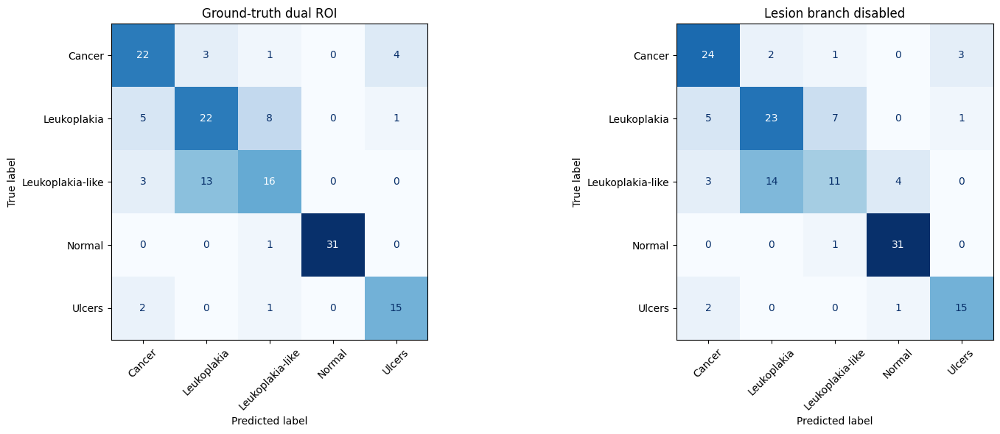


Test accuracy: 0.7162
Test macro-F1: 0.724
Calibration before: {'nll': 1.720516962425929, 'ece_10_bins': 0.23747105876336227, 'multiclass_brier_sum': 0.49902751430325976}
Calibration after : {'nll': 0.7470992107656752, 'ece_10_bins': 0.07759137592605643, 'multiclass_brier_sum': 0.3991684872077762}
Model: /content/drive/MyDrive/training_dataset/extra_data/module_2_training/models/ai_c2_best_calibrated.pt

Cell 5 complete. No model weights changed during test.


In [ ]:
# ============================================================
# MODULE 2 — CELL 5
# FINAL TEST EVALUATION + LESION-BRANCH DISABLED CHECK
# No checkpoint selection or threshold tuning on test.
# ============================================================

from pathlib import Path

CALIBRATED_PATH = Path(
    "/content/drive/MyDrive/training_dataset/extra_data/"
    "module_2_training/models/ai_c2_best_calibrated.pt"
)

if not CALIBRATED_PATH.is_file():
    raise FileNotFoundError(
        "Calibrated checkpoint nahi mila. "
        "Pehle Module 2 Cell 4 successfully run karo, "
        "phir Cell 5 run karo."
    )

import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from IPython.display import display

checkpoint = torch.load(
    CALIBRATED_PATH, map_location="cpu", weights_only=False
)

if (
    checkpoint["class_names"] != CLASS_NAMES
    or not checkpoint.get("calibrated")
):
    raise ValueError("Calibrated checkpoint contract mismatch.")

TEMPERATURE = float(checkpoint["temperature"])

if not np.isfinite(TEMPERATURE) or TEMPERATURE <= 0:
    raise ValueError("Invalid calibration temperature.")

ai_c2_model.load_state_dict(
    checkpoint["model_state_dict"], strict=True
)
ai_c2_model.to(DEVICE).eval()

test_dataset = OralScanC2Dataset(test_df, training=False)

test_loader = DataLoader(
    test_dataset,
    shuffle=False,
    generator=torch.Generator().manual_seed(SEED + 2),
    **loader_kwargs,
)

# Regular ground-truth dual-ROI evaluation.
regular = collect_predictions(test_loader)

# Same images, lesion crop + presence flag disabled.
# Diagnostic ablation, not a separately trained processing-only model.
missing_lesion = collect_predictions(
    test_loader, disable_lesion=True
)

if regular["sample_ids"] != missing_lesion["sample_ids"]:
    raise RuntimeError("Evaluation sample order mismatch.")

labels = regular["labels"].numpy()

regular_raw = torch.softmax(
    regular["log_probabilities"], dim=1
).numpy()

regular_probabilities = torch.softmax(
    regular["log_probabilities"] / TEMPERATURE, dim=1
).numpy()

missing_probabilities = torch.softmax(
    missing_lesion["log_probabilities"] / TEMPERATURE, dim=1
).numpy()

regular_metrics = compute_metrics(
    labels, regular_probabilities
)
missing_metrics = compute_metrics(
    labels, missing_probabilities
)

regular_predictions = regular_probabilities.argmax(axis=1)
missing_predictions = missing_probabilities.argmax(axis=1)

print("=" * 90)
print("FINAL TEST — GROUND-TRUTH DUAL ROI")
print("=" * 90)

class_report = classification_report(
    labels,
    regular_predictions,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

display(
    pd.DataFrame(class_report).T.loc[
        CLASS_NAMES, ["precision", "recall", "f1-score", "support"]
    ]
)

comparison = pd.DataFrame([
    {
        "mode": "Ground-truth dual ROI",
        "accuracy": regular_metrics["accuracy"],
        "macro_f1": regular_metrics["macro_f1"],
        "macro_recall": regular_metrics["macro_recall"],
        "normal_to_disease_rate":
            regular_metrics["normal_false_disease_rate"],
    },
    {
        "mode": "Lesion branch disabled",
        "accuracy": missing_metrics["accuracy"],
        "macro_f1": missing_metrics["macro_f1"],
        "macro_recall": missing_metrics["macro_recall"],
        "normal_to_disease_rate":
            missing_metrics["normal_false_disease_rate"],
    },
])

print("\nMISSING-LESION ROBUSTNESS CHECK")
display(comparison)

missing_class_report = classification_report(
    labels,
    missing_predictions,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)

print("\nPER-CLASS RECALL WITH LESION BRANCH DISABLED")
display(pd.DataFrame({
    "class_name": CLASS_NAMES,
    "dual_roi_recall": regular_metrics["per_class_recall"],
    "missing_lesion_recall": missing_metrics["per_class_recall"],
    "support": regular_metrics["support"],
}))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for axis, predictions, title in (
    (axes[0], regular_predictions, "Ground-truth dual ROI"),
    (axes[1], missing_predictions, "Lesion branch disabled"),
):
    cm = confusion_matrix(
        labels, predictions, labels=list(range(len(CLASS_NAMES)))
    )
    ConfusionMatrixDisplay(
        cm,
        display_labels=[
            "Cancer", "Leukoplakia", "Leukoplakia-like",
            "Normal", "Ulcers",
        ],
    ).plot(
        ax=axis,
        colorbar=False,
        cmap="Blues",
        xticks_rotation=45,
    )
    axis.set_title(title)

plt.tight_layout()
plt.show()

prediction_rows = []

for index, sample_id in enumerate(regular["sample_ids"]):
    row = {
        "sample_id": sample_id,
        "source_group": regular["source_groups"][index],
        "true_class_id": int(labels[index]),
        "true_class_name": CLASS_NAMES[labels[index]],
        "predicted_class_id": int(regular_predictions[index]),
        "predicted_class_name":
            CLASS_NAMES[regular_predictions[index]],
        "confidence": float(regular_probabilities[index].max()),
        "missing_lesion_predicted_class":
            CLASS_NAMES[missing_predictions[index]],
    }

    for class_id, class_name in enumerate(CLASS_NAMES):
        row[f"probability_{class_id}"] = float(
            regular_probabilities[index, class_id]
        )
        row[f"missing_lesion_probability_{class_id}"] = float(
            missing_probabilities[index, class_id]
        )

    prediction_rows.append(row)

pd.DataFrame(prediction_rows).to_csv(
    TRAINING_REPORT_DIR / f"{SAVE_PATH.stem}_test_predictions.csv",
    index=False,
)

report = {
    "checkpoint": str(CALIBRATED_PATH),
    "best_epoch": checkpoint["epoch"],
    "class_names": CLASS_NAMES,
    "temperature": TEMPERATURE,
    "test_samples": len(labels),
    "test_used_for_selection_or_calibration": False,
    "tta_used": False,
    "dual_roi": regular_metrics,
    "lesion_branch_disabled": missing_metrics,
    "calibration_before": calibration_metrics(regular_raw, labels),
    "calibration_after": calibration_metrics(
        regular_probabilities, labels
    ),
    "classification_report": class_report,
    "missing_lesion_classification_report": missing_class_report,
    "limitations": [
        "Reference-annotation crops; not end-to-end YOLO evaluation.",
        "Missing-lesion mode disables both crop and presence signal.",
        "Scalar temperature was fitted to regular dual-ROI validation.",
        "Patient independence is not established.",
        "Test set becomes development evidence if used to redesign model.",
    ],
}

with (
    TRAINING_REPORT_DIR / f"{SAVE_PATH.stem}_test_report.json"
).open("w", encoding="utf-8") as file:
    json.dump(report, file, indent=2)

print("\nTest accuracy:", round(regular_metrics["accuracy"], 4))
print("Test macro-F1:", round(regular_metrics["macro_f1"], 4))
print("Calibration before:", report["calibration_before"])
print("Calibration after :", report["calibration_after"])
print("Model:", CALIBRATED_PATH)
print("\nCell 5 complete. No model weights changed during test.")

In [ ]:
# ============================================================
# MODULE 2 — CELL 6
# LOAD SELECTED Y MODEL + C2 PREDICTED-ROI FUNCTION
# No automatic test evaluation or result-file export.
# ============================================================

%pip install -q ultralytics

from pathlib import Path
import io
import json
import numpy as np
import torch

from PIL import Image, ImageDraw
from torchvision.transforms import functional as TF
from ultralytics import YOLO

CLASSIFIER_PATH = Path(
    "/content/drive/MyDrive/training_dataset/extra_data/"
    "module_2_training/models/ai_c2_best_calibrated.pt"
)

YOLO_MODEL_PATH = Path(
    input("Y2 model ka complete .pt path paste karo: ").strip()
)

if not YOLO_MODEL_PATH.is_file():
    raise FileNotFoundError(YOLO_MODEL_PATH)

if not CLASSIFIER_PATH.is_file():
    raise FileNotFoundError(CLASSIFIER_PATH)

if "OralScanC2" not in globals():
    raise RuntimeError(
        "Model class missing. Module 2 Cell 2 run karo; "
        "training Cell 3 dobara run nahi karna."
    )

c2_checkpoint = torch.load(
    CLASSIFIER_PATH, map_location="cpu", weights_only=False
)

expected_classes = [
    "Cancer",
    "Leukoplakia",
    "Leukoplakia-like Conditions",
    "Normal Buccal Mucosa",
    "Ulcers",
]

if c2_checkpoint["class_names"] != expected_classes:
    raise ValueError("Classifier class contract mismatch.")

c2_inference_model = OralScanC2(
    backbone_name=c2_checkpoint["backbone_name"],
    dropout=c2_checkpoint["dropout"],
    pretrained=False,
).to(DEVICE)

c2_inference_model.load_state_dict(
    c2_checkpoint["model_state_dict"], strict=True
)
c2_inference_model.eval()

y_model = YOLO(str(YOLO_MODEL_PATH))

if y_model.task != "segment":
    raise ValueError("Selected Y checkpoint must be a segmentation model.")

raw_names = y_model.names
detector_names = (
    dict(enumerate(raw_names))
    if isinstance(raw_names, list)
    else {int(key): str(value) for key, value in raw_names.items()}
)

normalized_names = {
    class_id: name.strip().lower().replace("-", "_").replace(" ", "_")
    for class_id, name in detector_names.items()
}

if (
    len(normalized_names) != 2
    or set(normalized_names.values()) != {"processing_area", "lesion"}
):
    raise ValueError(
        f"Expected exactly processing_area and lesion; got {detector_names}"
    )

PROCESSING_ID = next(
    key for key, value in normalized_names.items()
    if value == "processing_area"
)
LESION_ID = next(
    key for key, value in normalized_names.items()
    if value == "lesion"
)

preprocessing = c2_checkpoint["preprocessing"]
roi_policy = c2_checkpoint["training_config"]["dataset_preprocessing"]

C2_SIZE = int(preprocessing["image_size"])
C2_MEAN = tuple(preprocessing["mean"])
C2_STD = tuple(preprocessing["std"])
C2_TEMPERATURE = float(c2_checkpoint["temperature"])

# Initial settings for integration checks; not validated thresholds.
Y_IMAGE_SIZE = 640
Y_CONFIDENCE = 0.25

def c2_mask_bbox(mask, padding):
    ys, xs = np.where(mask > 0)
    if len(xs) == 0:
        return None

    height, width = mask.shape
    x1, y1 = int(xs.min()), int(ys.min())
    x2, y2 = int(xs.max()) + 1, int(ys.max()) + 1
    px = int(round((x2 - x1) * padding))
    py = int(round((y2 - y1) * padding))

    return [
        max(0, x1 - px), max(0, y1 - py),
        min(width, x2 + px), min(height, y2 + py),
    ]


def c2_roi_tensor(rgb, bbox):
    x1, y1, x2, y2 = bbox

    image = Image.fromarray(rgb[y1:y2, x1:x2]).resize(
        (C2_SIZE, C2_SIZE),
        resample=Image.Resampling.BILINEAR,
    )

    # Training RGB crops were JPEG quality=95.
    # Match that preparation in memory; no disk files.
    buffer = io.BytesIO()
    image.save(buffer, format="JPEG", quality=95)
    buffer.seek(0)

    with Image.open(buffer) as saved_image:
        image = saved_image.convert("RGB").copy()

    return TF.normalize(
        TF.to_tensor(image), C2_MEAN, C2_STD
    )


def predict_c2_with_y(image_path, confidence=Y_CONFIDENCE):
    with Image.open(image_path) as image:
        rgb = np.asarray(image.convert("RGB"))

    height, width = rgb.shape[:2]

    # PIL RGB input avoids NumPy RGB/BGR ambiguity.
    result = y_model.predict(
        source=Image.fromarray(rgb),
        imgsz=Y_IMAGE_SIZE,
        conf=confidence,
        device=0 if DEVICE.type == "cuda" else "cpu",
        retina_masks=True,
        verbose=False,
        save=False,
    )[0]

    processing_mask = np.zeros((height, width), dtype=np.uint8)
    lesion_mask = np.zeros_like(processing_mask)
    detections = []

    if result.boxes is not None and len(result.boxes):
        if result.masks is None:
            raise RuntimeError("Detections returned without segmentation masks.")

        if len(result.boxes) != len(result.masks.xy):
            raise RuntimeError("Box/mask count mismatch.")

        for index, polygon in enumerate(result.masks.xy):
            class_id = int(result.boxes.cls[index].item())

            if class_id not in {PROCESSING_ID, LESION_ID}:
                raise ValueError(f"Unexpected detector class ID: {class_id}")

            canvas = Image.new("L", (width, height), 0)

            if len(polygon) >= 3:
                points = [
                    (
                        int(round(np.clip(x, 0, width - 1))),
                        int(round(np.clip(y, 0, height - 1))),
                    )
                    for x, y in polygon
                ]
                ImageDraw.Draw(canvas).polygon(points, fill=255)

            mask = np.asarray(canvas, dtype=np.uint8)

            if class_id == PROCESSING_ID:
                processing_mask = np.maximum(processing_mask, mask)
            else:
                lesion_mask = np.maximum(lesion_mask, mask)

            detections.append({
                "class_id": class_id,
                "class_name": detector_names[class_id],
                "confidence": float(result.boxes.conf[index].item()),
                "bbox": result.boxes.xyxy[index].cpu().tolist(),
                "polygon": polygon.tolist(),
            })

    processing_bbox = c2_mask_bbox(
        processing_mask, roi_policy["processing_padding_ratio"]
    )
    lesion_bbox = c2_mask_bbox(
        lesion_mask, roi_policy["lesion_context_padding_ratio"]
    )

    processing_missing = processing_bbox is None

    if processing_missing:
        processing_bbox = [0, 0, width, height]

    processing_tensor = c2_roi_tensor(rgb, processing_bbox)
    lesion_present = lesion_bbox is not None

    lesion_tensor = (
        c2_roi_tensor(rgb, lesion_bbox)
        if lesion_present
        else torch.zeros(3, C2_SIZE, C2_SIZE)
    )

    with torch.inference_mode():
        output = c2_inference_model(
            processing_tensor.unsqueeze(0).to(DEVICE),
            lesion_tensor.unsqueeze(0).to(DEVICE),
            torch.tensor(
                [[float(lesion_present)]], device=DEVICE
            ),
        )
        probabilities = torch.softmax(
            output["log_probabilities"] / C2_TEMPERATURE,
            dim=1,
        )[0].cpu().numpy()

    predicted_id = int(probabilities.argmax())
    reasons = []

    if processing_missing:
        reasons.append("processing_area_missing_full_image_fallback")

    if predicted_id != 3 and not lesion_present:
        reasons.append("disease_prediction_without_detected_lesion")

    if predicted_id == 3 and lesion_present:
        reasons.append("normal_prediction_with_detected_lesion")

    return {
        "raw_predicted_class": expected_classes[predicted_id],
        "predicted_class_id": predicted_id,
        "top1_probability": float(probabilities[predicted_id]),
        "probabilities": {
            name: float(probabilities[index])
            for index, name in enumerate(expected_classes)
        },
        "lesion_present": lesion_present,
        "processing_source": (
            "full_image_fallback"
            if processing_missing else "predicted_processing_area"
        ),
        "processing_bbox": processing_bbox,
        "lesion_bbox": lesion_bbox,
        "manual_review_required": bool(reasons),
        "reasons": reasons,
        "detections": detections,
        # Arrays retained for the later output/export cell.
        "original_rgb": rgb,
        "processing_mask": processing_mask,
        "lesion_mask": lesion_mask,
    }


print("Classifier:", CLASSIFIER_PATH)
print("Detector:", YOLO_MODEL_PATH)
print("Actual detector classes:", detector_names)
print("Processing ID:", PROCESSING_ID, "| Lesion ID:", LESION_ID)
print("Classifier classes:", expected_classes)
print("Temperature:", C2_TEMPERATURE)
print("\nCell 6 complete. Combined function ready.")
print("No images evaluated or output files generated.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 79.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.5/95.5 kB 10.9 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Y2 model ka complete .pt path paste karo: /content/drive/MyDrive/training_dataset/extra_data/ai_y2.pt
Classifier: /content/drive/MyDrive/training_dataset/extra_data/module_2_training/models/ai_c2_best_calibrated.pt
Detector: /content/drive/MyDrive/training_dataset/extra_data/ai_y2.pt
Actual detector classes: {0: 'processing_area', 1: 'lesion'}
Processing ID: 0 | Lesion ID: 1
Classifier classes: ['Cancer', 'Leukoplakia', 'Leukoplakia-like Conditions', 'Normal Buccal M

Saving image_2026-10-03_051049950.png to image_2026-10-03_051049950.png
COMBINED Y2 + C2 IMAGE CHECK
Image: image_2026-10-03_051049950.png
Raw classifier prediction: Ulcers
Top probability: 93.66%
Top1–top2 margin: 0.9107
Normalized entropy: 0.1987
Lesion detected: True
Processing source: predicted_processing_area
Analysis time: 0.56 seconds

CLASS PROBABILITIES


,class_id,class_name,probability
0,0,Cancer,0.014783
1,1,Leukoplakia,0.013160
2,2,Leukoplakia-like Conditions,0.009594
3,3,Normal Buccal Mucosa,0.025868
4,4,Ulcers,0.936595



DETECTION COUNTS
{'lesion': 1, 'processing_area': 1}

DETECTION DETAILS


,class_id,class_name,confidence,bbox,polygon_points
0,1,lesion,0.910314,"[79.77059936523438, 62.394325256347656, 231.02...",170
1,0,processing_area,0.880877,"[0.0, 0.0, 301.1231994628906, 222.0]",316



Review flags: None
These flags cover missing processing area and conflicting detector/classifier results. Confidence-based review thresholds have not been validated yet.


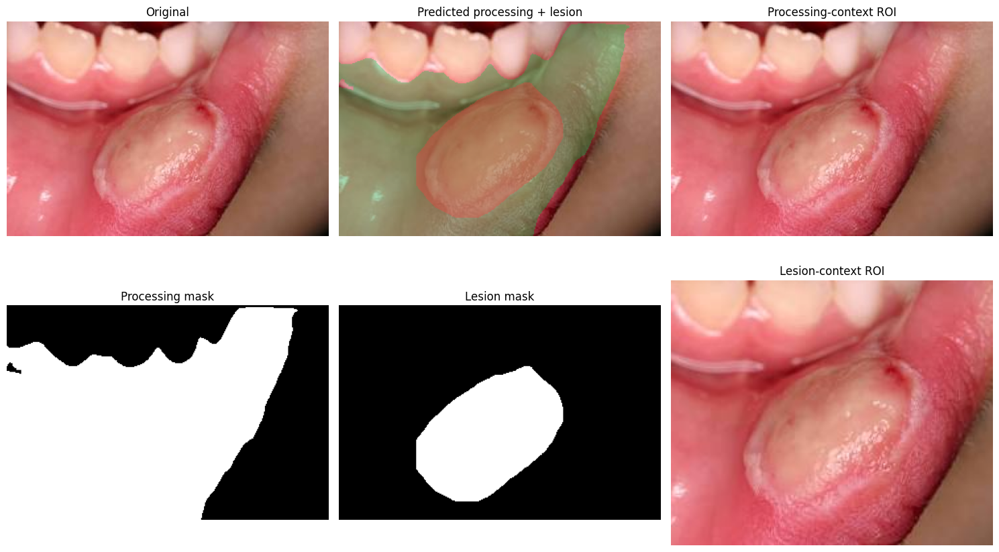


Cell 7 complete.
This single-image check is not an accuracy evaluation.
Prediction remains available in: combined_result


In [ ]:
# ============================================================
# MODULE 2 — CELL 7
# UPLOAD ONE IMAGE + COMBINED Y2/C2 PREDICTION + INLINE PREVIEW
# ============================================================

from pathlib import Path
from collections import Counter
import hashlib
import json
import time
import io

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from google.colab import files
from IPython.display import display

if "predict_c2_with_y" not in globals():
    raise RuntimeError("Pehle Module 2 Cell 6 run karo.")

UPLOAD_DIR = Path(
    "/content/drive/MyDrive/training_dataset/extra_data/"
    "module_2_training/inference_inputs"
)
UPLOAD_DIR.mkdir(parents=True, exist_ok=True)

uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Exactly one image upload karo.")

uploaded_name, uploaded_bytes = next(iter(uploaded.items()))

# Validate before writing to the organized input folder.
with Image.open(io.BytesIO(uploaded_bytes)) as image:
    image.load()

image_hash = hashlib.sha256(uploaded_bytes).hexdigest()
suffix = Path(uploaded_name).suffix.lower() or ".img"
IMAGE_PATH = UPLOAD_DIR / f"{image_hash[:20]}{suffix}"

if IMAGE_PATH.exists():
    if hashlib.sha256(IMAGE_PATH.read_bytes()).hexdigest() != image_hash:
        raise RuntimeError("Unexpected filename collision.")
else:
    IMAGE_PATH.write_bytes(uploaded_bytes)

start = time.perf_counter()
combined_result = predict_c2_with_y(IMAGE_PATH)
elapsed = time.perf_counter() - start

probabilities = combined_result["probabilities"]
ordered = sorted(
    probabilities.items(), key=lambda item: item[1], reverse=True
)

top1 = ordered[0][1]
top2 = ordered[1][1]

values = np.asarray(list(probabilities.values()), dtype=np.float64)
entropy = float(
    -np.sum(values * np.log(np.clip(values, 1e-12, 1.0)))
    / np.log(len(values))
)

print("=" * 90)
print("COMBINED Y2 + C2 IMAGE CHECK")
print("=" * 90)
print("Image:", uploaded_name)
print("Raw classifier prediction:",
      combined_result["raw_predicted_class"])
print("Top probability:", f"{top1:.2%}")
print("Top1–top2 margin:", round(top1 - top2, 4))
print("Normalized entropy:", round(entropy, 4))
print("Lesion detected:", combined_result["lesion_present"])
print("Processing source:", combined_result["processing_source"])
print("Analysis time:", round(elapsed, 3), "seconds")

print("\nCLASS PROBABILITIES")
display(pd.DataFrame({
    "class_id": range(len(expected_classes)),
    "class_name": expected_classes,
    "probability": [
        probabilities[name] for name in expected_classes
    ],
}))

print("\nDETECTION COUNTS")
print(dict(Counter(
    detection["class_name"]
    for detection in combined_result["detections"]
)))

print("\nDETECTION DETAILS")
detection_rows = [
    {
        "class_id": detection["class_id"],
        "class_name": detection["class_name"],
        "confidence": detection["confidence"],
        "bbox": detection["bbox"],
        "polygon_points": len(detection["polygon"]),
    }
    for detection in combined_result["detections"]
]
if detection_rows:
    display(pd.DataFrame(detection_rows))
else:
    print("No detections.")

print("\nReview flags:", combined_result["reasons"] or "None")
print(
    "These flags cover missing processing area and conflicting "
    "detector/classifier results. Confidence-based review thresholds "
    "have not been validated yet."
)

rgb = combined_result["original_rgb"]
processing_mask = combined_result["processing_mask"]
lesion_mask = combined_result["lesion_mask"]

overlay = rgb.astype(np.float32).copy()

for mask, color in (
    (processing_mask, [0, 200, 80]),
    (lesion_mask, [255, 60, 60]),
):
    selected = mask > 0
    overlay[selected] = (
        0.65 * overlay[selected]
        + 0.35 * np.asarray(color, dtype=np.float32)
    )

overlay = np.clip(overlay, 0, 255).astype(np.uint8)

px1, py1, px2, py2 = combined_result["processing_bbox"]
processing_crop = rgb[py1:py2, px1:px2]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

axes[0, 0].imshow(rgb)
axes[0, 0].set_title("Original")

axes[0, 1].imshow(overlay)
axes[0, 1].set_title("Predicted processing + lesion")

axes[0, 2].imshow(processing_crop)
axes[0, 2].set_title("Processing-context ROI")

axes[1, 0].imshow(processing_mask, cmap="gray", vmin=0, vmax=255)
axes[1, 0].set_title("Processing mask")

axes[1, 1].imshow(lesion_mask, cmap="gray", vmin=0, vmax=255)
axes[1, 1].set_title("Lesion mask")

if combined_result["lesion_bbox"] is not None:
    lx1, ly1, lx2, ly2 = combined_result["lesion_bbox"]
    axes[1, 2].imshow(rgb[ly1:ly2, lx1:lx2])
    axes[1, 2].set_title("Lesion-context ROI")
else:
    axes[1, 2].text(
        0.5, 0.5,
        "No lesion detected\nClassification used processing ROI",
        ha="center", va="center",
    )
    axes[1, 2].set_title("Lesion branch absent")

for axis in axes.flat:
    axis.axis("off")

plt.tight_layout()
plt.show()

print("\nCell 7 complete.")
print("This single-image check is not an accuracy evaluation.")
print("Prediction remains available in: combined_result")

In [ ]:
# ============================================================
# MODULE 2 — CELL 8
# INSPECT C1 CHECKPOINT BEFORE FAIR COMPARISON
# Run only for your own trusted checkpoint.
# ============================================================

from pathlib import Path
import torch

C1_PATH = Path(
    "/content/drive/MyDrive/training_dataset/extra_data/"
    "ai_c1 (1).pt"
)

if not C1_PATH.is_file():
    raise FileNotFoundError(C1_PATH)

c1_checkpoint = torch.load(
    C1_PATH,
    map_location="cpu",
    weights_only=False,
)

print("=" * 80)
print("C1 CHECKPOINT INSPECTION")
print("=" * 80)
print("Path:", C1_PATH)
print("Checkpoint type:", type(c1_checkpoint).__name__)

if isinstance(c1_checkpoint, dict):
    print("\nTop-level keys:")
    print(list(c1_checkpoint.keys()))

    metadata_keys = [
        "model_id", "architecture", "backbone_name",
        "class_names", "class_to_index", "num_classes",
        "image_size", "dropout", "dropout_rate",
        "imagenet_mean", "imagenet_std", "preprocessing",
        "epoch", "best_validation_macro_f1",
        "temperature", "calibrated", "model_class",
    ]

    print("\nAVAILABLE METADATA")
    for key in metadata_keys:
        if key in c1_checkpoint:
            print(f"{key}: {c1_checkpoint[key]}")

    state_dict = None
    state_key = None

    for key in ("model_state_dict", "state_dict"):
        candidate = c1_checkpoint.get(key)
        if isinstance(candidate, dict):
            state_dict = candidate
            state_key = key
            break

    if state_dict is None and c1_checkpoint:
        if all(
            torch.is_tensor(value)
            for value in c1_checkpoint.values()
        ):
            state_dict = c1_checkpoint
            state_key = "raw_state_dict"

    if state_dict is not None:
        print("\nWeights container:", state_key)
        print("Parameter/buffer entries:", len(state_dict))

        print("\nFIRST WEIGHT KEYS")
        for key in list(state_dict)[:12]:
            value = state_dict[key]
            print(
                key,
                tuple(value.shape) if torch.is_tensor(value)
                else type(value).__name__,
            )

        print("\nHEAD / FUSION WEIGHT SHAPES")
        for key, value in state_dict.items():
            if (
                torch.is_tensor(value)
                and any(term in key.lower() for term in (
                    "classifier", "fusion", "projection",
                    "gate", "embedding", "head",
                ))
            ):
                print(key, tuple(value.shape))
    else:
        print("\nNo recognized state-dict container.")
        print("Loader must be resolved from this checkpoint format.")

else:
    print(
        "Serialized object checkpoint; architecture loader "
        "needs inspection before comparison."
    )

print("\nCell 8 complete. No predictions performed.")

C1 CHECKPOINT INSPECTION
Path: /content/drive/MyDrive/training_dataset/extra_data/ai_c1 (1).pt
Checkpoint type: dict

Top-level keys:
['model_id', 'architecture', 'model_state_dict', 'epoch', 'stage', 'class_names', 'class_to_index', 'num_classes', 'image_size', 'dropout', 'imagenet_mean', 'imagenet_std', 'best_macro_f1', 'best_medical_score', 'lesion_branch_dropout_probability', 'lesion_replacement_probability', 'learned_missing_lesion_embedding', 'lesion_gate', 'ema_checkpoint', 'history']

AVAILABLE METADATA
model_id: ai_c1_dual_roi_v2
architecture: tf_efficientnetv2_b3
class_names: ['Cancer', 'Leukoplakia', 'Leukoplakia-like Conditions', 'Normal Buccal Mucosa']
class_to_index: {'Cancer': 0, 'Leukoplakia': 1, 'Leukoplakia-like Conditions': 2, 'Normal Buccal Mucosa': 3}
num_classes: 4
image_size: 300
dropout: 0.35
imagenet_mean: (0.485, 0.456, 0.406)
imagenet_std: (0.229, 0.224, 0.225)
epoch: 34

Weights container: model_state_dict
Parameter/buffer entries: 643

FIRST WEIGHT KEYS
mis

In [ ]:
# CELL 9 — C1 DUAL-ROI V2: EXACT MODEL LOADING

from pathlib import Path
import torch
import torch.nn as nn
import timm

C1_PATH = Path(
    "/content/drive/MyDrive/training_dataset/extra_data/ai_c1 (1).pt"
)

if not C1_PATH.is_file():
    raise FileNotFoundError(f"C1 checkpoint nahi mila: {C1_PATH}")

c1_checkpoint = torch.load(
    C1_PATH, map_location="cpu", weights_only=False
)

C1_CLASSES = [
    "Cancer",
    "Leukoplakia",
    "Leukoplakia-like Conditions",
    "Normal Buccal Mucosa",
]

assert c1_checkpoint["model_id"] == "ai_c1_dual_roi_v2"
assert list(c1_checkpoint["class_names"]) == C1_CLASSES
assert c1_checkpoint["class_to_index"] == {
    name: index for index, name in enumerate(C1_CLASSES)
}
assert int(c1_checkpoint["num_classes"]) == 4


class ImprovedDualROIEfficientNet(nn.Module):
    def __init__(
        self, architecture, num_classes,
        dropout=0.35, pretrained=False
    ):
        super().__init__()

        self.backbone = timm.create_model(
            architecture,
            pretrained=pretrained,
            num_classes=0,
            global_pool="avg",
        )

        feature_dimension = self.backbone.num_features

        self.missing_lesion_embedding = nn.Parameter(
            torch.zeros(1, feature_dimension)
        )

        self.processing_projection = nn.Sequential(
            nn.LayerNorm(feature_dimension),
            nn.Linear(feature_dimension, 512),
            nn.SiLU(),
            nn.Dropout(dropout),
        )

        self.lesion_projection = nn.Sequential(
            nn.LayerNorm(feature_dimension),
            nn.Linear(feature_dimension, 512),
            nn.SiLU(),
            nn.Dropout(dropout),
        )

        self.lesion_gate = nn.Sequential(
            nn.Linear(feature_dimension + 1, 256),
            nn.SiLU(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(256, 1),
            nn.Sigmoid(),
        )

        self.fusion_head = nn.Sequential(
            nn.LayerNorm(1025),
            nn.Dropout(dropout),
            nn.Linear(1025, 512),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(512, num_classes),
        )

    def forward(
        self, processing_image, lesion_image, lesion_present
    ):
        presence = lesion_present.reshape(-1, 1).to(
            device=processing_image.device,
            dtype=processing_image.dtype,
        )

        processing_features = self.backbone(processing_image)
        observed_lesion_features = self.backbone(lesion_image)

        missing_features = self.missing_lesion_embedding.expand(
            processing_image.shape[0], -1
        )

        lesion_features = (
            presence * observed_lesion_features
            + (1.0 - presence) * missing_features
        )

        gate = self.lesion_gate(
            torch.cat([lesion_features, presence], dim=1)
        )

        fused_features = torch.cat(
            [
                self.processing_projection(processing_features),
                self.lesion_projection(lesion_features * gate),
                presence,
            ],
            dim=1,
        )

        return self.fusion_head(fused_features)


C1_DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

c1_model = ImprovedDualROIEfficientNet(
    architecture=c1_checkpoint["architecture"],
    num_classes=4,
    dropout=float(c1_checkpoint["dropout"]),
    pretrained=False,
)

# Missing/unexpected weights par error aayega; silent loading nahi hogi.
c1_model.load_state_dict(
    c1_checkpoint["model_state_dict"], strict=True
)
c1_model = c1_model.to(C1_DEVICE).eval()

C1_IMAGE_SIZE = int(c1_checkpoint["image_size"])
C1_MEAN = tuple(c1_checkpoint["imagenet_mean"])
C1_STD = tuple(c1_checkpoint["imagenet_std"])

# Shape/finite-output check — dataset evaluation nahi hai.
with torch.inference_mode():
    dummy = torch.zeros(
        2, 3, C1_IMAGE_SIZE, C1_IMAGE_SIZE,
        device=C1_DEVICE,
    )
    presence = torch.tensor(
        [[1.0], [0.0]], device=C1_DEVICE
    )

    logits = c1_model(dummy, dummy, presence)
    probabilities = logits.softmax(dim=1)

assert tuple(logits.shape) == (2, 4)
assert torch.isfinite(logits).all().item()
assert torch.allclose(
    probabilities.sum(dim=1),
    torch.ones(2, device=C1_DEVICE),
    atol=1e-5,
)

print("=" * 80)
print("C1 DUAL-ROI V2 — LOADED AND VERIFIED")
print("=" * 80)
print("Checkpoint:", C1_PATH)
print("Device:", C1_DEVICE)
print("Strict weight loading: PASSED")
print("Processing ROI + lesion ROI: YES")
print("Missing-lesion embedding: YES")
print("Image size:", C1_IMAGE_SIZE)
print("Normalization mean:", C1_MEAN)
print("Normalization std:", C1_STD)
print("Class order:", C1_CLASSES)
print("Forward shape:", tuple(logits.shape))
print("Finite outputs: True")
print("Cell 9 complete. Test images abhi evaluate nahi hui.")

C1 DUAL-ROI V2 — LOADED AND VERIFIED
Checkpoint: /content/drive/MyDrive/training_dataset/extra_data/ai_c1 (1).pt
Device: cuda
Strict weight loading: PASSED
Processing ROI + lesion ROI: YES
Missing-lesion embedding: YES
Image size: 300
Normalization mean: (0.485, 0.456, 0.406)
Normalization std: (0.229, 0.224, 0.225)
Class order: ['Cancer', 'Leukoplakia', 'Leukoplakia-like Conditions', 'Normal Buccal Mucosa']
Forward shape: (2, 4)
Finite outputs: True
Cell 9 complete. Test images abhi evaluate nahi hui.


In [ ]:
# CELL 10 — C1 vs C2 ON SAME TEST IMAGES + SAME Y2 ROIs

import io
import json
import zipfile
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix
)
from torchvision.transforms import functional as TF
from IPython.display import display

ROOT = Path("/content/drive/MyDrive/training_dataset/extra_data")
MANIFEST_PATH = ROOT / "module_1_dataset/prepared_dataset/manifest.csv"
COMPARISON_DIR = ROOT / "module_2_training/reports/c1_vs_c2"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

for required in ["c1_model", "predict_c2_with_y"]:
    if required not in globals():
        raise RuntimeError(f"Pehle model-loading cell run karo: {required}")

CLASS_NAMES = C1_CLASSES + ["Ulcers"]

manifest = pd.read_csv(MANIFEST_PATH)
test_rows = manifest.loc[manifest["split"] == "test"].copy()
test_rows = test_rows.sort_values("sample_id").reset_index(drop=True)

assert len(test_rows) > 0, "Test manifest empty hai."
assert set(test_rows["class_index"].astype(int)) == set(range(5))

c1_model.eval()


def comparison_c1_tensor(rgb, bbox):
    """Same crop/resize/JPEG policy as current C2 inference;
       C1 checkpoint ki normalization."""
    crop = Image.fromarray(rgb).crop(tuple(map(int, bbox)))
    crop = crop.resize(
        (C1_IMAGE_SIZE, C1_IMAGE_SIZE),
        Image.Resampling.BILINEAR,
    )

    buffer = io.BytesIO()
    crop.save(buffer, format="JPEG", quality=95)
    buffer.seek(0)

    with Image.open(buffer) as image:
        tensor = TF.to_tensor(image.convert("RGB"))

    return TF.normalize(tensor, C1_MEAN, C1_STD)


records = []
archives = {}

print("Test images:", len(test_rows))
print("Y2 inference once per image; same ROIs for both classifiers.")
print("C1 probabilities: uncalibrated")
print("C2 probabilities: existing calibrated inference")

try:
    for position, row in test_rows.iterrows():
        zip_path = str(row["source_zip"])

        if zip_path not in archives:
            if not Path(zip_path).is_file():
                raise FileNotFoundError(f"Source ZIP missing: {zip_path}")
            archives[zip_path] = zipfile.ZipFile(zip_path)

        image_bytes = archives[zip_path].read(
            str(row["source_image_member"])
        )

        # Existing combined function performs Y2 + C2 inference.
        result = predict_c2_with_y(io.BytesIO(image_bytes))

        rgb = result["original_rgb"]
        processing_bbox = result["processing_bbox"]

        # Same full-image fallback, if processing area is absent.
        if processing_bbox is None:
            height, width = rgb.shape[:2]
            processing_bbox = (0, 0, width, height)

        processing = comparison_c1_tensor(rgb, processing_bbox)
        lesion_present = bool(result["lesion_present"])

        if lesion_present:
            if result["lesion_bbox"] is None:
                raise RuntimeError("Lesion present but bbox missing.")
            lesion = comparison_c1_tensor(rgb, result["lesion_bbox"])
        else:
            # Presence=0 makes C1 use its learned missing embedding.
            lesion = torch.zeros_like(processing)

        with torch.inference_mode():
            logits = c1_model(
                processing.unsqueeze(0).to(C1_DEVICE),
                lesion.unsqueeze(0).to(C1_DEVICE),
                torch.tensor(
                    [[float(lesion_present)]],
                    device=C1_DEVICE,
                ),
            )
            c1_probabilities = logits.softmax(dim=1)[0].cpu().numpy()

        c1_prediction = int(c1_probabilities.argmax())
        c2_prediction = int(result["predicted_class_id"])
        actual = int(row["class_index"])

        record = {
            "sample_id": row["sample_id"],
            "source_image_member": row["source_image_member"],
            "true_id": actual,
            "true_class": CLASS_NAMES[actual],
            "c1_predicted_id": c1_prediction,
            "c1_predicted_class": CLASS_NAMES[c1_prediction],
            "c2_predicted_id": c2_prediction,
            "c2_predicted_class": CLASS_NAMES[c2_prediction],
            "c1_correct": c1_prediction == actual,
            "c2_correct": c2_prediction == actual,
            "y2_lesion_present": lesion_present,
            "processing_source": result["processing_source"],
            "c2_manual_review_required": result["manual_review_required"],
        }

        for index, name in enumerate(CLASS_NAMES):
            record[f"c1_probability_{index}"] = (
                float(c1_probabilities[index]) if index < 4 else np.nan
            )
            record[f"c2_probability_{index}"] = float(
                result["probabilities"][name]
            )

        records.append(record)

        if (position + 1) % 25 == 0 or position + 1 == len(test_rows):
            print(f"Compared {position + 1}/{len(test_rows)}")

finally:
    for archive in archives.values():
        archive.close()

results = pd.DataFrame(records)
results.to_csv(COMPARISON_DIR / "per_image_predictions.csv", index=False)

# Shared classes only; C2's Ulcers predictions remain errors.
shared = results.loc[results["true_id"] < 4].copy()
ulcers = results.loc[results["true_id"] == 4].copy()

summary_rows = []
per_class_tables = []

for model_name, prediction_column in [
    ("C1 Dual-ROI V2", "c1_predicted_id"),
    ("C2", "c2_predicted_id"),
]:
    truth = shared["true_id"].to_numpy()
    prediction = shared[prediction_column].to_numpy()

    report = classification_report(
        truth, prediction,
        labels=[0, 1, 2, 3],
        target_names=C1_CLASSES,
        output_dict=True,
        zero_division=0,
    )

    normal_rows = shared.loc[shared["true_id"] == 3]
    normal_to_disease = (
        float((normal_rows[prediction_column] != 3).mean())
        if len(normal_rows) else None
    )

    summary_rows.append({
        "model": model_name,
        "shared_test_images": len(shared),
        "accuracy": accuracy_score(truth, prediction),
        "macro_f1": f1_score(
            truth, prediction,
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0,
        ),
        "macro_recall": report["macro avg"]["recall"],
        "normal_to_disease_rate": normal_to_disease,
    })

    table = pd.DataFrame([
        {"model": model_name, "class_name": name, **report[name]}
        for name in C1_CLASSES
    ])
    per_class_tables.append(table)

    # Fifth column retains C2 Ulcers predictions on shared classes.
    matrix = confusion_matrix(
        truth, prediction, labels=[0, 1, 2, 3, 4]
    )
    matrix_table = pd.DataFrame(
        matrix[:4, :],
        index=C1_CLASSES,
        columns=CLASS_NAMES,
    )
    filename = "c1" if model_name.startswith("C1") else "c2"
    matrix_table.to_csv(COMPARISON_DIR / f"{filename}_confusion_shared.csv")

comparison_summary = pd.DataFrame(summary_rows)
per_class = pd.concat(per_class_tables, ignore_index=True)

comparison_summary.to_csv(COMPARISON_DIR / "shared_class_summary.csv", index=False)
per_class.to_csv(COMPARISON_DIR / "shared_class_metrics.csv", index=False)

paired = pd.DataFrame({
    "outcome": [
        "Both correct", "Only C1 correct",
        "Only C2 correct", "Both incorrect"
    ],
    "images": [
        int((shared.c1_correct & shared.c2_correct).sum()),
        int((shared.c1_correct & ~shared.c2_correct).sum()),
        int((~shared.c1_correct & shared.c2_correct).sum()),
        int((~shared.c1_correct & ~shared.c2_correct).sum()),
    ],
})

print("\n" + "=" * 80)
print("SHARED FOUR-CLASS COMPARISON — SAME Y2 ROIs")
print("=" * 80)
display(comparison_summary)
display(per_class)
display(paired)

print("\nULCERS — C1 HAS NO ULCERS OUTPUT CLASS")
print("Ulcers test images:", len(ulcers))
print(
    "C2 Ulcers recall:",
    float(ulcers["c2_correct"].mean()) if len(ulcers) else "N/A"
)
print("C1 assigned these Ulcers images to:")
display(ulcers["c1_predicted_class"].value_counts().rename("images"))

print("\nY2 processing-area full-image fallbacks:")
display(results["processing_source"].value_counts().rename("images"))

print("\nReports:", COMPARISON_DIR)
print("Cell 10 complete.")
print("C1/Y2 training overlap with these test images remains unverified.")

Test images: 148
Y2 inference once per image; same ROIs for both classifiers.
C1 probabilities: uncalibrated
C2 probabilities: existing calibrated inference
Compared 25/148
Compared 50/148
Compared 75/148
Compared 100/148
Compared 125/148
Compared 148/148

SHARED FOUR-CLASS COMPARISON — SAME Y2 ROIs


,model,shared_test_images,accuracy,macro_f1,macro_recall,normal_to_disease_rate
0,C1 Dual-ROI V2,130,0.661538,0.656599,0.667535,0.31250
1,C2,130,0.707692,0.713607,0.709896,0.03125


,model,class_name,precision,recall,f1-score,support
0,C1 Dual-ROI V2,Cancer,0.468750,1.000000,0.638298,30.0
1,C1 Dual-ROI V2,Leukoplakia,0.718750,0.638889,0.676471,36.0
2,C1 Dual-ROI V2,Leukoplakia-like Conditions,1.000000,0.343750,0.511628,32.0
3,C1 Dual-ROI V2,Normal Buccal Mucosa,0.956522,0.687500,0.800000,32.0
4,C2,Cancer,0.741935,0.766667,0.754098,30.0
5,C2,Leukoplakia,0.600000,0.666667,0.631579,36.0
6,C2,Leukoplakia-like Conditions,0.583333,0.437500,0.500000,32.0
7,C2,Normal Buccal Mucosa,0.968750,0.968750,0.968750,32.0


,outcome,images
0,Both correct,66
1,Only C1 correct,20
2,Only C2 correct,26
3,Both incorrect,18



ULCERS — C1 HAS NO ULCERS OUTPUT CLASS
Ulcers test images: 18
C2 Ulcers recall: 0.8333333333333334
C1 assigned these Ulcers images to:


,images
c1_predicted_class,
Cancer,12
Leukoplakia,4
Normal Buccal Mucosa,2



Y2 processing-area full-image fallbacks:


,images
processing_source,
predicted_processing_area,148



Reports: /content/drive/MyDrive/training_dataset/extra_data/module_2_training/reports/c1_vs_c2
Cell 10 complete.
C1/Y2 training overlap with these test images remains unverified.


In [ ]:
# CELL 11 — C2 ERROR AUDIT (NO RETRAINING)

from pathlib import Path
import pandas as pd
from IPython.display import display

AUDIT_DIR = Path(
    "/content/drive/MyDrive/training_dataset/extra_data/"
    "module_2_training/reports/c1_vs_c2"
)

audit = pd.read_csv(AUDIT_DIR / "per_image_predictions.csv")

# Robust CSV boolean parsing.
def parse_bool(series):
    values = series.astype(str).str.strip().str.lower()
    if not values.isin(["true", "false", "1", "0"]).all():
        raise ValueError(f"Invalid boolean values in {series.name}")
    return values.isin(["true", "1"])

audit["y2_lesion_present"] = parse_bool(audit["y2_lesion_present"])
audit["c2_correct"] = (
    audit["true_id"].astype(int) == audit["c2_predicted_id"].astype(int)
)

names = [
    "Cancer",
    "Leukoplakia",
    "Leukoplakia-like Conditions",
    "Normal Buccal Mucosa",
    "Ulcers",
]

print("=" * 80)
print("C2 — FULL FIVE-CLASS CONFUSION MATRIX")
print("Rows = actual class | Columns = predicted class")
print("=" * 80)

matrix = pd.crosstab(
    audit["true_class"], audit["c2_predicted_class"]
).reindex(index=names, columns=names, fill_value=0)
display(matrix)

print("\nCANCER ERRORS — EXACT DESTINATIONS")
cancer_errors = audit.loc[
    (audit["true_id"] == 0) & ~audit["c2_correct"]
].copy()

columns = [
    "sample_id", "true_class", "c2_predicted_class",
    "y2_lesion_present", "processing_source",
]
display(cancer_errors[columns])

print("\nPER-CLASS PERFORMANCE BY Y2 LESION AVAILABILITY")
lesion_summary = (
    audit.groupby(["true_class", "y2_lesion_present"])
    .agg(
        images=("sample_id", "size"),
        correct=("c2_correct", "sum"),
        accuracy=("c2_correct", "mean"),
    )
    .reset_index()
)
display(lesion_summary)

print("\nERROR DESTINATIONS")
errors = audit.loc[~audit["c2_correct"]].copy()
error_pairs = (
    errors.groupby(["true_class", "c2_predicted_class"])
    .size()
    .rename("images")
    .reset_index()
    .sort_values("images", ascending=False)
)
display(error_pairs)

print("\nC2 DISEASE → NORMAL ERRORS")
disease_to_normal = audit.loc[
    (audit["true_id"] != 3) & (audit["c2_predicted_id"] == 3)
]
display(disease_to_normal[columns])

matrix.to_csv(AUDIT_DIR / "11_c2_confusion_all_classes.csv")
errors.to_csv(AUDIT_DIR / "11_c2_errors.csv", index=False)
lesion_summary.to_csv(
    AUDIT_DIR / "11_c2_lesion_availability.csv", index=False
)

print("\nTotal images:", len(audit))
print("Correct:", int(audit["c2_correct"].sum()))
print("Errors:", len(errors))
print("Cancer errors:", len(cancer_errors))
print("Disease → Normal errors:", len(disease_to_normal))
print("\nCell 11 complete. Model weights unchanged.")

C2 — FULL FIVE-CLASS CONFUSION MATRIX
Rows = actual class | Columns = predicted class


c2_predicted_class,Cancer,Leukoplakia,Leukoplakia-like Conditions,Normal Buccal Mucosa,Ulcers
true_class,,,,,
Cancer,23,3,1,0,3
Leukoplakia,4,24,8,0,0
Leukoplakia-like Conditions,4,13,14,1,0
Normal Buccal Mucosa,0,0,1,31,0
Ulcers,2,0,1,0,15



CANCER ERRORS — EXACT DESTINATIONS


,sample_id,true_class,c2_predicted_class,y2_lesion_present,processing_source
8,cancer_detection_v2i_yolov11__6f0a5962b13d4831...,Cancer,Leukoplakia-like Conditions,True,predicted_processing_area
12,cancer_detection_v2i_yolov11__9cbb736dd532227c...,Cancer,Ulcers,True,predicted_processing_area
14,cancer_detection_v2i_yolov11__a391dea071c53639...,Cancer,Ulcers,True,predicted_processing_area
15,cancer_detection_v2i_yolov11__a90942cee715a505...,Cancer,Leukoplakia,True,predicted_processing_area
17,cancer_detection_v2i_yolov11__af096b38f28ce1bf...,Cancer,Ulcers,True,predicted_processing_area
18,cancer_detection_v2i_yolov11__b410ce66da9b98e4...,Cancer,Leukoplakia,True,predicted_processing_area
29,cancer_detection_v2i_yolov11__f65514e7bbfd925d...,Cancer,Leukoplakia,True,predicted_processing_area



PER-CLASS PERFORMANCE BY Y2 LESION AVAILABILITY


,true_class,y2_lesion_present,images,correct,accuracy
0,Cancer,True,30,23,0.766667
1,Leukoplakia,False,1,1,1.000000
2,Leukoplakia,True,35,23,0.657143
3,Leukoplakia-like Conditions,False,2,1,0.500000
4,Leukoplakia-like Conditions,True,30,13,0.433333
5,Normal Buccal Mucosa,False,32,31,0.968750
6,Ulcers,True,18,15,0.833333



ERROR DESTINATIONS


,true_class,c2_predicted_class,images
6,Leukoplakia-like Conditions,Leukoplakia,13
4,Leukoplakia,Leukoplakia-like Conditions,8
3,Leukoplakia,Cancer,4
5,Leukoplakia-like Conditions,Cancer,4
0,Cancer,Leukoplakia,3
2,Cancer,Ulcers,3
9,Ulcers,Cancer,2
1,Cancer,Leukoplakia-like Conditions,1
7,Leukoplakia-like Conditions,Normal Buccal Mucosa,1
8,Normal Buccal Mucosa,Leukoplakia-like Conditions,1



C2 DISEASE → NORMAL ERRORS


,sample_id,true_class,c2_predicted_class,y2_lesion_present,processing_source
75,leukoplakia_like_detection_v3i_yolov11__667f8a...,Leukoplakia-like Conditions,Normal Buccal Mucosa,False,predicted_processing_area



Total images: 148
Correct: 107
Errors: 41
Cancer errors: 7
Disease → Normal errors: 1

Cell 11 complete. Model weights unchanged.


In [ ]:
# CELL 12 — VALIDATION: GT vs Y2 + MISSING-LESION DEPENDENCE

import io
import zipfile
import torch
import pandas as pd
from pathlib import Path
from PIL import Image
from torchvision.transforms import functional as TF
from sklearn.metrics import accuracy_score, classification_report
from IPython.display import display

ROOT = Path("/content/drive/MyDrive/training_dataset/extra_data")
DATASET_DIR = ROOT / "module_1_dataset/prepared_dataset"
OUT_DIR = ROOT / "module_2_training/reports/validation_roi_audit"
OUT_DIR.mkdir(parents=True, exist_ok=True)

for name in ["c2_inference_model", "predict_c2_with_y",
             "C2_SIZE", "C2_MEAN", "C2_STD"]:
    if name not in globals():
        raise RuntimeError(f"Module 2 Cell 6 pehle run karo: {name}")

names = [
    "Cancer", "Leukoplakia", "Leukoplakia-like Conditions",
    "Normal Buccal Mucosa", "Ulcers"
]

valid = pd.read_csv(DATASET_DIR / "manifest.csv")
valid = valid.loc[valid["split"] == "valid"].copy()
valid = valid.sort_values("sample_id").reset_index(drop=True)
assert len(valid) > 0

model_device = next(c2_inference_model.parameters()).device
c2_inference_model.eval()


def resolve_crop(value):
    path = Path(str(value))
    if not path.is_absolute():
        path = DATASET_DIR / path
    if not path.is_file():
        raise FileNotFoundError(f"Crop missing: {path}")
    return path


def load_gt_tensor(value):
    with Image.open(resolve_crop(value)) as image:
        image = image.convert("RGB")
        image = image.resize(
            (C2_SIZE, C2_SIZE), Image.Resampling.BILINEAR
        )
        return TF.normalize(TF.to_tensor(image), C2_MEAN, C2_STD)


def parse_presence(value):
    text = str(value).strip().lower()
    if text not in {"true", "false", "1", "0", "1.0", "0.0"}:
        raise ValueError(f"Invalid lesion_present: {value}")
    return text in {"true", "1", "1.0"}


def gt_prediction(processing, lesion, present):
    with torch.inference_mode():
        output = c2_inference_model(
            processing.unsqueeze(0).to(model_device),
            lesion.unsqueeze(0).to(model_device),
            torch.tensor(
                [[float(present)]], device=model_device
            ),
        )
        # Positive scalar temperature does not change argmax.
        return int(output["log_probabilities"].argmax(dim=1).item())


records = []
archives = {}

try:
    for index, row in valid.iterrows():
        processing = load_gt_tensor(row["processing_roi_path"])
        gt_present = parse_presence(row["lesion_present"])

        lesion = (
            load_gt_tensor(row["lesion_roi_path"])
            if gt_present else torch.zeros_like(processing)
        )

        gt_dual = gt_prediction(processing, lesion, gt_present)
        gt_no_lesion = gt_prediction(
            processing, torch.zeros_like(processing), False
        )

        zip_path = str(row["source_zip"])
        if zip_path not in archives:
            archives[zip_path] = zipfile.ZipFile(zip_path)

        raw = archives[zip_path].read(
            str(row["source_image_member"])
        )
        y2_result = predict_c2_with_y(io.BytesIO(raw))

        records.append({
            "sample_id": row["sample_id"],
            "true_id": int(row["class_index"]),
            "true_class": row["class_name"],
            "gt_lesion_present": gt_present,
            "y2_lesion_present": bool(y2_result["lesion_present"]),
            "processing_source": y2_result["processing_source"],
            "GT_dual": gt_dual,
            "GT_lesion_disabled": gt_no_lesion,
            "Y2_dual": int(y2_result["predicted_class_id"]),
        })

        if (index + 1) % 25 == 0 or index + 1 == len(valid):
            print(f"Compared {index + 1}/{len(valid)} validation images")

finally:
    for archive in archives.values():
        archive.close()

roi_audit = pd.DataFrame(records)
summary_rows = []
class_rows = []

for condition in ["GT_dual", "GT_lesion_disabled", "Y2_dual"]:
    truth = roi_audit["true_id"]
    prediction = roi_audit[condition]

    report = classification_report(
        truth, prediction,
        labels=list(range(5)),
        target_names=names,
        output_dict=True,
        zero_division=0,
    )

    normal = truth == 3
    disease = truth != 3

    summary_rows.append({
        "condition": condition,
        "images": len(roi_audit),
        "accuracy": accuracy_score(truth, prediction),
        "macro_f1": report["macro avg"]["f1-score"],
        "macro_recall": report["macro avg"]["recall"],
        "normal_to_disease_rate": float(
            (prediction.loc[normal] != 3).mean()
        ),
        "disease_to_normal_rate": float(
            (prediction.loc[disease] == 3).mean()
        ),
    })

    for name in names:
        class_rows.append({
            "condition": condition,
            "class_name": name,
            **report[name],
        })

roi_summary = pd.DataFrame(summary_rows)
roi_class_metrics = pd.DataFrame(class_rows)

print("\nVALIDATION — THREE CONDITIONS")
display(roi_summary)

print("\nPER-CLASS RECALL")
display(
    roi_class_metrics.pivot(
        index="class_name", columns="condition", values="recall"
    ).reindex(names)
)

print("\nPER-CLASS F1")
display(
    roi_class_metrics.pivot(
        index="class_name", columns="condition", values="f1-score"
    ).reindex(names)
)

gt_correct = roi_audit["GT_dual"] == roi_audit["true_id"]
y2_correct = roi_audit["Y2_dual"] == roi_audit["true_id"]

print("\nPAIRED GT/Y2 RESULTS")
display(pd.DataFrame({
    "outcome": [
        "Both correct",
        "GT correct / Y2 incorrect",
        "GT incorrect / Y2 correct",
        "Both incorrect",
    ],
    "images": [
        int((gt_correct & y2_correct).sum()),
        int((gt_correct & ~y2_correct).sum()),
        int((~gt_correct & y2_correct).sum()),
        int((~gt_correct & ~y2_correct).sum()),
    ],
}))

print("\nGT / Y2 LESION PRESENCE")
display(pd.crosstab(
    roi_audit["gt_lesion_present"],
    roi_audit["y2_lesion_present"],
    rownames=["GT lesion present"],
    colnames=["Y2 lesion present"],
))

roi_audit.to_csv(OUT_DIR / "12_per_image.csv", index=False)
roi_summary.to_csv(OUT_DIR / "12_summary.csv", index=False)
roi_class_metrics.to_csv(OUT_DIR / "12_class_metrics.csv", index=False)

print("\nReports:", OUT_DIR)
print("Cell 12 complete. Validation only; weights unchanged.")

Compared 25/144 validation images
Compared 50/144 validation images
Compared 75/144 validation images
Compared 100/144 validation images
Compared 125/144 validation images
Compared 144/144 validation images

VALIDATION — THREE CONDITIONS


,condition,images,accuracy,macro_f1,macro_recall,normal_to_disease_rate,disease_to_normal_rate
0,GT_dual,144,0.805556,0.825458,0.825433,0.15625,0.008929
1,GT_lesion_disabled,144,0.708333,0.720266,0.734727,0.15625,0.035714
2,Y2_dual,144,0.784722,0.801821,0.806156,0.15625,0.008929



PER-CLASS RECALL


condition,GT_dual,GT_lesion_disabled,Y2_dual
class_name,,,
Cancer,0.931034,0.896552,0.896552
Leukoplakia,0.685714,0.600000,0.657143
Leukoplakia-like Conditions,0.666667,0.333333,0.633333
Normal Buccal Mucosa,0.843750,0.843750,0.843750
Ulcers,1.000000,1.000000,1.000000



PER-CLASS F1


condition,GT_dual,GT_lesion_disabled,Y2_dual
class_name,,,
Cancer,0.870968,0.787879,0.825397
Leukoplakia,0.666667,0.583333,0.666667
Leukoplakia-like Conditions,0.689655,0.400000,0.644068
Normal Buccal Mucosa,0.900000,0.857143,0.900000
Ulcers,1.000000,0.972973,0.972973



PAIRED GT/Y2 RESULTS


,outcome,images
0,Both correct,111
1,GT correct / Y2 incorrect,5
2,GT incorrect / Y2 correct,2
3,Both incorrect,26



GT / Y2 LESION PRESENCE


Y2 lesion present,False,True
GT lesion present,,
False,30,2
True,2,110



Reports: /content/drive/MyDrive/training_dataset/extra_data/module_2_training/reports/validation_roi_audit
Cell 12 complete. Validation only; weights unchanged.


In [ ]:
# CELL 13 — CHECKPOINT + VALIDATION PREPROCESSING PARITY
# No training; no checkpoint overwritten.

import inspect
import torch
from pathlib import Path

MODEL_DIR = Path(
    "/content/drive/MyDrive/training_dataset/extra_data/"
    "module_2_training/models"
)

best_path = MODEL_DIR / "ai_c2_best.pt"
calibrated_path = MODEL_DIR / "ai_c2_best_calibrated.pt"

best_ckpt = torch.load(
    best_path, map_location="cpu", weights_only=False
)
cal_ckpt = torch.load(
    calibrated_path, map_location="cpu", weights_only=False
)

best_state = best_ckpt["model_state_dict"]
cal_state = cal_ckpt["model_state_dict"]
current_state = c2_inference_model.state_dict()


def compare_weights(first, second):
    first_keys = set(first)
    second_keys = set(second)

    if first_keys != second_keys:
        return {
            "same": False,
            "missing_keys": sorted(first_keys - second_keys),
            "extra_keys": sorted(second_keys - first_keys),
        }

    differences = []
    for key in sorted(first_keys):
        a = first[key].detach().cpu()
        b = second[key].detach().cpu()

        if a.shape != b.shape or a.dtype != b.dtype:
            differences.append(key)
        elif not torch.equal(a, b):
            differences.append(key)

    return {
        "same": len(differences) == 0,
        "different_entries": len(differences),
        "first_differences": differences[:10],
    }


print("=" * 80)
print("CHECKPOINT PARITY")
print("=" * 80)

print("Best vs calibrated:")
print(compare_weights(best_state, cal_state))

print("\nBest vs current inference model:")
print(compare_weights(best_state, current_state))

for label, checkpoint in [
    ("BEST", best_ckpt),
    ("CALIBRATED", cal_ckpt),
]:
    print(f"\n{label}")
    for key in [
        "epoch", "best_validation_macro_f1",
        "class_names", "preprocessing", "temperature",
    ]:
        print(f"{key}: {checkpoint.get(key, 'not stored')}")

print("\nCURRENT INFERENCE PREPROCESSING")
print("Size:", C2_SIZE)
print("Mean:", C2_MEAN)
print("Std:", C2_STD)

print("\nORIGINAL VALIDATION DATASET IMPLEMENTATION")
if "OralScanC2Dataset" in globals():
    try:
        print(inspect.getsource(OralScanC2Dataset))
    except (OSError, TypeError):
        print("Source unavailable through inspect.")
else:
    print("OralScanC2Dataset class runtime mein available nahi hai.")

print("\nAVAILABLE VALIDATION LOADERS")
found_loader = False
for variable_name in ["valid_loader", "val_loader", "validation_loader"]:
    loader = globals().get(variable_name)
    if loader is not None and hasattr(loader, "dataset"):
        found_loader = True
        print("Variable:", variable_name)
        print("Dataset class:", type(loader.dataset).__name__)
        print("Samples:", len(loader.dataset))
        for attribute in ["training", "train", "is_train", "transform"]:
            if hasattr(loader.dataset, attribute):
                print(
                    f"{attribute}:",
                    getattr(loader.dataset, attribute)
                )

if not found_loader:
    print("Original validation loader in known variables nahi mila.")

print("\nCell 13 complete. Weights unchanged.")

CHECKPOINT PARITY
Best vs calibrated:
{'same': True, 'different_entries': 0, 'first_differences': []}

Best vs current inference model:
{'same': True, 'different_entries': 0, 'first_differences': []}

BEST
epoch: 22
best_validation_macro_f1: 0.8193642335148124
class_names: ['Cancer', 'Leukoplakia', 'Leukoplakia-like Conditions', 'Normal Buccal Mucosa', 'Ulcers']
preprocessing: {'image_size': 300, 'mean': (0.5, 0.5, 0.5), 'std': (0.5, 0.5, 0.5), 'color_mode': 'RGB', 'resize': 'bilinear', 'center_crop': False, 'blur': False}
temperature: not stored

CALIBRATED
epoch: 22
best_validation_macro_f1: 0.8193642335148124
class_names: ['Cancer', 'Leukoplakia', 'Leukoplakia-like Conditions', 'Normal Buccal Mucosa', 'Ulcers']
preprocessing: {'image_size': 300, 'mean': (0.5, 0.5, 0.5), 'std': (0.5, 0.5, 0.5), 'color_mode': 'RGB', 'resize': 'bilinear', 'center_crop': False, 'blur': False}
temperature: 3.58342704228706

CURRENT INFERENCE PREPROCESSING
Size: 300
Mean: (0.5, 0.5, 0.5)
Std: (0.5, 0.5, 0

In [ ]:
# CELL 14 — REGULARIZED C2 SETUP: SEED 17
# Training starts in Cell 15.

import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import timm

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

ROOT = Path("/content/drive/MyDrive/training_dataset/extra_data")
DATASET_DIR = ROOT / "module_1_dataset/prepared_dataset"
MODEL_DIR = ROOT / "module_2_training/models"
EXP_ROOT = ROOT / "module_2_training/experiments/regularized_seed17"

if (EXP_ROOT / "ai_c2_candidate_best.pt").exists():
    raise FileExistsError(
        "Seed 17 checkpoint already exists. "
        "Completed experiment ko overwrite nahi karenge."
    )

EXP_ROOT.mkdir(parents=True, exist_ok=True)

best_ckpt = torch.load(
    MODEL_DIR / "ai_c2_best.pt",
    map_location="cpu",
    weights_only=False,
)

EXPECTED_CLASSES = [
    "Cancer",
    "Leukoplakia",
    "Leukoplakia-like Conditions",
    "Normal Buccal Mucosa",
    "Ulcers",
]
assert list(best_ckpt["class_names"]) == EXPECTED_CLASSES

if "OralScanC2" not in globals():
    raise RuntimeError("Pehle Module 2 Cell 2 run karo.")

available_models = [
    value for _, value in list(globals().items())
    if isinstance(value, OralScanC2)
]
if not available_models:
    raise RuntimeError("Module 2 Cell 2 ka model available nahi hai.")

model_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Restore trained baseline using the exact existing architecture.
c2_inference_model = copy.deepcopy(available_models[0]).cpu()
c2_inference_model.load_state_dict(
    best_ckpt["model_state_dict"], strict=True
)
c2_inference_model = c2_inference_model.to(model_device).eval()

C2_SIZE = int(best_ckpt["preprocessing"]["image_size"])
C2_MEAN = tuple(best_ckpt["preprocessing"]["mean"])
C2_STD = tuple(best_ckpt["preprocessing"]["std"])

EXP_CONFIG = {
    "seed": 17,
    "max_epochs": 60,
    "warmup_epochs": 5,
    "patience": 10,
    "head_lr": 1e-4,
    "backbone_lr": 5e-6,
    "weight_decay": 5e-4,
    "label_smoothing": 0.05,
    "lesion_dropout": 0.15,
    "batch_size": 16,
}

random.seed(EXP_CONFIG["seed"])
np.random.seed(EXP_CONFIG["seed"])
torch.manual_seed(EXP_CONFIG["seed"])
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(EXP_CONFIG["seed"])


def resolve_crop(value):
    path = Path(str(value))
    if not path.is_absolute():
        path = DATASET_DIR / path
    if not path.is_file():
        raise FileNotFoundError(f"Crop missing: {path}")
    return path


def parse_presence(value):
    text = str(value).strip().lower()
    if text not in {"true", "false", "1", "0", "1.0", "0.0"}:
        raise ValueError(f"Invalid lesion_present: {value}")
    return text in {"true", "1", "1.0"}


exp_manifest = pd.read_csv(DATASET_DIR / "manifest.csv")
exp_train_rows = exp_manifest.loc[
    exp_manifest["split"] == "train"
].reset_index(drop=True)
exp_valid_rows = exp_manifest.loc[
    exp_manifest["split"] == "valid"
].reset_index(drop=True)

counts = exp_train_rows.groupby("class_index").size().to_dict()
assert counts == {0: 85, 1: 85, 2: 85, 3: 85, 4: 85}
assert len(exp_valid_rows) == 144


class C2ExperimentDataset(Dataset):
    def __init__(self, rows, training=False):
        self.rows = rows
        self.training = training

    def __len__(self):
        return len(self.rows)

    def read_image(self, value):
        with Image.open(resolve_crop(value)) as image:
            return image.convert("RGB").resize(
                (C2_SIZE, C2_SIZE),
                Image.Resampling.BILINEAR,
            )

    def __getitem__(self, index):
        row = self.rows.iloc[index]
        processing = self.read_image(row["processing_roi_path"])
        present = parse_presence(row["lesion_present"])

        lesion = (
            self.read_image(row["lesion_roi_path"])
            if present else Image.new("RGB", processing.size)
        )

        if self.training:
            flip = random.random() < 0.5
            angle = random.uniform(-8, 8)
            brightness = random.uniform(0.9, 1.1)
            contrast = random.uniform(0.9, 1.1)
            saturation = random.uniform(0.95, 1.05)

            def augment(image):
                if flip:
                    image = TF.hflip(image)

                image = TF.rotate(
                    image,
                    angle,
                    interpolation=InterpolationMode.BILINEAR,
                    fill=0,
                )
                image = TF.adjust_brightness(image, brightness)
                image = TF.adjust_contrast(image, contrast)
                return TF.adjust_saturation(image, saturation)

            processing = augment(processing)
            if present:
                lesion = augment(lesion)

            if (
                present
                and random.random() < EXP_CONFIG["lesion_dropout"]
            ):
                present = False

        processing = TF.normalize(
            TF.to_tensor(processing), C2_MEAN, C2_STD
        )
        lesion = (
            TF.normalize(TF.to_tensor(lesion), C2_MEAN, C2_STD)
            if present else torch.zeros_like(processing)
        )

        return (
            processing,
            lesion,
            torch.tensor([float(present)], dtype=torch.float32),
            torch.tensor(int(row["class_index"]), dtype=torch.long),
        )


exp_train_loader = DataLoader(
    C2ExperimentDataset(exp_train_rows, training=True),
    batch_size=EXP_CONFIG["batch_size"],
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

exp_valid_loader = DataLoader(
    C2ExperimentDataset(exp_valid_rows, training=False),
    batch_size=EXP_CONFIG["batch_size"],
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

# Fresh candidate; baseline remains unchanged.
exp_model = copy.deepcopy(c2_inference_model).cpu()

exp_model.backbone = timm.create_model(
    best_ckpt["backbone_name"],
    pretrained=True,
    num_classes=0,
    global_pool="avg",
)

# Reset projections, gate and classification heads.
for module_name, module in exp_model.named_children():
    if module_name != "backbone":
        for layer in module.modules():
            if hasattr(layer, "reset_parameters"):
                layer.reset_parameters()

with torch.no_grad():
    nn.init.normal_(
        exp_model.missing_lesion_embedding,
        mean=0.0,
        std=0.02,
    )

for parameter in exp_model.parameters():
    parameter.requires_grad = True

exp_model = exp_model.to(model_device)


def freeze_exp_bn(model):
    for layer in model.modules():
        if isinstance(layer, nn.modules.batchnorm._BatchNorm):
            layer.eval()


def exp_loss(output, target):
    log_probabilities = output["log_probabilities"]
    nll = -log_probabilities.gather(
        1, target[:, None]
    ).squeeze(1)
    smooth = -log_probabilities.mean(dim=1)
    amount = EXP_CONFIG["label_smoothing"]
    return ((1 - amount) * nll + amount * smooth).mean()


processing, lesion, presence, target = next(iter(exp_valid_loader))
exp_model.eval()

with torch.inference_mode():
    output = exp_model(
        processing.to(model_device),
        lesion.to(model_device),
        presence.to(model_device),
    )
    loss = exp_loss(output, target.to(model_device))

assert output["log_probabilities"].shape == (len(target), 5)
assert torch.isfinite(loss).item()

print("=" * 80)
print("REGULARIZED C2 — SEED 17 READY")
print("=" * 80)
print("Saved baseline loaded: strict loading PASSED")
print("Fresh pretrained backbone:", best_ckpt["backbone_name"])
print("Architecture: existing C2 dual ROI")
print("Classes:", best_ckpt["class_names"])
print("Train / validation:", len(exp_train_rows), len(exp_valid_rows))
print("Config:", EXP_CONFIG)
print("Candidate folder:", EXP_ROOT)
print("Forward loss finite:", torch.isfinite(loss).item())
print("Baseline and seed 42 checkpoint preserved.")
print("Cell 14 complete. Ab Cell 15 run karo.")

REGULARIZED C2 — SEED 17 READY
Saved baseline loaded: strict loading PASSED
Fresh pretrained backbone: tf_efficientnetv2_b3
Architecture: existing C2 dual ROI
Classes: ['Cancer', 'Leukoplakia', 'Leukoplakia-like Conditions', 'Normal Buccal Mucosa', 'Ulcers']
Train / validation: 425 144
Config: {'seed': 17, 'max_epochs': 60, 'warmup_epochs': 5, 'patience': 10, 'head_lr': 0.0001, 'backbone_lr': 5e-06, 'weight_decay': 0.0005, 'label_smoothing': 0.05, 'lesion_dropout': 0.15, 'batch_size': 16}
Candidate folder: /content/drive/MyDrive/training_dataset/extra_data/module_2_training/experiments/regularized_seed17
Forward loss finite: True
Baseline and seed 42 checkpoint preserved.
Cell 14 complete. Ab Cell 15 run karo.


In [ ]:
# CELL 15 — TRAIN REGULARIZED C2 + COMPARE WITH BASELINE

import copy
import json
import math
import time
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score, f1_score, recall_score, classification_report
)
from IPython.display import display

EXP_BEST_PATH = EXP_ROOT / "ai_c2_candidate_best.pt"
EXP_HISTORY_PATH = EXP_ROOT / "training_history.csv"

# Avoid accidentally replacing a completed experiment on rerun.
if EXP_BEST_PATH.exists():
    raise FileExistsError(
        f"Experiment checkpoint already exists: {EXP_BEST_PATH}\n"
        "Naya experiment chalane ke liye Cell 14 mein "
        "regularized_01 ko regularized_02 karo."
    )


def evaluate_exp(model):
    model.eval()
    truth, predictions = [], []
    total_nll = 0.0
    count = 0

    # Same FP32 evaluator for baseline and candidate.
    with torch.inference_mode():
        for processing, lesion, presence, target in exp_valid_loader:
            target = target.to(model_device)

            output = model(
                processing.to(model_device),
                lesion.to(model_device),
                presence.to(model_device),
            )
            log_probs = output["log_probabilities"]

            total_nll += float(
                -log_probs.gather(1, target[:, None]).sum().item()
            )
            count += len(target)
            truth.extend(target.cpu().tolist())
            predictions.extend(log_probs.argmax(1).cpu().tolist())

    truth = np.asarray(truth)
    predictions = np.asarray(predictions)
    normal = truth == 3
    disease = truth != 3

    metrics = {
        "nll": total_nll / count,
        "accuracy": float(accuracy_score(truth, predictions)),
        "macro_f1": float(f1_score(
            truth, predictions, labels=list(range(5)),
            average="macro", zero_division=0,
        )),
        "macro_recall": float(recall_score(
            truth, predictions, labels=list(range(5)),
            average="macro", zero_division=0,
        )),
        "cancer_recall": float(
            (predictions[truth == 0] == 0).mean()
        ),
        "normal_to_disease_rate": float(
            (predictions[normal] != 3).mean()
        ),
        "disease_to_normal_rate": float(
            (predictions[disease] == 3).mean()
        ),
    }
    return metrics, truth, predictions


baseline_metrics, _, _ = evaluate_exp(c2_inference_model)
print("BASELINE — SAME FP32 VALIDATION EVALUATOR")
display(pd.DataFrame([baseline_metrics]))

with open(EXP_ROOT / "baseline_metrics.json", "w") as file:
    json.dump(baseline_metrics, file, indent=2)

with open(EXP_ROOT / "experiment_config.json", "w") as file:
    json.dump(EXP_CONFIG, file, indent=2)

head_parameters = [
    parameter for name, parameter in exp_model.named_parameters()
    if not name.startswith("backbone.")
]
backbone_parameters = list(exp_model.backbone.parameters())

optimizer = torch.optim.AdamW(
    [
        {
            "params": head_parameters,
            "lr": EXP_CONFIG["head_lr"],
        },
        {
            "params": backbone_parameters,
            "lr": EXP_CONFIG["backbone_lr"],
        },
    ],
    weight_decay=EXP_CONFIG["weight_decay"],
)

history = []
best_f1 = -1.0
best_epoch = None
bad_epochs = 0
start = time.time()

print("\nTRAINING — TEST SET EXCLUDED")

for epoch in range(1, EXP_CONFIG["max_epochs"] + 1):
    warmup = epoch <= EXP_CONFIG["warmup_epochs"]

    for parameter in backbone_parameters:
        parameter.requires_grad = not warmup

    if warmup:
        lr_factor = 1.0
    else:
        progress = (
            epoch - EXP_CONFIG["warmup_epochs"] - 1
        ) / max(
            1,
            EXP_CONFIG["max_epochs"] - EXP_CONFIG["warmup_epochs"] - 1
        )
        lr_factor = 0.1 + 0.9 * 0.5 * (
            1.0 + math.cos(math.pi * progress)
        )

    optimizer.param_groups[0]["lr"] = (
        EXP_CONFIG["head_lr"] * lr_factor
    )
    optimizer.param_groups[1]["lr"] = (
        EXP_CONFIG["backbone_lr"] * lr_factor
    )

    exp_model.train()
    freeze_exp_bn(exp_model)

    train_loss_sum = 0.0
    train_count = 0
    train_truth, train_predictions = [], []

    # FP32 training; no AMP-dependent validation behaviour.
    for processing, lesion, presence, target in exp_train_loader:
        processing = processing.to(model_device)
        lesion = lesion.to(model_device)
        presence = presence.to(model_device)
        target = target.to(model_device)

        optimizer.zero_grad(set_to_none=True)

        output = exp_model(processing, lesion, presence)
        loss = exp_loss(output, target)

        if not torch.isfinite(loss).item():
            raise RuntimeError(f"Non-finite loss at epoch {epoch}")

        loss.backward()
        torch.nn.utils.clip_grad_norm_(exp_model.parameters(), 1.0)
        optimizer.step()

        train_loss_sum += float(loss.item()) * len(target)
        train_count += len(target)
        train_truth.extend(target.detach().cpu().tolist())
        train_predictions.extend(
            output["log_probabilities"].detach().argmax(1).cpu().tolist()
        )

    valid_metrics, _, _ = evaluate_exp(exp_model)

    train_f1 = float(f1_score(
        train_truth, train_predictions,
        labels=list(range(5)), average="macro", zero_division=0,
    ))

    row = {
        "epoch": epoch,
        "stage": "head_warmup" if warmup else "fine_tuning",
        "train_loss": train_loss_sum / train_count,
        "train_macro_f1": train_f1,
        **{f"valid_{key}": value for key, value in valid_metrics.items()},
    }
    history.append(row)

    improved = valid_metrics["macro_f1"] > best_f1 + 1e-6

    if improved:
        best_f1 = valid_metrics["macro_f1"]
        best_epoch = epoch
        bad_epochs = 0

        # Preserve existing inference metadata and architecture contract.
        candidate = copy.deepcopy(best_ckpt)
        candidate["model_state_dict"] = {
            key: value.detach().cpu().clone()
            for key, value in exp_model.state_dict().items()
        }
        candidate["epoch"] = epoch
        candidate["best_validation_macro_f1"] = best_f1
        candidate["validation_metrics"] = valid_metrics
        candidate["history"] = copy.deepcopy(history)
        candidate["calibrated"] = False
        candidate["experiment_config"] = copy.deepcopy(EXP_CONFIG)
        candidate["baseline_validation_metrics"] = baseline_metrics
        candidate["validation_evaluation"] = "FP32, fixed validation loader"

        # Previous calibration belongs to previous weights.
        for key in ["temperature", "calibration", "source_best_checkpoint"]:
            candidate.pop(key, None)

        training_config = copy.deepcopy(
            candidate.get("training_config", {})
        )
        training_config["regularized_experiment"] = copy.deepcopy(EXP_CONFIG)
        candidate["training_config"] = training_config

        torch.save(candidate, EXP_BEST_PATH)
    elif not warmup:
        bad_epochs += 1

    pd.DataFrame(history).to_csv(EXP_HISTORY_PATH, index=False)

    print(
        f"Epoch {epoch:02d}/{EXP_CONFIG['max_epochs']} "
        f"| Train loss {row['train_loss']:.4f} F1 {train_f1:.4f} "
        f"| Valid NLL {valid_metrics['nll']:.4f} "
        f"F1 {valid_metrics['macro_f1']:.4f} "
        f"Acc {valid_metrics['accuracy']:.4f} "
        f"| Cancer recall {valid_metrics['cancer_recall']:.3f} "
        f"Normal→Disease {valid_metrics['normal_to_disease_rate']:.3f}"
        + (" | BEST SAVED" if improved else "")
    )

    if not warmup and bad_epochs >= EXP_CONFIG["patience"]:
        print("Early stopping activated.")
        break

# Reload the selected candidate, not the last epoch.
selected_candidate = torch.load(
    EXP_BEST_PATH, map_location="cpu", weights_only=False
)
exp_model.load_state_dict(
    selected_candidate["model_state_dict"], strict=True
)
exp_model.eval()

candidate_metrics, truth, prediction = evaluate_exp(exp_model)

comparison = pd.DataFrame([
    {"model": "Baseline C2", **baseline_metrics},
    {"model": "Regularized candidate", **candidate_metrics},
])
comparison.to_csv(EXP_ROOT / "validation_comparison.csv", index=False)

class_report = classification_report(
    truth, prediction,
    labels=list(range(5)),
    target_names=best_ckpt["class_names"],
    output_dict=True,
    zero_division=0,
)
class_table = pd.DataFrame([
    {"class_name": name, **class_report[name]}
    for name in best_ckpt["class_names"]
])
class_table.to_csv(EXP_ROOT / "candidate_class_metrics.csv", index=False)

print("\n" + "=" * 80)
print("EXPERIMENT COMPLETE — BEST CANDIDATE RELOADED")
print("=" * 80)
print("Best epoch:", best_epoch)
print("Training minutes:", round((time.time() - start) / 60, 2))
print("Candidate checkpoint:", EXP_BEST_PATH)
display(comparison)
display(class_table)

print("Baseline remains active in existing Y2+C2 inference.")
print("Candidate calibrated: False")
print("Test evaluated: False")
print("Cell 15 complete.")

BASELINE — SAME FP32 VALIDATION EVALUATOR


,nll,accuracy,macro_f1,macro_recall,cancer_recall,normal_to_disease_rate,disease_to_normal_rate
0,1.410847,0.805556,0.825458,0.825433,0.931034,0.15625,0.008929



TRAINING — TEST SET EXCLUDED
Epoch 01/60 | Train loss 1.4443 F1 0.3930 | Valid NLL 0.9373 F1 0.7156 Acc 0.7014 | Cancer recall 0.655 Normal→Disease 0.000 | BEST SAVED
Epoch 02/60 | Train loss 1.1031 F1 0.6082 | Valid NLL 0.7376 F1 0.7558 Acc 0.7500 | Cancer recall 0.759 Normal→Disease 0.000 | BEST SAVED
Epoch 03/60 | Train loss 0.9718 F1 0.6237 | Valid NLL 0.6741 F1 0.7477 Acc 0.7500 | Cancer recall 0.828 Normal→Disease 0.000
Epoch 04/60 | Train loss 0.8326 F1 0.7036 | Valid NLL 0.6454 F1 0.7414 Acc 0.7361 | Cancer recall 0.793 Normal→Disease 0.062
Epoch 05/60 | Train loss 0.7563 F1 0.7678 | Valid NLL 0.5849 F1 0.7674 Acc 0.7569 | Cancer recall 0.793 Normal→Disease 0.031 | BEST SAVED
Epoch 06/60 | Train loss 0.7198 F1 0.7644 | Valid NLL 0.5752 F1 0.7536 Acc 0.7431 | Cancer recall 0.793 Normal→Disease 0.062
Epoch 07/60 | Train loss 0.6493 F1 0.8125 | Valid NLL 0.5484 F1 0.7974 Acc 0.7778 | Cancer recall 0.897 Normal→Disease 0.031 | BEST SAVED
Epoch 08/60 | Train loss 0.6019 F1 0.8396 |

,model,nll,accuracy,macro_f1,macro_recall,cancer_recall,normal_to_disease_rate,disease_to_normal_rate
0,Baseline C2,1.410847,0.805556,0.825458,0.825433,0.931034,0.15625,0.008929
1,Regularized candidate,0.674079,0.819444,0.833722,0.842083,1.000000,0.15625,0.008929


,class_name,precision,recall,f1-score,support
0,Cancer,0.852941,1.000000,0.920635,29.0
1,Leukoplakia,0.724138,0.600000,0.656250,35.0
2,Leukoplakia-like Conditions,0.676471,0.766667,0.718750,30.0
3,Normal Buccal Mucosa,0.964286,0.843750,0.900000,32.0
4,Ulcers,0.947368,1.000000,0.972973,18.0


Baseline remains active in existing Y2+C2 inference.
Candidate calibrated: False
Test evaluated: False
Cell 15 complete.


In [ ]:
# CELL 16 — BASELINE vs CANDIDATE ON SAME Y2 VALIDATION ROIs

import io
import zipfile
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix
)
from IPython.display import display

PAIR_DIR = EXP_ROOT / "y2_validation_comparison"
PAIR_DIR.mkdir(parents=True, exist_ok=True)

# Reload selected candidate explicitly.
candidate_checkpoint = torch.load(
    EXP_BEST_PATH, map_location="cpu", weights_only=False
)
assert candidate_checkpoint["class_names"] == best_ckpt["class_names"]
assert candidate_checkpoint["preprocessing"] == best_ckpt["preprocessing"]

exp_model.load_state_dict(
    candidate_checkpoint["model_state_dict"], strict=True
)
exp_model.to(model_device).eval()
c2_inference_model.eval()

class_names = best_ckpt["class_names"]

validation_rows = pd.read_csv(DATASET_DIR / "manifest.csv")
validation_rows = validation_rows.loc[
    validation_rows["split"] == "valid"
].sort_values("sample_id").reset_index(drop=True)

assert len(validation_rows) == 144

records = []
archives = {}

try:
    for index, row in validation_rows.iterrows():
        zip_path = str(row["source_zip"])
        if zip_path not in archives:
            archives[zip_path] = zipfile.ZipFile(zip_path)

        raw = archives[zip_path].read(
            str(row["source_image_member"])
        )

        # Y2 executes once; baseline inference also runs here.
        result = predict_c2_with_y(io.BytesIO(raw))

        rgb = result["original_rgb"]
        processing_bbox = result["processing_bbox"]

        if processing_bbox is None:
            height, width = rgb.shape[:2]
            processing_bbox = (0, 0, width, height)

        # Reuse existing C2 inference preprocessing exactly.
        processing = c2_roi_tensor(rgb, processing_bbox)
        present = bool(result["lesion_present"])

        if present:
            if result["lesion_bbox"] is None:
                raise RuntimeError("Lesion present but bbox missing.")
            lesion = c2_roi_tensor(rgb, result["lesion_bbox"])
        else:
            lesion = torch.zeros_like(processing)

        processing = processing.unsqueeze(0).to(model_device)
        lesion = lesion.unsqueeze(0).to(model_device)
        presence = torch.tensor(
            [[float(present)]], device=model_device
        )

        # Identical tensors and FP32 execution for both classifiers.
        with torch.inference_mode():
            baseline_output = c2_inference_model(
                processing, lesion, presence
            )
            candidate_output = exp_model(
                processing, lesion, presence
            )

        baseline_id = int(
            baseline_output["log_probabilities"].argmax(1).item()
        )
        candidate_id = int(
            candidate_output["log_probabilities"].argmax(1).item()
        )
        true_id = int(row["class_index"])

        records.append({
            "sample_id": row["sample_id"],
            "source_image_member": row["source_image_member"],
            "true_id": true_id,
            "true_class": class_names[true_id],
            "baseline_id": baseline_id,
            "baseline_class": class_names[baseline_id],
            "candidate_id": candidate_id,
            "candidate_class": class_names[candidate_id],
            "baseline_correct": baseline_id == true_id,
            "candidate_correct": candidate_id == true_id,
            "y2_lesion_present": present,
            "processing_source": result["processing_source"],
        })

        if (index + 1) % 25 == 0 or index + 1 == len(validation_rows):
            print(f"Compared {index + 1}/{len(validation_rows)}")

finally:
    for archive in archives.values():
        archive.close()

y2_pair_results = pd.DataFrame(records)
summary_rows = []
class_rows = []

for model_name, column in [
    ("Baseline C2", "baseline_id"),
    ("Regularized candidate", "candidate_id"),
]:
    truth = y2_pair_results["true_id"]
    prediction = y2_pair_results[column]

    report = classification_report(
        truth, prediction,
        labels=list(range(5)),
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )

    normal = truth == 3
    disease = truth != 3

    summary_rows.append({
        "model": model_name,
        "images": len(truth),
        "accuracy": accuracy_score(truth, prediction),
        "macro_f1": report["macro avg"]["f1-score"],
        "cancer_recall": report["Cancer"]["recall"],
        "normal_to_disease_rate": float(
            (prediction.loc[normal] != 3).mean()
        ),
        "disease_to_normal_rate": float(
            (prediction.loc[disease] == 3).mean()
        ),
    })

    for name in class_names:
        class_rows.append({
            "model": model_name,
            "class_name": name,
            **report[name],
        })

    matrix = pd.DataFrame(
        confusion_matrix(
            truth, prediction, labels=list(range(5))
        ),
        index=class_names,
        columns=class_names,
    )
    prefix = "baseline" if column == "baseline_id" else "candidate"
    matrix.to_csv(PAIR_DIR / f"{prefix}_confusion.csv")

    print(f"\n{model_name} — confusion matrix")
    print("Rows = actual | Columns = predicted")
    display(matrix)

y2_pair_summary = pd.DataFrame(summary_rows)
y2_pair_classes = pd.DataFrame(class_rows)

print("\nSAME Y2 ROIs — VALIDATION COMPARISON")
display(y2_pair_summary)

print("\nPER-CLASS RECALL")
display(y2_pair_classes.pivot(
    index="class_name", columns="model", values="recall"
).reindex(class_names))

print("\nPER-CLASS F1")
display(y2_pair_classes.pivot(
    index="class_name", columns="model", values="f1-score"
).reindex(class_names))

baseline_correct = y2_pair_results["baseline_correct"]
candidate_correct = y2_pair_results["candidate_correct"]

print("\nPAIRED CORRECTNESS")
display(pd.DataFrame({
    "outcome": [
        "Both correct",
        "Only baseline correct",
        "Only candidate correct",
        "Both incorrect",
    ],
    "images": [
        int((baseline_correct & candidate_correct).sum()),
        int((baseline_correct & ~candidate_correct).sum()),
        int((~baseline_correct & candidate_correct).sum()),
        int((~baseline_correct & ~candidate_correct).sum()),
    ],
}))

print("\nCANCER — IMAGES WHERE EITHER MODEL IS WRONG")
display(y2_pair_results.loc[
    (y2_pair_results["true_id"] == 0)
    & (~baseline_correct | ~candidate_correct),
    [
        "sample_id", "baseline_class", "candidate_class",
        "y2_lesion_present",
    ],
])

y2_pair_results.to_csv(PAIR_DIR / "per_image.csv", index=False)
y2_pair_summary.to_csv(PAIR_DIR / "summary.csv", index=False)
y2_pair_classes.to_csv(PAIR_DIR / "class_metrics.csv", index=False)

print("\nReports:", PAIR_DIR)
print("Cell 16 complete. Baseline remains active.")
print("Test set excluded. No checkpoint overwritten.")

Compared 25/144
Compared 50/144
Compared 75/144
Compared 100/144
Compared 125/144
Compared 144/144

Baseline C2 — confusion matrix
Rows = actual | Columns = predicted


,Cancer,Leukoplakia,Leukoplakia-like Conditions,Normal Buccal Mucosa,Ulcers
Cancer,26,1,1,0,1
Leukoplakia,2,23,9,1,0
Leukoplakia-like Conditions,5,6,19,0,0
Normal Buccal Mucosa,1,4,0,27,0
Ulcers,0,0,0,0,18



Regularized candidate — confusion matrix
Rows = actual | Columns = predicted


,Cancer,Leukoplakia,Leukoplakia-like Conditions,Normal Buccal Mucosa,Ulcers
Cancer,26,1,1,0,1
Leukoplakia,1,20,12,1,1
Leukoplakia-like Conditions,4,3,22,1,0
Normal Buccal Mucosa,2,3,0,26,1
Ulcers,0,0,0,0,18



SAME Y2 ROIs — VALIDATION COMPARISON


,model,images,accuracy,macro_f1,cancer_recall,normal_to_disease_rate,disease_to_normal_rate
0,Baseline C2,144,0.784722,0.801821,0.896552,0.15625,0.008929
1,Regularized candidate,144,0.777778,0.790108,0.896552,0.18750,0.017857


... (5 outputs left out)

,outcome,images
0,Both correct,106
1,Only baseline correct,7
2,Only candidate correct,6
3,Both incorrect,25



CANCER — IMAGES WHERE EITHER MODEL IS WRONG


,sample_id,baseline_class,candidate_class,y2_lesion_present
1,cancer_detection_v2i_yolov11__1126258c4220f767...,Leukoplakia-like Conditions,Cancer,True
7,cancer_detection_v2i_yolov11__318daed5913bb9c2...,Cancer,Leukoplakia-like Conditions,True
10,cancer_detection_v2i_yolov11__5c6f4ea9f8c44e40...,Leukoplakia,Cancer,True
13,cancer_detection_v2i_yolov11__6a586e9faa7ff9e9...,Cancer,Leukoplakia,False
27,cancer_detection_v2i_yolov11__df495f25d387d840...,Ulcers,Ulcers,True



Reports: /content/drive/MyDrive/training_dataset/extra_data/module_2_training/experiments/crop_jitter_01/y2_validation_comparison
Cell 16 complete. Baseline remains active.
Test set excluded. No checkpoint overwritten.


Candidate regressions: 4
Disease → Normal errors: 2
Remaining Cancer errors: 3
Unique images to review: 7


,sample_id,true_class,baseline_class,candidate_class,review_reason
0,cancer_detection_v2i_yolov11__5c6f4ea9f8c44e40...,Cancer,Leukoplakia,Leukoplakia,Cancer classification error
1,cancer_detection_v2i_yolov11__6f981baae9a5c522...,Cancer,Cancer,Leukoplakia-like Conditions,Candidate regression | Cancer classification e...
2,cancer_detection_v2i_yolov11__df495f25d387d840...,Cancer,Ulcers,Ulcers,Cancer classification error
3,leukoplakia_detection_v2i_yolov11__3256f509b9f...,Leukoplakia,Normal Buccal Mucosa,Normal Buccal Mucosa,Disease → Normal
4,leukoplakia_detection_v2i_yolov11__540084f675c...,Leukoplakia,Leukoplakia,Leukoplakia-like Conditions,Candidate regression
5,leukoplakia_detection_v2i_yolov11__f2bde0c9d0f...,Leukoplakia,Leukoplakia,Leukoplakia-like Conditions,Candidate regression
6,leukoplakia_like_detection_v3i_yolov11__4e1ce0...,Leukoplakia-like Conditions,Leukoplakia-like Conditions,Normal Buccal Mucosa,Candidate regression | Disease → Normal


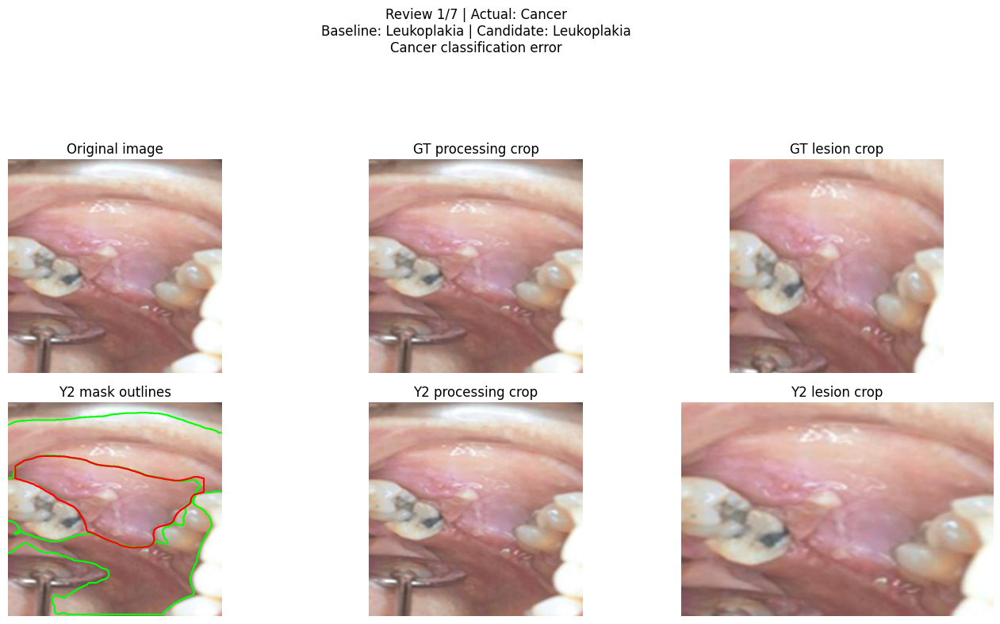

Sample: cancer_detection_v2i_yolov11__5c6f4ea9f8c44e4055b0
Green outline = processing area; red = lesion
Y2 lesion present: True
----------------------------------------------------------------------


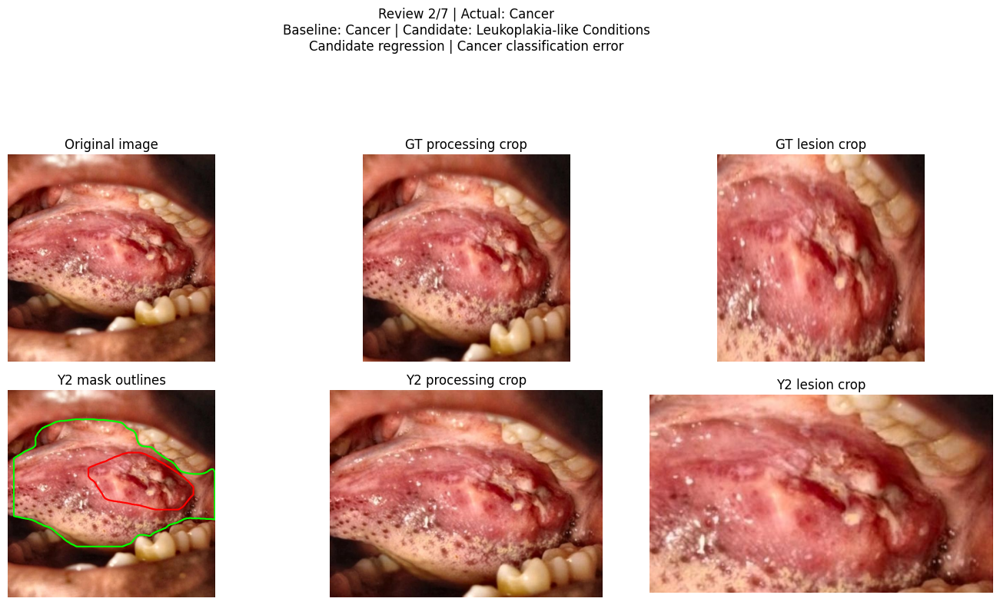

Sample: cancer_detection_v2i_yolov11__6f981baae9a5c522bbeb
Green outline = processing area; red = lesion
Y2 lesion present: True
----------------------------------------------------------------------


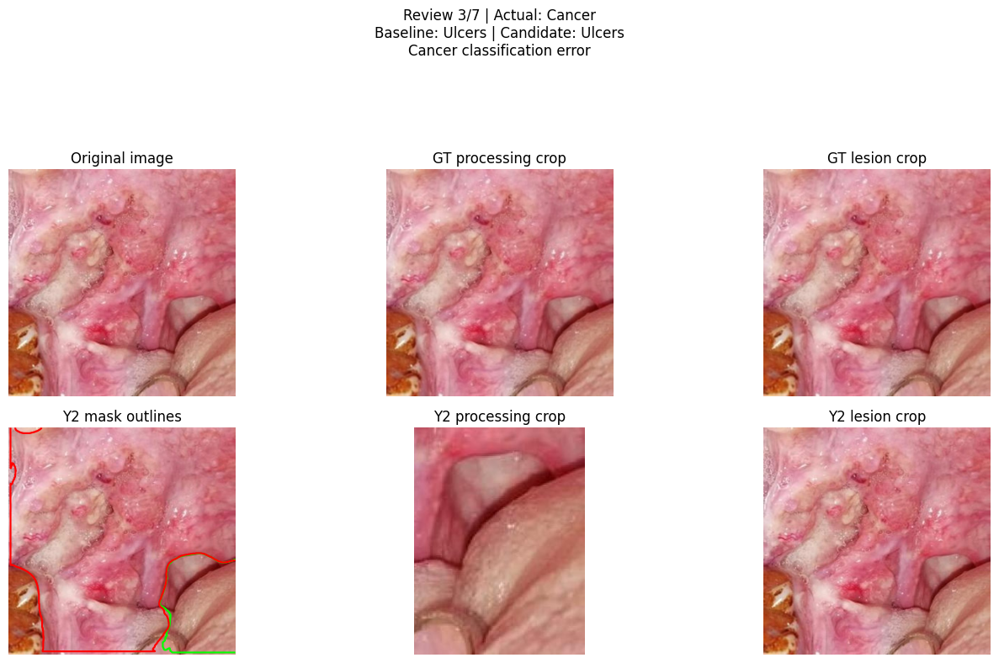

Sample: cancer_detection_v2i_yolov11__df495f25d387d840a656
Green outline = processing area; red = lesion
Y2 lesion present: True
----------------------------------------------------------------------


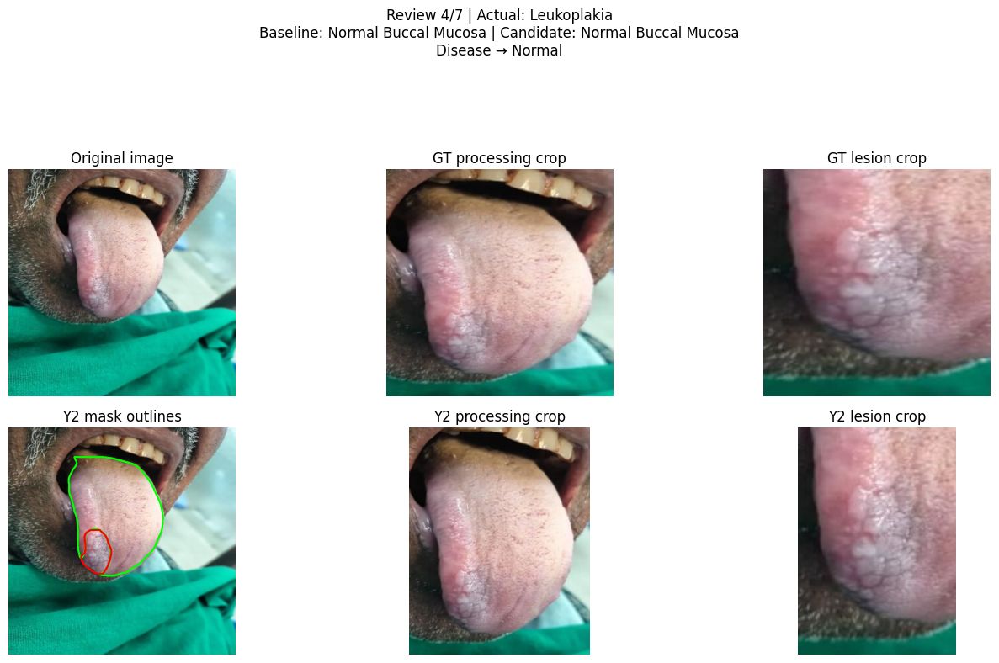

Sample: leukoplakia_detection_v2i_yolov11__3256f509b9f0526cd01e
Green outline = processing area; red = lesion
Y2 lesion present: True
----------------------------------------------------------------------


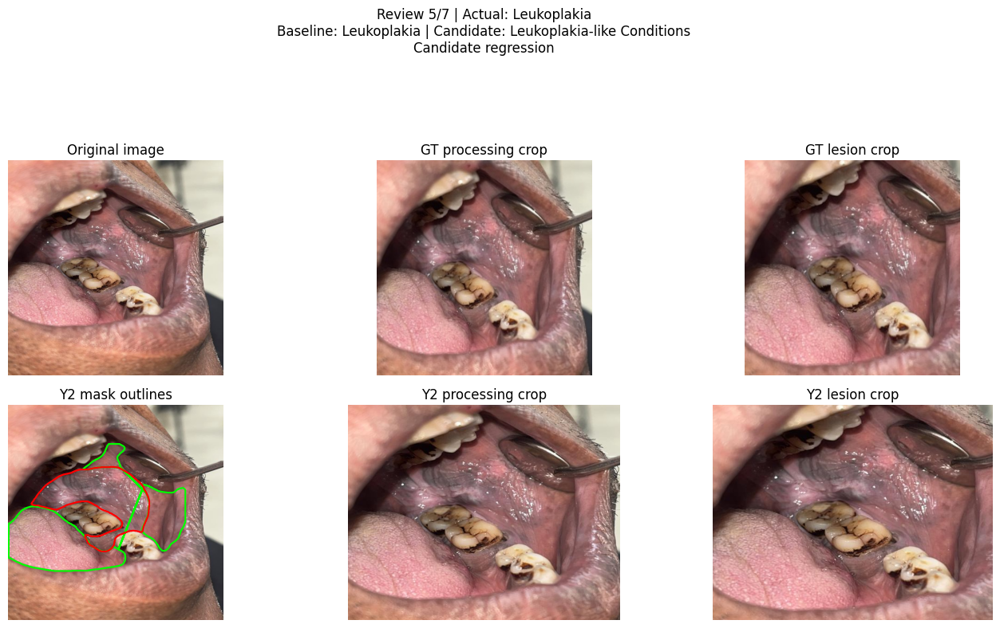

Sample: leukoplakia_detection_v2i_yolov11__540084f675cc5a9f0871
Green outline = processing area; red = lesion
Y2 lesion present: True
----------------------------------------------------------------------


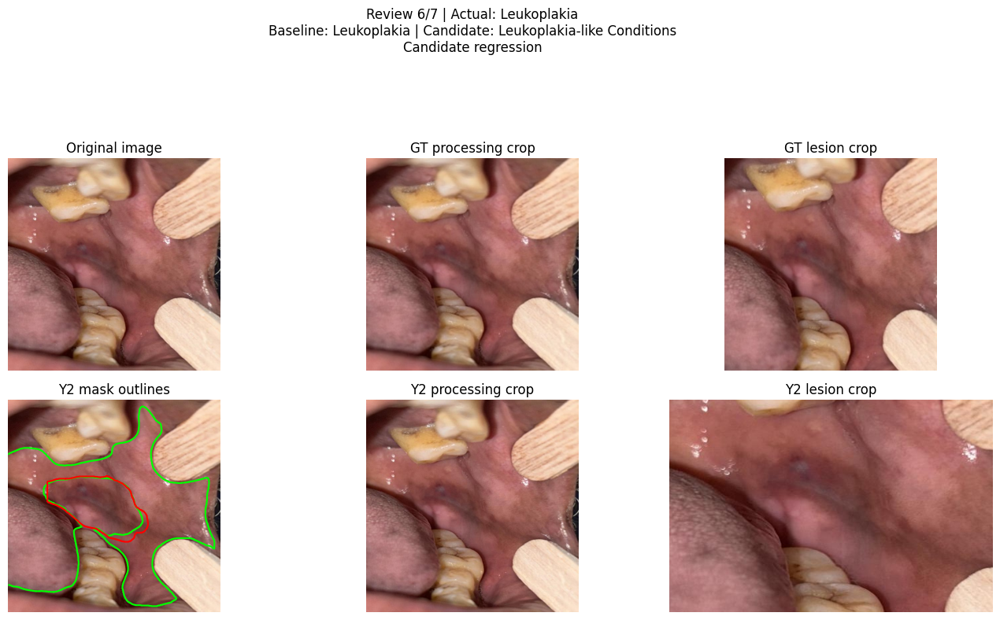

Sample: leukoplakia_detection_v2i_yolov11__f2bde0c9d0f25e5d7e26
Green outline = processing area; red = lesion
Y2 lesion present: True
----------------------------------------------------------------------


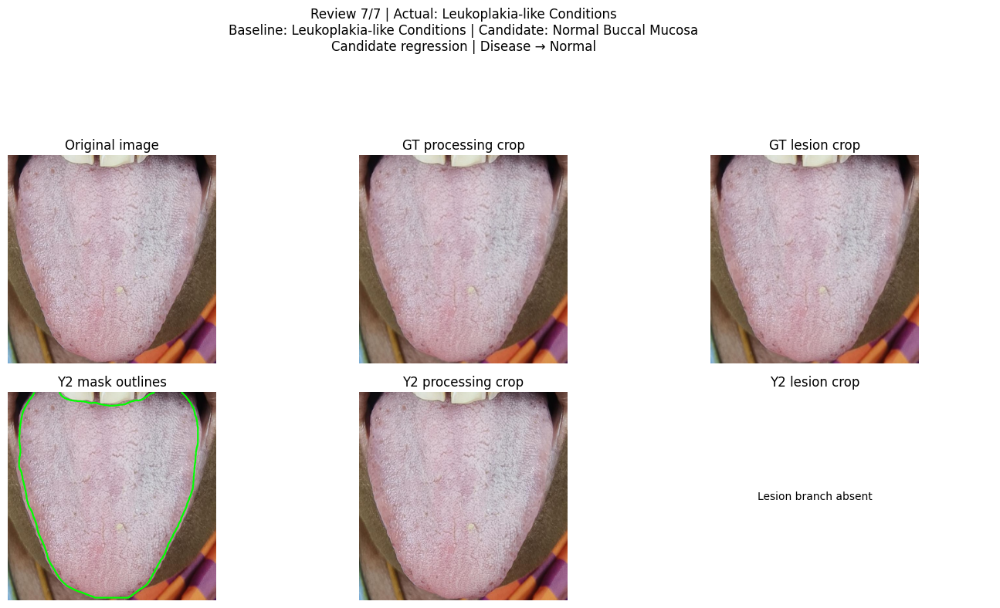

Sample: leukoplakia_like_detection_v3i_yolov11__4e1ce0848a2e0cc20d08
Green outline = processing area; red = lesion
Y2 lesion present: False
----------------------------------------------------------------------

Cell 17 complete. Weights and class labels unchanged.


In [ ]:
# CELL 17 — VISUAL REVIEW OF VALIDATION ERRORS
# Inline display only; no new image files or model changes.

import io
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

pairs = pd.read_csv(PAIR_DIR / "per_image.csv")

baseline_ok = pairs["baseline_id"] == pairs["true_id"]
candidate_ok = pairs["candidate_id"] == pairs["true_id"]

regression = baseline_ok & ~candidate_ok
disease_normal = (pairs["true_id"] != 3) & (pairs["candidate_id"] == 3)
cancer_error = (pairs["true_id"] == 0) & ~candidate_ok

review = pairs.loc[
    regression | disease_normal | cancer_error
].copy()

review["review_reason"] = review.apply(
    lambda row: " | ".join(
        reason for condition, reason in [
            (
                row["baseline_id"] == row["true_id"]
                and row["candidate_id"] != row["true_id"],
                "Candidate regression",
            ),
            (
                row["true_id"] != 3 and row["candidate_id"] == 3,
                "Disease → Normal",
            ),
            (
                row["true_id"] == 0 and row["candidate_id"] != 0,
                "Cancer classification error",
            ),
        ]
        if condition
    ),
    axis=1,
)

manifest = pd.read_csv(DATASET_DIR / "manifest.csv")
manifest = manifest.loc[manifest["split"] == "valid"].copy()

review = review.merge(
    manifest[
        [
            "sample_id", "source_zip", "source_image_member",
            "processing_roi_path", "lesion_roi_path", "lesion_present",
        ]
    ],
    on="sample_id",
    how="left",
    validate="one_to_one",
    suffixes=("", "_manifest"),
)

print("Candidate regressions:", int(regression.sum()))
print("Disease → Normal errors:", int(disease_normal.sum()))
print("Remaining Cancer errors:", int(cancer_error.sum()))
print("Unique images to review:", len(review))

display(review[
    [
        "sample_id", "true_class", "baseline_class",
        "candidate_class", "review_reason",
    ]
])

archives = {}

try:
    for number, (_, row) in enumerate(review.iterrows(), start=1):
        zip_path = str(row["source_zip"])
        if zip_path not in archives:
            archives[zip_path] = zipfile.ZipFile(zip_path)

        raw = archives[zip_path].read(str(row["source_image_member"]))
        result = predict_c2_with_y(io.BytesIO(raw))

        rgb = result["original_rgb"]
        original = Image.fromarray(rgb)

        with Image.open(resolve_crop(row["processing_roi_path"])) as image:
            gt_processing = image.convert("RGB").copy()

        gt_present = parse_presence(row["lesion_present"])
        if gt_present:
            with Image.open(resolve_crop(row["lesion_roi_path"])) as image:
                gt_lesion = image.convert("RGB").copy()
        else:
            gt_lesion = None

        processing_bbox = result["processing_bbox"]
        if processing_bbox is None:
            processing_bbox = (0, 0, original.width, original.height)

        y2_processing = original.crop(tuple(map(int, processing_bbox)))
        y2_lesion = (
            original.crop(tuple(map(int, result["lesion_bbox"])))
            if result["lesion_present"] and result["lesion_bbox"] is not None
            else None
        )

        fig, axes = plt.subplots(2, 3, figsize=(14, 8))

        panels = [
            (original, "Original image"),
            (gt_processing, "GT processing crop"),
            (gt_lesion, "GT lesion crop"),
            (original, "Y2 mask outlines"),
            (y2_processing, "Y2 processing crop"),
            (y2_lesion, "Y2 lesion crop"),
        ]

        for axis, (image, title) in zip(axes.flat, panels):
            if image is not None:
                axis.imshow(image)
            else:
                axis.text(
                    0.5, 0.5, "Lesion branch absent",
                    ha="center", va="center",
                    transform=axis.transAxes,
                )
            axis.set_title(title)
            axis.axis("off")

        outline_axis = axes[1, 0]
        for key, color in [
            ("processing_mask", "lime"),
            ("lesion_mask", "red"),
        ]:
            mask = np.asarray(result[key]).astype(bool)
            if mask.any() and not mask.all():
                outline_axis.contour(
                    mask.astype(float),
                    levels=[0.5],
                    colors=[color],
                    linewidths=1.5,
                )

        fig.suptitle(
            f"Review {number}/{len(review)} | Actual: {row['true_class']}\n"
            f"Baseline: {row['baseline_class']} | "
            f"Candidate: {row['candidate_class']}\n"
            f"{row['review_reason']}",
            fontsize=12,
        )

        plt.tight_layout(rect=[0, 0, 1, 0.88])
        plt.show()
        plt.close(fig)

        print("Sample:", row["sample_id"])
        print("Green outline = processing area; red = lesion")
        print("Y2 lesion present:", result["lesion_present"])
        print("-" * 70)

finally:
    for archive in archives.values():
        archive.close()

print("\nCell 17 complete. Weights and class labels unchanged.")

In [ ]:
# CELL 18 — GEOMETRY-BASED ROI EXPANSION EXPERIMENT
# Validation only. No training or active inference changes.

import io
import zipfile
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, classification_report
from IPython.display import display

GEOMETRY_DIR = EXP_ROOT / "geometry_validation"
GEOMETRY_DIR.mkdir(parents=True, exist_ok=True)

COVERAGE_THRESHOLD = 0.90
UNION_PADDING = 0.12  # Same processing-area padding policy.

validation_rows = pd.read_csv(DATASET_DIR / "manifest.csv")
validation_rows = validation_rows.loc[
    validation_rows["split"] == "valid"
].sort_values("sample_id").reset_index(drop=True)

c2_inference_model.eval()
exp_model.eval()


def predict_from_tensors(model, processing, lesion, presence):
    with torch.inference_mode():
        output = model(
            processing.unsqueeze(0).to(model_device),
            lesion.unsqueeze(0).to(model_device),
            torch.tensor(
                [[float(presence)]], device=model_device
            ),
        )
    return int(output["log_probabilities"].argmax(1).item())


records = []
archives = {}

try:
    for index, row in validation_rows.iterrows():
        zip_path = str(row["source_zip"])
        if zip_path not in archives:
            archives[zip_path] = zipfile.ZipFile(zip_path)

        raw = archives[zip_path].read(str(row["source_image_member"]))
        result = predict_c2_with_y(io.BytesIO(raw))

        rgb = result["original_rgb"]
        height, width = rgb.shape[:2]
        processing_mask = np.asarray(
            result["processing_mask"]
        ).astype(bool)
        lesion_mask = np.asarray(result["lesion_mask"]).astype(bool)

        assert processing_mask.shape == (height, width)
        assert lesion_mask.shape == (height, width)

        original_bbox = result["processing_bbox"]
        if original_bbox is None:
            original_bbox = (0, 0, width, height)

        x1, y1, x2, y2 = map(int, original_bbox)
        assert 0 <= x1 < x2 <= width
        assert 0 <= y1 < y2 <= height

        lesion_pixels = int(lesion_mask.sum())
        if lesion_pixels:
            crop_coverage = float(
                lesion_mask[y1:y2, x1:x2].sum() / lesion_pixels
            )
            mask_overlap = float(
                (lesion_mask & processing_mask).sum() / lesion_pixels
            )
        else:
            crop_coverage = np.nan
            mask_overlap = np.nan

        expand = (
            lesion_pixels > 0
            and crop_coverage < COVERAGE_THRESHOLD
        )

        expanded_bbox = original_bbox
        if expand:
            union_bbox = c2_mask_bbox(
                processing_mask | lesion_mask,
                padding=UNION_PADDING,
            )
            if union_bbox is None:
                raise RuntimeError("Non-empty union but bbox missing.")

            # Include the whole original crop as well as the union.
            ux1, uy1, ux2, uy2 = map(int, union_bbox)
            expanded_bbox = (
                max(0, min(x1, ux1)),
                max(0, min(y1, uy1)),
                min(width, max(x2, ux2)),
                min(height, max(y2, uy2)),
            )

        original_processing = c2_roi_tensor(rgb, original_bbox)
        expanded_processing = (
            c2_roi_tensor(rgb, expanded_bbox)
            if expand else original_processing
        )

        present = bool(result["lesion_present"])
        if present:
            if result["lesion_bbox"] is None:
                raise RuntimeError("Lesion present but bbox missing.")
            lesion = c2_roi_tensor(rgb, result["lesion_bbox"])
        else:
            lesion = torch.zeros_like(original_processing)

        record = {
            "sample_id": row["sample_id"],
            "true_id": int(row["class_index"]),
            "true_class": row["class_name"],
            "lesion_present": present,
            "lesion_in_processing_mask": mask_overlap,
            "lesion_in_processing_crop": crop_coverage,
            "roi_expanded": expand,
            "original_bbox": str(tuple(original_bbox)),
            "expanded_bbox": str(tuple(expanded_bbox)),
        }

        for prefix, model in [
            ("baseline", c2_inference_model),
            ("candidate", exp_model),
        ]:
            original_prediction = predict_from_tensors(
                model, original_processing, lesion, present
            )
            expanded_prediction = (
                predict_from_tensors(
                    model, expanded_processing, lesion, present
                )
                if expand else original_prediction
            )

            record[f"{prefix}_original"] = original_prediction
            record[f"{prefix}_expanded"] = expanded_prediction

        records.append(record)

        if (index + 1) % 25 == 0 or index + 1 == len(validation_rows):
            print(f"Audited {index + 1}/{len(validation_rows)}")

finally:
    for archive in archives.values():
        archive.close()

geometry_results = pd.DataFrame(records)
class_names = best_ckpt["class_names"]
summary_rows = []

for condition in [
    "baseline_original", "baseline_expanded",
    "candidate_original", "candidate_expanded",
]:
    truth = geometry_results["true_id"]
    prediction = geometry_results[condition]

    report = classification_report(
        truth, prediction,
        labels=list(range(5)),
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )

    summary_rows.append({
        "condition": condition,
        "accuracy": accuracy_score(truth, prediction),
        "macro_f1": report["macro avg"]["f1-score"],
        "cancer_recall": report["Cancer"]["recall"],
        "leukoplakia_recall": report["Leukoplakia"]["recall"],
        "leukoplakia_like_recall":
            report["Leukoplakia-like Conditions"]["recall"],
        "normal_to_disease_count": int(
            ((truth == 3) & (prediction != 3)).sum()
        ),
        "disease_to_normal_count": int(
            ((truth != 3) & (prediction == 3)).sum()
        ),
    })

geometry_summary = pd.DataFrame(summary_rows)

print("\nORIGINAL vs GEOMETRY-EXPANDED ROIs")
display(geometry_summary)

print("\nIMAGES TRIGGERING EXPANSION")
triggered = geometry_results.loc[
    geometry_results["roi_expanded"]
].copy()

for column in [
    "baseline_original", "baseline_expanded",
    "candidate_original", "candidate_expanded",
]:
    triggered[column + "_class"] = triggered[column].map(
        dict(enumerate(class_names))
    )

display(triggered[
    [
        "sample_id", "true_class",
        "lesion_in_processing_mask", "lesion_in_processing_crop",
        "baseline_original_class", "baseline_expanded_class",
        "candidate_original_class", "candidate_expanded_class",
    ]
])

print("\nEXPANSION EFFECT ON TRIGGERED IMAGES")
for prefix in ["baseline", "candidate"]:
    before = triggered[f"{prefix}_original"] == triggered["true_id"]
    after = triggered[f"{prefix}_expanded"] == triggered["true_id"]
    print(
        prefix,
        "| Fixed:", int((~before & after).sum()),
        "| Newly wrong:", int((before & ~after).sum()),
        "| Prediction changed:", int((
            triggered[f"{prefix}_original"]
            != triggered[f"{prefix}_expanded"]
        ).sum()),
    )

geometry_results.to_csv(
    GEOMETRY_DIR / "18_per_image.csv", index=False
)
geometry_summary.to_csv(
    GEOMETRY_DIR / "18_summary.csv", index=False
)

print("\nExpanded images:", len(triggered))
print("Reports:", GEOMETRY_DIR)
print("Cell 18 complete. Active inference and weights unchanged.")

Audited 25/144
Audited 50/144
Audited 75/144
Audited 100/144
Audited 125/144
Audited 144/144

ORIGINAL vs GEOMETRY-EXPANDED ROIs


,condition,accuracy,macro_f1,cancer_recall,leukoplakia_recall,leukoplakia_like_recall,normal_to_disease_count,disease_to_normal_count
0,baseline_original,0.784722,0.801821,0.896552,0.657143,0.633333,5,1
1,baseline_expanded,0.805556,0.824428,0.931034,0.657143,0.700000,5,1
2,candidate_original,0.777778,0.790108,0.896552,0.571429,0.733333,6,2
3,candidate_expanded,0.791667,0.805427,0.931034,0.571429,0.766667,6,2



IMAGES TRIGGERING EXPANSION


,sample_id,true_class,lesion_in_processing_mask,lesion_in_processing_crop,baseline_original_class,baseline_expanded_class,candidate_original_class,candidate_expanded_class
27,cancer_detection_v2i_yolov11__df495f25d387d840...,Cancer,0.000037,0.062881,Ulcers,Cancer,Ulcers,Cancer
54,leukoplakia_detection_v2i_yolov11__d3a51dd4f2b...,Leukoplakia,0.005818,0.618697,Leukoplakia,Leukoplakia,Leukoplakia,Leukoplakia
68,leukoplakia_like_detection_v3i_yolov11__21e75f...,Leukoplakia-like Conditions,0.000698,0.417753,Cancer,Leukoplakia-like Conditions,Leukoplakia-like Conditions,Leukoplakia-like Conditions
70,leukoplakia_like_detection_v3i_yolov11__2a5864...,Leukoplakia-like Conditions,0.010570,0.894166,Leukoplakia-like Conditions,Leukoplakia-like Conditions,Leukoplakia-like Conditions,Leukoplakia-like Conditions
80,leukoplakia_like_detection_v3i_yolov11__7f6a64...,Leukoplakia-like Conditions,0.003638,0.876158,Leukoplakia,Leukoplakia-like Conditions,Leukoplakia-like Conditions,Leukoplakia-like Conditions
85,leukoplakia_like_detection_v3i_yolov11__adbfac...,Leukoplakia-like Conditions,0.004225,0.469343,Cancer,Cancer,Cancer,Leukoplakia-like Conditions
88,leukoplakia_like_detection_v3i_yolov11__afa82b...,Leukoplakia-like Conditions,0.000161,0.887353,Leukoplakia-like Conditions,Leukoplakia-like Conditions,Leukoplakia-like Conditions,Leukoplakia-like Conditions
93,leukoplakia_like_detection_v3i_yolov11__fa0cb2...,Leukoplakia-like Conditions,0.000637,0.884886,Leukoplakia-like Conditions,Leukoplakia-like Conditions,Leukoplakia-like Conditions,Leukoplakia-like Conditions



EXPANSION EFFECT ON TRIGGERED IMAGES
baseline | Fixed: 3 | Newly wrong: 0 | Prediction changed: 3
candidate | Fixed: 2 | Newly wrong: 0 | Prediction changed: 2

Expanded images: 8
Reports: /content/drive/MyDrive/training_dataset/extra_data/module_2_training/experiments/crop_jitter_01/geometry_validation
Cell 18 complete. Active inference and weights unchanged.


In [ ]:
# CELL 19 — GT CROP-JITTER EXPERIMENT SETUP
# Run Cell 15 again AFTER this setup to train this experiment.

import copy
import io
import random
import zipfile
import numpy as np
import torch
import torch.nn as nn
import timm
from pathlib import Path
from PIL import Image
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode
from torch.utils.data import DataLoader
import json

# Preserve previous candidate's path.
REGULARIZED_CANDIDATE_PATH = EXP_BEST_PATH

EXP_ROOT = Path(
    "/content/drive/MyDrive/training_dataset/extra_data/"
    "module_2_training/experiments/crop_jitter_01"
)
EXP_ROOT.mkdir(parents=True, exist_ok=True)

if (EXP_ROOT / "ai_c2_candidate_best.pt").exists():
    raise FileExistsError(
        "crop_jitter_01 already trained. Naya run chahiye to "
        "folder name crop_jitter_02 karo."
    )

EXP_CONFIG = {
    "seed": 42,
    "max_epochs": 60,
    "warmup_epochs": 5,
    "patience": 10,
    "head_lr": 1e-4,
    "backbone_lr": 5e-6,
    "weight_decay": 5e-4,
    "label_smoothing": 0.05,
    "lesion_dropout": 0.15,
    "batch_size": 16,
    "crop_jitter_probability": 0.70,
    "crop_extra_context_max": 0.12,
    "crop_jitter_source": "original image + GT manifest bboxes",
}

random.seed(EXP_CONFIG["seed"])
np.random.seed(EXP_CONFIG["seed"])
torch.manual_seed(EXP_CONFIG["seed"])
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(EXP_CONFIG["seed"])


class GTJitterDataset(C2ExperimentDataset):
    def __init__(self, rows):
        super().__init__(rows, training=True)
        self.archives = {}

    def original_image(self, row):
        zip_path = str(row["source_zip"])
        if zip_path not in self.archives:
            self.archives[zip_path] = zipfile.ZipFile(zip_path)

        raw = self.archives[zip_path].read(
            str(row["source_image_member"])
        )
        with Image.open(io.BytesIO(raw)) as image:
            return image.convert("RGB").copy()

    def jitter_crop(self, original, bbox):
        if isinstance(bbox, str):
            bbox = json.loads(bbox)

        x1, y1, x2, y2 = map(int, bbox)
        assert 0 <= x1 < x2 <= original.width
        assert 0 <= y1 < y2 <= original.height

        if random.random() < EXP_CONFIG["crop_jitter_probability"]:
            width = x2 - x1
            height = y2 - y1
            maximum = EXP_CONFIG["crop_extra_context_max"]

            # Outward-only perturbation retains the complete GT crop.
            left = round(width * random.uniform(0, maximum))
            right = round(width * random.uniform(0, maximum))
            top = round(height * random.uniform(0, maximum))
            bottom = round(height * random.uniform(0, maximum))

            x1 = max(0, x1 - left)
            y1 = max(0, y1 - top)
            x2 = min(original.width, x2 + right)
            y2 = min(original.height, y2 + bottom)

        crop = original.crop((x1, y1, x2, y2)).resize(
            (C2_SIZE, C2_SIZE), Image.Resampling.BILINEAR
        )

        # Match prepared RGB crop encoding.
        buffer = io.BytesIO()
        crop.save(buffer, format="JPEG", quality=95)
        buffer.seek(0)
        with Image.open(buffer) as image:
            return image.convert("RGB").copy()

    def __getitem__(self, index):
        row = self.rows.iloc[index]
        original = self.original_image(row)

        processing = self.jitter_crop(
            original, row["processing_bbox"]
        )
        present = parse_presence(row["lesion_present"])

        lesion = (
            self.jitter_crop(original, row["lesion_bbox"])
            if present else None
        )

        # Same paired augmentations as regularized_01.
        flip = random.random() < 0.5
        angle = random.uniform(-8, 8)
        brightness = random.uniform(0.9, 1.1)
        contrast = random.uniform(0.9, 1.1)
        saturation = random.uniform(0.95, 1.05)

        def augment(image):
            if flip:
                image = TF.hflip(image)
            image = TF.rotate(
                image, angle,
                interpolation=InterpolationMode.BILINEAR,
                fill=0,
            )
            image = TF.adjust_brightness(image, brightness)
            image = TF.adjust_contrast(image, contrast)
            return TF.adjust_saturation(image, saturation)

        processing = augment(processing)
        if present:
            lesion = augment(lesion)

        if present and random.random() < EXP_CONFIG["lesion_dropout"]:
            present = False

        processing = TF.normalize(
            TF.to_tensor(processing), C2_MEAN, C2_STD
        )
        lesion = (
            TF.normalize(TF.to_tensor(lesion), C2_MEAN, C2_STD)
            if present else torch.zeros_like(processing)
        )

        return (
            processing,
            lesion,
            torch.tensor([float(present)], dtype=torch.float32),
            torch.tensor(int(row["class_index"]), dtype=torch.long),
        )

    def close(self):
        for archive in self.archives.values():
            archive.close()
        self.archives.clear()


# Close an earlier jitter dataset if this setup is rerun.
if "exp_train_loader" in globals():
    previous_dataset = exp_train_loader.dataset
    if isinstance(previous_dataset, GTJitterDataset):
        previous_dataset.close()

exp_train_loader = DataLoader(
    GTJitterDataset(exp_train_rows),
    batch_size=EXP_CONFIG["batch_size"],
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

# Fixed prepared GT validation crops: identical to previous experiment.
exp_valid_loader = DataLoader(
    C2ExperimentDataset(exp_valid_rows, training=False),
    batch_size=EXP_CONFIG["batch_size"],
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

exp_model = copy.deepcopy(c2_inference_model).cpu()
exp_model.backbone = timm.create_model(
    best_ckpt["backbone_name"],
    pretrained=True,
    num_classes=0,
    global_pool="avg",
)

for module_name, module in exp_model.named_children():
    if module_name != "backbone":
        for layer in module.modules():
            if hasattr(layer, "reset_parameters"):
                layer.reset_parameters()

with torch.no_grad():
    nn.init.normal_(
        exp_model.missing_lesion_embedding, mean=0.0, std=0.02
    )

for parameter in exp_model.parameters():
    parameter.requires_grad = True

exp_model = exp_model.to(model_device).eval()

processing, lesion, presence, target = next(iter(exp_train_loader))
with torch.inference_mode():
    output = exp_model(
        processing.to(model_device),
        lesion.to(model_device),
        presence.to(model_device),
    )
    loss = exp_loss(output, target.to(model_device))

assert output["log_probabilities"].shape == (len(target), 5)
assert torch.isfinite(loss).item()

# Reset RNG after the smoke check.
random.seed(EXP_CONFIG["seed"])
np.random.seed(EXP_CONFIG["seed"])
torch.manual_seed(EXP_CONFIG["seed"])
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(EXP_CONFIG["seed"])

print("=" * 80)
print("GT CROP-JITTER EXPERIMENT READY")
print("=" * 80)
print("Training images:", len(exp_train_rows))
print("Validation images:", len(exp_valid_rows))
print("GT-based crops; no Y2 inference during training.")
print("Outward context jitter: 0–12%, probability 70%")
print("Classes:", best_ckpt["class_names"])
print("Experiment folder:", EXP_ROOT)
print("Previous candidate:", REGULARIZED_CANDIDATE_PATH)
print("Forward loss finite:", torch.isfinite(loss).item())
print("Cell 19 complete. Training has not started.")

GT CROP-JITTER EXPERIMENT READY
Training images: 425
Validation images: 144
GT-based crops; no Y2 inference during training.
Outward context jitter: 0–12%, probability 70%
Classes: ['Cancer', 'Leukoplakia', 'Leukoplakia-like Conditions', 'Normal Buccal Mucosa', 'Ulcers']
Experiment folder: /content/drive/MyDrive/training_dataset/extra_data/module_2_training/experiments/crop_jitter_01
Previous candidate: /content/drive/MyDrive/training_dataset/extra_data/module_2_training/experiments/regularized_01/ai_c2_candidate_best.pt
Forward loss finite: True
Cell 19 complete. Training has not started.


In [ ]:
# RESUME CHECK — DRIVE FILES + RUNTIME STATE

from google.colab import drive
from pathlib import Path
import pandas as pd



ROOT = Path("/content/drive/MyDrive/training_dataset/extra_data")

required_files = {
    "Dataset manifest":
        ROOT / "module_1_dataset/prepared_dataset/manifest.csv",
    "Baseline C2":
        ROOT / "module_2_training/models/ai_c2_best.pt",
    "Calibrated baseline":
        ROOT / "module_2_training/models/ai_c2_best_calibrated.pt",
    "Leading regularized candidate":
        ROOT / "module_2_training/experiments/regularized_01/"
        "ai_c2_candidate_best.pt",
    "Crop-jitter candidate":
        ROOT / "module_2_training/experiments/crop_jitter_01/"
        "ai_c2_candidate_best.pt",
    "Y2 detector":
        ROOT / "ai_y2.pt",
}

status = pd.DataFrame([
    {
        "item": name,
        "exists": path.is_file(),
        "size_MB": (
            round(path.stat().st_size / (1024 ** 2), 2)
            if path.is_file() else None
        ),
        "path": str(path),
    }
    for name, path in required_files.items()
])
display(status)

print("\nRUNTIME DEFINITIONS")
for name in [
    "OralScanC2",
    "C2ExperimentDataset",
    "c2_inference_model",
    "predict_c2_with_y",
    "evaluate_exp",
]:
    print(f"{name}: {'available' if name in globals() else 'missing'}")

manifest_path = required_files["Dataset manifest"]
if manifest_path.is_file():
    resume_manifest = pd.read_csv(manifest_path)
    print("\nSAVED DATASET COUNTS")
    display(pd.crosstab(
        resume_manifest["class_name"],
        resume_manifest["split"],
    ).reindex(columns=["train", "valid", "test"], fill_value=0))

print("\nResume check complete. No training started.")

,item,exists,size_MB,path
0,Dataset manifest,True,0.99,/content/drive/MyDrive/training_dataset/extra_...
1,Baseline C2,True,53.82,/content/drive/MyDrive/training_dataset/extra_...
2,Calibrated baseline,True,53.83,/content/drive/MyDrive/training_dataset/extra_...
3,Leading regularized candidate,True,53.83,/content/drive/MyDrive/training_dataset/extra_...
4,Crop-jitter candidate,True,53.83,/content/drive/MyDrive/training_dataset/extra_...
5,Y2 detector,True,51.98,/content/drive/MyDrive/training_dataset/extra_...



RUNTIME DEFINITIONS
OralScanC2: missing
C2ExperimentDataset: missing
c2_inference_model: missing
predict_c2_with_y: missing
evaluate_exp: missing

SAVED DATASET COUNTS


split,train,valid,test
class_name,,,
Cancer,85,29,30
Leukoplakia,85,35,36
Leukoplakia-like Conditions,85,30,32
Normal Buccal Mucosa,85,32,32
Ulcers,85,18,18



Resume check complete. No training started.


In [ ]:
# RESUME — LOAD SAVED BASELINE + RESTORE EXPERIMENT HELPERS

import copy
import torch
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/training_dataset/extra_data")
DATASET_DIR = ROOT / "module_1_dataset/prepared_dataset"
MODEL_DIR = ROOT / "module_2_training/models"

best_ckpt = torch.load(
    MODEL_DIR / "ai_c2_best.pt",
    map_location="cpu",
    weights_only=False,
)

# Reuse the exact architecture restored by Module 2 Cell 2.
available_models = [
    value for key, value in list(globals().items())
    if isinstance(value, OralScanC2)
]
if not available_models:
    raise RuntimeError("Module 2 Cell 2 pehle run karo.")

model_device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

c2_inference_model = copy.deepcopy(available_models[0]).cpu()
c2_inference_model.load_state_dict(
    best_ckpt["model_state_dict"], strict=True
)
c2_inference_model = c2_inference_model.to(model_device).eval()

C2_SIZE = int(best_ckpt["preprocessing"]["image_size"])
C2_MEAN = tuple(best_ckpt["preprocessing"]["mean"])
C2_STD = tuple(best_ckpt["preprocessing"]["std"])


def resolve_crop(value):
    path = Path(str(value))
    if not path.is_absolute():
        path = DATASET_DIR / path
    if not path.is_file():
        raise FileNotFoundError(f"Crop missing: {path}")
    return path


def parse_presence(value):
    text = str(value).strip().lower()
    if text not in {"true", "false", "1", "0", "1.0", "0.0"}:
        raise ValueError(f"Invalid lesion_present: {value}")
    return text in {"true", "1", "1.0"}


print("Saved baseline loaded — strict weight loading PASSED")
print("Epoch:", best_ckpt["epoch"])
print("Classes:", best_ckpt["class_names"])
print("Device:", model_device)
print("No training started; no checkpoint overwritten.")

Saved baseline loaded — strict weight loading PASSED
Epoch: 22
Classes: ['Cancer', 'Leukoplakia', 'Leukoplakia-like Conditions', 'Normal Buccal Mucosa', 'Ulcers']
Device: cuda
No training started; no checkpoint overwritten.


In [ ]:
# LAST STABILITY RUN — SEED 73 SETUP
# After this cell, run existing Cell 15.

import copy
import random
import numpy as np
import torch
import torch.nn as nn
import timm
from torch.utils.data import DataLoader

required = [
    "C2ExperimentDataset", "c2_inference_model", "best_ckpt",
    "exp_train_rows", "exp_valid_rows", "exp_loss", "freeze_exp_bn",
]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f"Cell 14 helpers missing: {missing}")

EXP_ROOT = ROOT / "module_2_training/experiments/regularized_seed73"

if (EXP_ROOT / "ai_c2_candidate_best.pt").exists():
    raise FileExistsError(
        "Seed 73 checkpoint already exists; training repeat mat karo."
    )

EXP_ROOT.mkdir(parents=True, exist_ok=True)

EXP_CONFIG = {
    "seed": 73,
    "max_epochs": 60,
    "warmup_epochs": 5,
    "patience": 10,
    "head_lr": 1e-4,
    "backbone_lr": 5e-6,
    "weight_decay": 5e-4,
    "label_smoothing": 0.05,
    "lesion_dropout": 0.15,
    "batch_size": 16,
}

random.seed(73)
np.random.seed(73)
torch.manual_seed(73)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(73)

exp_train_loader = DataLoader(
    C2ExperimentDataset(exp_train_rows, training=True),
    batch_size=16,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)
exp_valid_loader = DataLoader(
    C2ExperimentDataset(exp_valid_rows, training=False),
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
)

exp_model = copy.deepcopy(c2_inference_model).cpu()
exp_model.backbone = timm.create_model(
    best_ckpt["backbone_name"],
    pretrained=True,
    num_classes=0,
    global_pool="avg",
)

for module_name, module in exp_model.named_children():
    if module_name != "backbone":
        for layer in module.modules():
            if hasattr(layer, "reset_parameters"):
                layer.reset_parameters()

with torch.no_grad():
    nn.init.normal_(
        exp_model.missing_lesion_embedding,
        mean=0.0,
        std=0.02,
    )

for parameter in exp_model.parameters():
    parameter.requires_grad = True

exp_model = exp_model.to(model_device).eval()

processing, lesion, presence, target = next(iter(exp_valid_loader))
with torch.inference_mode():
    output = exp_model(
        processing.to(model_device),
        lesion.to(model_device),
        presence.to(model_device),
    )
    loss = exp_loss(output, target.to(model_device))

assert output["log_probabilities"].shape == (len(target), 5)
assert torch.isfinite(loss).item()

print("Seed 73 setup complete.")
print("Fresh pretrained backbone; same regularized settings.")
print("Train / validation:", len(exp_train_rows), len(exp_valid_rows))
print("Save folder:", EXP_ROOT)
print("Previous checkpoints preserved.")
print("Ab existing Cell 15 run karo.")

Seed 73 setup complete.
Fresh pretrained backbone; same regularized settings.
Train / validation: 425 144
Save folder: /content/drive/MyDrive/training_dataset/extra_data/module_2_training/experiments/regularized_seed73
Previous checkpoints preserved.
Ab existing Cell 15 run karo.


In [ ]:
# CELL 20 — FINAL SEED COMPARISON: FIXED EXPANDED-Y2 ROIs
# No training, no calibration, no test evaluation.

import copy
import io
import zipfile
import numpy as np
import pandas as pd
import torch
from pathlib import Path
from sklearn.metrics import classification_report, accuracy_score
from IPython.display import display

required = [
    "predict_c2_with_y", "c2_roi_tensor",
    "c2_mask_bbox", "c2_inference_model",
]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(f"Pehle Module 2 Cell 6 run karo: {missing}")

ROOT = Path("/content/drive/MyDrive/training_dataset/extra_data")
COMPARE_DIR = ROOT / "module_2_training/reports/final_seed_comparison"
COMPARE_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_paths = {
    "baseline": ROOT / "module_2_training/models/ai_c2_best.pt",
    "seed42": ROOT / (
        "module_2_training/experiments/regularized_01/"
        "ai_c2_candidate_best.pt"
    ),
    "seed17": ROOT / (
        "module_2_training/experiments/regularized_seed17/"
        "ai_c2_candidate_best.pt"
    ),
    "seed73": ROOT / (
        "module_2_training/experiments/regularized_seed73/"
        "ai_c2_candidate_best.pt"
    ),
}

classes = [
    "Cancer", "Leukoplakia", "Leukoplakia-like Conditions",
    "Normal Buccal Mucosa", "Ulcers",
]
comparison_device = next(c2_inference_model.parameters()).device
comparison_models = {}

for name, path in checkpoint_paths.items():
    checkpoint = torch.load(
        path, map_location="cpu", weights_only=False
    )
    assert checkpoint["class_names"] == classes
    assert checkpoint["preprocessing"] == best_ckpt["preprocessing"]

    loaded = copy.deepcopy(c2_inference_model).cpu()
    loaded.load_state_dict(checkpoint["model_state_dict"], strict=True)
    comparison_models[name] = loaded.to(comparison_device).eval()
    del checkpoint
    print("Loaded:", name)

rows = pd.read_csv(
    ROOT / "module_1_dataset/prepared_dataset/manifest.csv"
)
rows = rows.loc[rows["split"] == "valid"].sort_values(
    "sample_id"
).reset_index(drop=True)
assert len(rows) == 144

records = []
archives = {}

try:
    for index, row in rows.iterrows():
        zip_path = str(row["source_zip"])
        if zip_path not in archives:
            archives[zip_path] = zipfile.ZipFile(zip_path)

        raw = archives[zip_path].read(str(row["source_image_member"]))
        result = predict_c2_with_y(io.BytesIO(raw))

        rgb = result["original_rgb"]
        height, width = rgb.shape[:2]
        bbox = result["processing_bbox"]
        if bbox is None:
            bbox = (0, 0, width, height)

        x1, y1, x2, y2 = map(int, bbox)
        lesion_mask = np.asarray(result["lesion_mask"]).astype(bool)
        processing_mask = np.asarray(
            result["processing_mask"]
        ).astype(bool)

        lesion_pixels = int(lesion_mask.sum())
        coverage = (
            float(lesion_mask[y1:y2, x1:x2].sum() / lesion_pixels)
            if lesion_pixels else np.nan
        )
        expanded = lesion_pixels > 0 and coverage < 0.90

        if expanded:
            union_bbox = c2_mask_bbox(
                processing_mask | lesion_mask, padding=0.12
            )
            if union_bbox is None:
                raise RuntimeError("Union bbox missing.")

            ux1, uy1, ux2, uy2 = map(int, union_bbox)
            bbox = (
                max(0, min(x1, ux1)),
                max(0, min(y1, uy1)),
                min(width, max(x2, ux2)),
                min(height, max(y2, uy2)),
            )

        processing = c2_roi_tensor(rgb, bbox)
        present = bool(result["lesion_present"])

        if present:
            if result["lesion_bbox"] is None:
                raise RuntimeError("Lesion bbox missing.")
            lesion = c2_roi_tensor(rgb, result["lesion_bbox"])
        else:
            lesion = torch.zeros_like(processing)

        inputs = (
            processing.unsqueeze(0).to(comparison_device),
            lesion.unsqueeze(0).to(comparison_device),
            torch.tensor(
                [[float(present)]], device=comparison_device
            ),
        )

        record = {
            "sample_id": row["sample_id"],
            "true_id": int(row["class_index"]),
            "true_class": row["class_name"],
            "roi_expanded": expanded,
            "lesion_present": present,
        }

        with torch.inference_mode():
            for name, loaded in comparison_models.items():
                output = loaded(*inputs)
                record[name] = int(
                    output["log_probabilities"].argmax(1).item()
                )

        records.append(record)

        if (index + 1) % 25 == 0 or index + 1 == len(rows):
            print(f"Compared {index + 1}/{len(rows)}")

finally:
    for archive in archives.values():
        archive.close()

seed_predictions = pd.DataFrame(records)
summary = []
per_class = []

for name in checkpoint_paths:
    truth = seed_predictions["true_id"]
    prediction = seed_predictions[name]

    report = classification_report(
        truth, prediction,
        labels=list(range(5)),
        target_names=classes,
        output_dict=True,
        zero_division=0,
    )

    summary.append({
        "model": name,
        "correct": int((truth == prediction).sum()),
        "accuracy": accuracy_score(truth, prediction),
        "macro_f1": report["macro avg"]["f1-score"],
        "cancer_correct": int(((truth == 0) & (prediction == 0)).sum()),
        "normal_to_disease": int(((truth == 3) & (prediction != 3)).sum()),
        "disease_to_normal": int(((truth != 3) & (prediction == 3)).sum()),
    })

    for class_name in classes:
        per_class.append({
            "model": name,
            "class_name": class_name,
            **report[class_name],
        })

seed_summary = pd.DataFrame(summary)
seed_class_metrics = pd.DataFrame(per_class)

print("\nFIXED EXPANDED-Y2 VALIDATION COMPARISON")
display(seed_summary)

print("\nPER-CLASS RECALL")
display(seed_class_metrics.pivot(
    index="class_name", columns="model", values="recall"
).reindex(classes))

print("\nREGULARIZED RUN VARIABILITY")
display(
    seed_summary.loc[seed_summary["model"] != "baseline",
                     ["accuracy", "macro_f1"]]
    .agg(["mean", "std", "min", "max"])
)

seed_predictions.to_csv(COMPARE_DIR / "per_image.csv", index=False)
seed_summary.to_csv(COMPARE_DIR / "summary.csv", index=False)
seed_class_metrics.to_csv(COMPARE_DIR / "class_metrics.csv", index=False)

print("\nExpanded images:", int(seed_predictions["roi_expanded"].sum()))
print("Reports:", COMPARE_DIR)
print("Cell 20 complete. No active model replaced.")

Loaded: baseline
Loaded: seed42
Loaded: seed17
Loaded: seed73
Compared 25/144
Compared 50/144
Compared 75/144
Compared 100/144
Compared 125/144
Compared 144/144

FIXED EXPANDED-Y2 VALIDATION COMPARISON


,model,correct,accuracy,macro_f1,cancer_correct,normal_to_disease,disease_to_normal
0,baseline,116,0.805556,0.824428,27,5,1
1,seed42,119,0.826389,0.840560,27,3,2
2,seed17,114,0.791667,0.813710,24,4,1
3,seed73,116,0.805556,0.820214,29,7,2



PER-CLASS RECALL


model,baseline,seed17,seed42,seed73
class_name,,,,
Cancer,0.931034,0.827586,0.931034,1.000000
Leukoplakia,0.657143,0.657143,0.600000,0.600000
Leukoplakia-like Conditions,0.700000,0.700000,0.800000,0.766667
Normal Buccal Mucosa,0.843750,0.875000,0.906250,0.781250
Ulcers,1.000000,1.000000,1.000000,1.000000



REGULARIZED RUN VARIABILITY


,accuracy,macro_f1
mean,0.807870,0.824828
std,0.017476,0.014007
min,0.791667,0.813710
max,0.826389,0.840560



Expanded images: 8
Reports: /content/drive/MyDrive/training_dataset/extra_data/module_2_training/reports/final_seed_comparison
Cell 20 complete. No active model replaced.


In [ ]:
# CELL 21 — FREEZE SELECTED C2 CANDIDATE + INFERENCE POLICY
# No training. Original checkpoints remain untouched.

import copy
import hashlib
import json
import torch
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/training_dataset/extra_data")
FINAL_DIR = ROOT / "module_2_training/final_package"
FINAL_DIR.mkdir(parents=True, exist_ok=True)

SELECTED_SOURCE = ROOT / (
    "module_2_training/experiments/regularized_01/"
    "ai_c2_candidate_best.pt"
)
FROZEN_PATH = FINAL_DIR / "ai_c2_frozen_uncalibrated.pt"
POLICY_PATH = FINAL_DIR / "inference_policy.json"

if FROZEN_PATH.exists() or POLICY_PATH.exists():
    raise FileExistsError(
        "Frozen package already exists. Existing files ko overwrite "
        "karne ke bajaye output bhejo."
    )

selected = torch.load(
    SELECTED_SOURCE, map_location="cpu", weights_only=False
)

expected_classes = [
    "Cancer", "Leukoplakia", "Leukoplakia-like Conditions",
    "Normal Buccal Mucosa", "Ulcers",
]
assert selected["class_names"] == expected_classes
assert selected["class_to_index"] == {
    name: index for index, name in enumerate(expected_classes)
}
assert selected["num_classes"] == 5

policy = {
    "processing_padding": 0.12,
    "lesion_padding": 0.30,
    "processing_missing": "full_image_fallback",
    "lesion_missing": "learned_missing_embedding",
    "geometry_expansion": {
        "enabled": True,
        "coverage_definition":
            "predicted lesion pixels inside processing crop / "
            "all predicted lesion pixels",
        "coverage_threshold": 0.90,
        "action":
            "expand processing crop to include original crop and "
            "padded union of processing and lesion masks",
        "union_padding": 0.12,
        "no_lesion_action": "keep_original_processing_crop",
    },
    "rgb_resize": "PIL_BILINEAR",
    "roi_jpeg_quality": 95,
    "image_size": selected["preprocessing"]["image_size"],
    "mean": selected["preprocessing"]["mean"],
    "std": selected["preprocessing"]["std"],
    "detector_class_resolution": "by_exact_class_name",
    "evaluated_detector": str(ROOT / "ai_y2.pt"),
    "evaluated_detector_classes": {
        "0": "processing_area", "1": "lesion"
    },
    "evaluated_detector_imgsz": 640,
    "evaluated_detector_confidence": 0.25,
    "evaluated_detector_retina_masks": True,
    "cross_detector_performance_verified": False,
}

frozen = copy.deepcopy(selected)
frozen["model_id"] = "ai_c2"
frozen["calibrated"] = False
for key in ["temperature", "calibration", "source_best_checkpoint"]:
    frozen.pop(key, None)

frozen["inference_policy"] = policy
frozen["selection"] = {
    "source_checkpoint": str(SELECTED_SOURCE),
    "seed": 42,
    "method": "validation-selected single checkpoint",
    "expanded_y2_validation_accuracy": 119 / 144,
    "expanded_y2_validation_macro_f1": 0.840560,
    "regularized_seed_mean_macro_f1": 0.824828,
    "independent_final_evaluation": "pending",
    "original_test_set_status": "previously inspected during development",
}

torch.save(frozen, FROZEN_PATH)

with open(POLICY_PATH, "w") as file:
    json.dump(policy, file, indent=2)

# Verify saved weights load strictly into the existing architecture.
frozen_model = copy.deepcopy(c2_inference_model).cpu()
saved = torch.load(
    FROZEN_PATH, map_location="cpu", weights_only=False
)
frozen_model.load_state_dict(saved["model_state_dict"], strict=True)
frozen_model = frozen_model.to(comparison_device).eval()

with open(FROZEN_PATH, "rb") as file:
    checksum = hashlib.file_digest(file, "sha256").hexdigest()

print("Selected candidate: seed 42")
print("Strict saved-weight loading: PASSED")
print("Classes:", saved["class_names"])
print("Frozen checkpoint:", FROZEN_PATH)
print("Inference policy:", POLICY_PATH)
print("SHA256:", checksum)
print("Calibration: pending")
print("Software export/loader: pending")
print("Independent evaluation: pending")
print("Cell 21 complete. Existing combined inference unchanged.")

Selected candidate: seed 42
Strict saved-weight loading: PASSED
Classes: ['Cancer', 'Leukoplakia', 'Leukoplakia-like Conditions', 'Normal Buccal Mucosa', 'Ulcers']
Frozen checkpoint: /content/drive/MyDrive/training_dataset/extra_data/module_2_training/final_package/ai_c2_frozen_uncalibrated.pt
Inference policy: /content/drive/MyDrive/training_dataset/extra_data/module_2_training/final_package/inference_policy.json
SHA256: 1bc08829b2b05483aca68af2f69a16c87622d1679a095f2636b450b819d82756
Calibration: pending
Software export/loader: pending
Independent evaluation: pending
Cell 21 complete. Existing combined inference unchanged.


In [ ]:
# CELL 22 — CALIBRATE FROZEN C2 ON EXPANDED-Y2 VALIDATION
# No training. Old checkpoints remain untouched.

import io
import copy
import json
import zipfile
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from pathlib import Path
from scipy.optimize import minimize_scalar

FINAL_DIR = ROOT / "module_2_training/final_package"
FINAL_MODEL_PATH = FINAL_DIR / "ai_c2.pt"
CALIBRATION_REPORT_PATH = FINAL_DIR / "calibration_report.json"

if FINAL_MODEL_PATH.exists():
    raise FileExistsError(
        f"Final checkpoint already exists: {FINAL_MODEL_PATH}"
    )

frozen_checkpoint = torch.load(
    FINAL_DIR / "ai_c2_frozen_uncalibrated.pt",
    map_location="cpu",
    weights_only=False,
)
policy = frozen_checkpoint["inference_policy"]

frozen_model.load_state_dict(
    frozen_checkpoint["model_state_dict"], strict=True
)
frozen_model.eval()
calibration_device = next(frozen_model.parameters()).device

validation_rows = pd.read_csv(
    ROOT / "module_1_dataset/prepared_dataset/manifest.csv"
)
validation_rows = validation_rows.loc[
    validation_rows["split"] == "valid"
].sort_values("sample_id").reset_index(drop=True)

assert len(validation_rows) == 144


def frozen_roi_inputs(result):
    rgb = result["original_rgb"]
    height, width = rgb.shape[:2]

    bbox = result["processing_bbox"]
    if bbox is None:
        bbox = (0, 0, width, height)

    x1, y1, x2, y2 = map(int, bbox)
    lesion_mask = np.asarray(result["lesion_mask"]).astype(bool)
    processing_mask = np.asarray(
        result["processing_mask"]
    ).astype(bool)

    lesion_pixels = int(lesion_mask.sum())
    coverage = (
        float(lesion_mask[y1:y2, x1:x2].sum() / lesion_pixels)
        if lesion_pixels else None
    )

    geometry_policy = policy["geometry_expansion"]
    expanded = (
        geometry_policy["enabled"]
        and coverage is not None
        and coverage < geometry_policy["coverage_threshold"]
    )

    if expanded:
        union_bbox = c2_mask_bbox(
            processing_mask | lesion_mask,
            padding=geometry_policy["union_padding"],
        )
        if union_bbox is None:
            raise RuntimeError("Union bbox missing.")

        ux1, uy1, ux2, uy2 = map(int, union_bbox)
        bbox = (
            max(0, min(x1, ux1)),
            max(0, min(y1, uy1)),
            min(width, max(x2, ux2)),
            min(height, max(y2, uy2)),
        )

    processing = c2_roi_tensor(rgb, bbox)
    present = bool(result["lesion_present"])

    if present:
        if result["lesion_bbox"] is None:
            raise RuntimeError("Lesion bbox missing.")
        lesion = c2_roi_tensor(rgb, result["lesion_bbox"])
    else:
        lesion = torch.zeros_like(processing)

    return (
        processing.unsqueeze(0).to(calibration_device),
        lesion.unsqueeze(0).to(calibration_device),
        torch.tensor(
            [[float(present)]], device=calibration_device
        ),
    ), expanded


scores = []
targets = []
sample_ids = []
archives = {}

try:
    for index, row in validation_rows.iterrows():
        zip_path = str(row["source_zip"])
        if zip_path not in archives:
            archives[zip_path] = zipfile.ZipFile(zip_path)

        raw = archives[zip_path].read(str(row["source_image_member"]))
        result = predict_c2_with_y(
            io.BytesIO(raw),
            confidence=policy["evaluated_detector_confidence"],
        )
        inputs, expanded = frozen_roi_inputs(result)

        with torch.inference_mode():
            output = frozen_model(*inputs)

        scores.append(
            output["log_probabilities"].detach().cpu()
        )
        targets.append(int(row["class_index"]))
        sample_ids.append(row["sample_id"])

        if (index + 1) % 25 == 0 or index + 1 == len(validation_rows):
            print(f"Calibration inputs {index + 1}/{len(validation_rows)}")

finally:
    for archive in archives.values():
        archive.close()

calibration_scores = torch.cat(scores).double()
calibration_targets = torch.tensor(targets, dtype=torch.long)

assert torch.isfinite(calibration_scores).all().item()

# Confirm predictions match the frozen seed42 evaluation.
previous = pd.read_csv(
    ROOT / "module_2_training/reports/"
    "final_seed_comparison/per_image.csv"
)
current_predictions = calibration_scores.argmax(1).numpy()

check = pd.DataFrame({
    "sample_id": sample_ids,
    "current": current_predictions,
}).merge(
    previous[["sample_id", "seed42"]],
    on="sample_id",
    validate="one_to_one",
)

assert len(check) == 144
assert (check["current"] == check["seed42"]).all(), (
    "Frozen prediction parity failed; calibration stopped."
)


def temperature_nll(log_temperature):
    temperature = float(np.exp(log_temperature))
    return float(F.cross_entropy(
        calibration_scores / temperature,
        calibration_targets,
    ).item())


fit = minimize_scalar(
    temperature_nll,
    bounds=(np.log(0.05), np.log(20.0)),
    method="bounded",
)

if not fit.success:
    raise RuntimeError(f"Temperature fitting failed: {fit.message}")

temperature = float(np.exp(fit.x))
nll_before = temperature_nll(0.0)
nll_after = temperature_nll(float(fit.x))

# T=1 remains a valid fallback.
if nll_after > nll_before:
    temperature = 1.0
    nll_after = nll_before

before_probs = calibration_scores.softmax(1)
after_probs = (calibration_scores / temperature).softmax(1)

assert torch.equal(
    before_probs.argmax(1), after_probs.argmax(1)
)
assert torch.allclose(
    after_probs.sum(1),
    torch.ones(len(targets), dtype=torch.float64),
    atol=1e-8,
)


def ece(probabilities, labels, bins=10):
    confidence, prediction = probabilities.max(1)
    correct = prediction.eq(labels).double()
    boundaries = torch.linspace(0, 1, bins + 1)
    value = 0.0

    for index in range(bins):
        selected = (
            (confidence >= boundaries[index])
            & (
                confidence <= boundaries[index + 1]
                if index == bins - 1
                else confidence < boundaries[index + 1]
            )
        )
        if selected.any():
            gap = (
                correct[selected].mean()
                - confidence[selected].mean()
            ).abs()
            value += float(selected.double().mean() * gap)

    return value


calibration_report = {
    "temperature": temperature,
    "samples": len(targets),
    "nll_before": nll_before,
    "nll_after": nll_after,
    "ece_10_bins_before": ece(before_probs, calibration_targets),
    "ece_10_bins_after": ece(after_probs, calibration_targets),
    "prediction_parity_with_seed42": True,
    "argmax_unchanged": True,
    "calibration_input_policy": "frozen expanded-Y2 validation",
    "evaluation_scope":
        "Same validation set used for selection and calibration; "
        "reported calibration metrics are fit-set metrics.",
    "independent_final_evaluation": "pending",
}

final_checkpoint = copy.deepcopy(frozen_checkpoint)
final_checkpoint["temperature"] = temperature
final_checkpoint["calibrated"] = True
final_checkpoint["calibration"] = calibration_report
final_checkpoint["source_best_checkpoint"] = str(
    FINAL_DIR / "ai_c2_frozen_uncalibrated.pt"
)

torch.save(final_checkpoint, FINAL_MODEL_PATH)

with open(CALIBRATION_REPORT_PATH, "w") as file:
    json.dump(calibration_report, file, indent=2)

# Verify serialized weights and temperature.
verified = torch.load(
    FINAL_MODEL_PATH, map_location="cpu", weights_only=False
)
frozen_model.load_state_dict(
    verified["model_state_dict"], strict=True
)
assert verified["temperature"] == temperature
assert verified["class_names"] == frozen_checkpoint["class_names"]

print("\nCALIBRATED C2 CHECKPOINT SAVED")
print("Temperature:", temperature)
print("NLL:", round(nll_before, 4), "→", round(nll_after, 4))
print(
    "ECE:",
    round(calibration_report["ece_10_bins_before"], 4),
    "→",
    round(calibration_report["ece_10_bins_after"], 4),
)
print("Predicted classes unchanged: True")
print("Final checkpoint:", FINAL_MODEL_PATH)
print("Report:", CALIBRATION_REPORT_PATH)
print("Cell 22 complete. Software loader/export still pending.")

Calibration inputs 25/144
Calibration inputs 50/144
Calibration inputs 75/144
Calibration inputs 100/144
Calibration inputs 125/144
Calibration inputs 144/144

CALIBRATED C2 CHECKPOINT SAVED
Temperature: 1.3182288596168603
NLL: 0.6351 → 0.6043
ECE: 0.1019 → 0.0681
Predicted classes unchanged: True
Final checkpoint: /content/drive/MyDrive/training_dataset/extra_data/module_2_training/final_package/ai_c2.pt
Report: /content/drive/MyDrive/training_dataset/extra_data/module_2_training/final_package/calibration_report.json
Cell 22 complete. Software loader/export still pending.


In [ ]:
from google.colab import files
from pathlib import Path

MODEL_PATH = Path(
    "/content/drive/MyDrive/training_dataset/extra_data/"
    "module_2_training/final_package/ai_c2.pt"
)

if not MODEL_PATH.is_file():
    raise FileNotFoundError(f"Model nahi mila: {MODEL_PATH}")

files.download(str(MODEL_PATH))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# CELL 2 — STANDALONE MODEL LOADING + INFERENCE FUNCTIONS
# Run after Cell 1. No training notebook or external loader required.

import io
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm

from PIL import Image, ImageDraw, ImageOps
from ultralytics import YOLO

if "MODEL_PATHS" not in globals() or "DEVICE" not in globals():
    raise RuntimeError("Pehle Cell 1 run karo.")

CLASS_NAMES = [
    "Cancer",
    "Leukoplakia",
    "Leukoplakia-like Conditions",
    "Normal Buccal Mucosa",
    "Ulcers",
]


# ============================================================
# EXACT C1 ARCHITECTURE — recovered from shared training chat
# ============================================================

class ImprovedDualROIEfficientNet(nn.Module):
    def __init__(self, architecture, num_classes, dropout):
        super().__init__()

        self.backbone = timm.create_model(
            architecture,
            pretrained=False,
            num_classes=0,
            global_pool="avg",
        )
        dimension = self.backbone.num_features

        self.missing_lesion_embedding = nn.Parameter(
            torch.zeros(1, dimension)
        )

        def projection():
            return nn.Sequential(
                nn.LayerNorm(dimension),
                nn.Linear(dimension, 512),
                nn.SiLU(),
                nn.Dropout(dropout),
            )

        self.processing_projection = projection()
        self.lesion_projection = projection()

        self.lesion_gate = nn.Sequential(
            nn.Linear(dimension + 1, 256),
            nn.SiLU(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(256, 1),
            nn.Sigmoid(),
        )

        self.fusion_head = nn.Sequential(
            nn.LayerNorm(1025),
            nn.Dropout(dropout),
            nn.Linear(1025, 512),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(512, num_classes),
        )

    def forward(self, processing_image, lesion_image, lesion_present):
        presence = lesion_present.reshape(-1, 1).to(processing_image)

        processing_features = self.backbone(processing_image)
        observed_features = self.backbone(lesion_image)

        missing_features = self.missing_lesion_embedding.expand(
            processing_image.shape[0], -1
        )
        lesion_features = (
            presence * observed_features
            + (1.0 - presence) * missing_features
        )

        gate = self.lesion_gate(
            torch.cat([lesion_features, presence], dim=1)
        )

        fused = torch.cat([
            self.processing_projection(processing_features),
            self.lesion_projection(lesion_features * gate),
            presence,
        ], dim=1)

        return self.fusion_head(fused)


# ============================================================
# EXACT C2 INFERENCE ARCHITECTURE
# ============================================================

class OralScanC2(nn.Module):
    def __init__(self, backbone_name, dropout):
        super().__init__()

        self.backbone = timm.create_model(
            backbone_name,
            pretrained=False,
            num_classes=0,
            global_pool="avg",
        )
        dimension = self.backbone.num_features

        self.missing_lesion_embedding = nn.Parameter(
            torch.zeros(1, dimension)
        )

        def projection():
            return nn.Sequential(
                nn.LayerNorm(dimension),
                nn.Linear(dimension, 256),
                nn.SiLU(),
                nn.Dropout(dropout),
            )

        self.processing_projection = projection()
        self.lesion_projection = projection()

        self.lesion_gate = nn.Sequential(
            nn.Linear(dimension + 1, 128),
            nn.SiLU(),
            nn.Linear(128, 1),
            nn.Sigmoid(),
        )

        self.fusion = nn.Sequential(
            nn.LayerNorm(513),
            nn.Linear(513, 256),
            nn.SiLU(),
            nn.Dropout(dropout),
        )

        self.abnormal_head = nn.Linear(256, 1)
        self.disease_head = nn.Linear(256, 4)

    def forward(self, processing_image, lesion_image, lesion_present):
        batch_size = processing_image.shape[0]
        presence = lesion_present.reshape(batch_size, 1).to(
            processing_image
        )

        processing_features = self.backbone(processing_image)
        observed_features = torch.zeros_like(processing_features)

        indices = torch.where(presence[:, 0] > 0.5)[0]

        if indices.numel():
            encoded = self.backbone(
                lesion_image.index_select(0, indices)
            )
            observed_features = observed_features.index_copy(
                0, indices, encoded
            )

        missing_features = self.missing_lesion_embedding.to(
            dtype=processing_features.dtype
        ).expand(batch_size, -1)

        feature_presence = presence.to(processing_features)

        lesion_features = (
            feature_presence * observed_features
            + (1.0 - feature_presence) * missing_features
        )

        gate = self.lesion_gate(
            torch.cat([lesion_features, feature_presence], dim=1)
        )

        fused = self.fusion(torch.cat([
            self.processing_projection(processing_features),
            self.lesion_projection(lesion_features * gate),
            feature_presence,
        ], dim=1))

        abnormal_logit = self.abnormal_head(fused).squeeze(1).float()
        disease_logits = self.disease_head(fused).float()

        joint_disease = (
            F.logsigmoid(abnormal_logit)[:, None]
            + F.log_softmax(disease_logits, dim=1)
        )

        return {
            "log_probabilities": torch.stack([
                joint_disease[:, 0],
                joint_disease[:, 1],
                joint_disease[:, 2],
                F.logsigmoid(-abnormal_logit),
                joint_disease[:, 3],
            ], dim=1),
        }


# ============================================================
# LOAD CHECKPOINTS — strict loading, no pretrained downloads
# ============================================================

CLASSIFIERS = {}
CLASSIFIER_CONFIG = {}

for name in ("C1", "C2"):
    print(f"Loading {name}...", flush=True)

    checkpoint = torch.load(
        str(MODEL_PATHS[name]),
        map_location="cpu",
        weights_only=False,  # Your own trusted checkpoint.
    )

    expected = CLASS_NAMES[:4] if name == "C1" else CLASS_NAMES

    if list(checkpoint["class_names"]) != expected:
        raise ValueError(f"{name}: unexpected class names/order.")

    if checkpoint["class_to_index"] != {
        label: index for index, label in enumerate(expected)
    }:
        raise ValueError(f"{name}: class-to-index mapping mismatch.")

    if int(checkpoint["num_classes"]) != len(expected):
        raise ValueError(f"{name}: class count mismatch.")

    if name == "C1":
        model = ImprovedDualROIEfficientNet(
            checkpoint["architecture"],
            checkpoint["num_classes"],
            float(checkpoint["dropout"]),
        )
        config = {
            "classes": expected,
            "size": int(checkpoint["image_size"]),
            "mean": tuple(checkpoint["imagenet_mean"]),
            "std": tuple(checkpoint["imagenet_std"]),
            "temperature": 1.0,
            "calibrated": False,
        }

    else:
        if checkpoint["architecture"] != "OralScanC2":
            raise ValueError("Unexpected C2 architecture.")

        if int(checkpoint["normal_class_id"]) != 3:
            raise ValueError("Unexpected C2 normal class ID.")

        if list(checkpoint["disease_head_class_ids"]) != [0, 1, 2, 4]:
            raise ValueError("Unexpected C2 disease-head order.")

        model = OralScanC2(
            checkpoint["backbone_name"],
            float(checkpoint["dropout"]),
        )

        preprocessing = checkpoint["preprocessing"]
        SHARED_ROI_POLICY = checkpoint["inference_policy"]

        config = {
            "classes": expected,
            "size": int(preprocessing["image_size"]),
            "mean": tuple(preprocessing["mean"]),
            "std": tuple(preprocessing["std"]),
            "temperature": float(checkpoint["temperature"]),
            "calibrated": bool(checkpoint["calibrated"]),
        }

        if not np.isfinite(config["temperature"]):
            raise ValueError("Invalid C2 temperature.")
        if config["temperature"] <= 0:
            raise ValueError("C2 temperature must be positive.")

    model.load_state_dict(
        checkpoint["model_state_dict"], strict=True
    )
    CLASSIFIERS[name] = model.to(DEVICE).eval()
    CLASSIFIER_CONFIG[name] = config

    print(f"{name}: strict weight loading PASSED", flush=True)
    del checkpoint, model


DETECTORS = {}
DETECTOR_NAMES = {}

for name in ("Y1", "Y2"):
    print(f"Loading {name}...", flush=True)

    detector = YOLO(str(MODEL_PATHS[name]))

    if detector.task != "segment":
        raise ValueError(f"{name}: expected a segmentation model.")

    raw_names = detector.names
    names = (
        dict(enumerate(raw_names))
        if isinstance(raw_names, list)
        else {int(k): str(v) for k, v in raw_names.items()}
    )

    if len(names) != 2 or set(names.values()) != {
        "processing_area", "lesion"
    }:
        raise ValueError(f"{name}: unexpected class mapping {names}")

    DETECTORS[name] = detector
    DETECTOR_NAMES[name] = names
    print(f"{name}: {names}", flush=True)


# ============================================================
# IN-MEMORY IMAGE / ROI UTILITIES
# ============================================================

def read_uploaded_rgb(image_bytes):
    """Input: uploaded image bytes. No image path required."""
    with Image.open(io.BytesIO(image_bytes)) as image:
        return np.array(
            ImageOps.exif_transpose(image).convert("RGB"),
            copy=True,
        )


def mask_bbox(mask, padding):
    ys, xs = np.where(mask > 0)
    if len(xs) == 0:
        return None

    height, width = mask.shape
    x1, y1 = int(xs.min()), int(ys.min())
    x2, y2 = int(xs.max()) + 1, int(ys.max()) + 1

    px = int(round((x2 - x1) * float(padding)))
    py = int(round((y2 - y1) * float(padding)))

    return [
        max(0, x1 - px), max(0, y1 - py),
        min(width, x2 + px), min(height, y2 + py),
    ]


def roi_tensor(rgb, bbox, classifier_name):
    config = CLASSIFIER_CONFIG[classifier_name]
    x1, y1, x2, y2 = map(int, bbox)

    if x2 <= x1 or y2 <= y1:
        raise ValueError(f"Invalid ROI: {bbox}")

    image = Image.fromarray(rgb[y1:y2, x1:x2]).resize(
        (config["size"], config["size"]),
        Image.Resampling.BILINEAR,
    )

    # Match the recovered shared comparison preparation:
    # resize -> JPEG quality 95 -> RGB -> normalization.
    buffer = io.BytesIO()
    image.save(
        buffer,
        format="JPEG",
        quality=int(SHARED_ROI_POLICY["roi_jpeg_quality"]),
    )
    buffer.seek(0)

    with Image.open(buffer) as saved:
        array = np.array(saved.convert("RGB"), copy=True)

    tensor = torch.from_numpy(array).permute(2, 0, 1).float() / 255.0
    mean = torch.tensor(config["mean"]).view(3, 1, 1)
    std = torch.tensor(config["std"]).view(3, 1, 1)

    if torch.any(std <= 0):
        raise ValueError("Normalization std must be positive.")

    return (tensor - mean) / std


def synchronize_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)


# ============================================================
# DETECTOR — once per selected detector per image
# ============================================================

def detect_rois(rgb, detector_name):
    synchronize_device()
    started = time.perf_counter()

    height, width = rgb.shape[:2]
    names = DETECTOR_NAMES[detector_name]

    result = DETECTORS[detector_name].predict(
        source=Image.fromarray(rgb),
        imgsz=int(SHARED_ROI_POLICY["evaluated_detector_imgsz"]),
        conf=float(SHARED_ROI_POLICY["evaluated_detector_confidence"]),
        retina_masks=True,
        device=0 if DEVICE.type == "cuda" else "cpu",
        verbose=False,
        save=False,
    )[0]

    masks = {
        "processing_area": np.zeros((height, width), dtype=np.uint8),
        "lesion": np.zeros((height, width), dtype=np.uint8),
    }
    detections = []

    if result.boxes is not None and len(result.boxes):
        if result.masks is None:
            raise RuntimeError("Detector returned boxes without masks.")

        polygons = result.masks.xy
        if len(polygons) != len(result.boxes):
            raise RuntimeError("Detector box/mask count mismatch.")

        for index, polygon in enumerate(polygons):
            class_id = int(result.boxes.cls[index].item())
            class_name = names[class_id]

            # Same polygon rasterization as recovered C2 inference.
            canvas = Image.new("L", (width, height), 0)

            if len(polygon) >= 3:
                points = [
                    (
                        int(round(np.clip(x, 0, width - 1))),
                        int(round(np.clip(y, 0, height - 1))),
                    )
                    for x, y in polygon
                ]
                ImageDraw.Draw(canvas).polygon(points, fill=255)

            instance_mask = np.array(canvas, copy=True)
            masks[class_name] = np.maximum(
                masks[class_name], instance_mask
            )

            detections.append({
                "class_id": class_id,
                "class_name": class_name,
                "confidence": float(result.boxes.conf[index].item()),
                "bbox": result.boxes.xyxy[index].cpu().tolist(),
                "polygon": polygon.tolist(),
            })

    processing_bbox = mask_bbox(
        masks["processing_area"],
        SHARED_ROI_POLICY["processing_padding"],
    )
    lesion_bbox = mask_bbox(
        masks["lesion"],
        SHARED_ROI_POLICY["lesion_padding"],
    )

    processing_missing = processing_bbox is None
    if processing_missing:
        processing_bbox = [0, 0, width, height]

    lesion_present = lesion_bbox is not None
    lesion_pixels = int((masks["lesion"] > 0).sum())
    coverage = None
    expanded = False

    if lesion_pixels:
        x1, y1, x2, y2 = processing_bbox
        coverage = float(
            (masks["lesion"][y1:y2, x1:x2] > 0).sum()
            / lesion_pixels
        )

        geometry = SHARED_ROI_POLICY["geometry_expansion"]

        if geometry["enabled"] and coverage < geometry["coverage_threshold"]:
            union_bbox = mask_bbox(
                np.maximum(masks["processing_area"], masks["lesion"]),
                geometry["union_padding"],
            )
            ux1, uy1, ux2, uy2 = union_bbox
            processing_bbox = [
                max(0, min(x1, ux1)),
                max(0, min(y1, uy1)),
                min(width, max(x2, ux2)),
                min(height, max(y2, uy2)),
            ]
            expanded = True

    synchronize_device()

    return {
        "detector": detector_name,
        "detections": detections,
        "processing_mask": masks["processing_area"],
        "lesion_mask": masks["lesion"],
        "processing_bbox": processing_bbox,
        "lesion_bbox": lesion_bbox,
        "processing_missing": processing_missing,
        "lesion_present": lesion_present,
        "processing_expanded": expanded,
        "lesion_coverage_before_expansion": coverage,
        "detector_seconds": time.perf_counter() - started,
    }


# ============================================================
# CLASSIFIER — optional lesion; full-image fallback supported
# ============================================================

@torch.inference_mode()
def classify_rois(rgb, detector_result, classifier_name):
    synchronize_device()
    started = time.perf_counter()

    config = CLASSIFIER_CONFIG[classifier_name]
    processing = roi_tensor(
        rgb, detector_result["processing_bbox"], classifier_name
    )

    present = detector_result["lesion_present"]
    lesion = (
        roi_tensor(rgb, detector_result["lesion_bbox"], classifier_name)
        if present else torch.zeros_like(processing)
    )

    output = CLASSIFIERS[classifier_name](
        processing.unsqueeze(0).to(DEVICE),
        lesion.unsqueeze(0).to(DEVICE),
        torch.tensor([[float(present)]], device=DEVICE),
    )

    scores = (
        output if classifier_name == "C1"
        else output["log_probabilities"]
    )

    probabilities = torch.softmax(
        scores.float() / config["temperature"], dim=1
    )[0].cpu().numpy()

    if not np.isfinite(probabilities).all():
        raise RuntimeError(f"{classifier_name}: non-finite probabilities.")

    predicted_id = int(probabilities.argmax())
    reasons = []

    if detector_result["processing_missing"]:
        reasons.append("Processing area missing: full image used.")

    if predicted_id != 3 and not present:
        reasons.append("Disease prediction without detected lesion.")

    if predicted_id == 3 and present:
        reasons.append("Normal prediction with detected lesion.")

    synchronize_device()
    classifier_seconds = time.perf_counter() - started

    return {
        **detector_result,
        "classifier": classifier_name,
        "combination": (
            f'{detector_result["detector"]} + {classifier_name}'
        ),
        "predicted_class_id": predicted_id,
        "predicted_class": config["classes"][predicted_id],
        "confidence": float(probabilities[predicted_id]),
        "probabilities": {
            label: float(probabilities[index])
            for index, label in enumerate(config["classes"])
        },
        "calibrated": config["calibrated"],
        "temperature": config["temperature"],
        "review_required": bool(reasons),
        "review_reasons": reasons,
        "classifier_seconds": classifier_seconds,
        "pipeline_seconds": (
            detector_result["detector_seconds"] + classifier_seconds
        ),
        "comparison_scope": (
            "Shared C2 crop policy; C1 original-pipeline parity unverified."
            if classifier_name == "C1"
            else (
                "Y1+C2 experimental: cross-detector performance unverified."
                if detector_result["detector"] == "Y1"
                else "Frozen Y2+C2 inference policy."
            )
        ),
    }


def run_uploaded_image(image_bytes, batch=False):
    """
    Single: all four combinations.
    Batch: only Y1+C1 and Y2+C2.
    Returns arrays/results in memory; does not export files.
    """
    rgb = read_uploaded_rgb(image_bytes)
    combinations = BATCH_VERSIONS if batch else SINGLE_COMBINATIONS
    detector_cache = {}
    results = {}

    for label, detector_name, classifier_name in combinations:
        if detector_name not in detector_cache:
            detector_cache[detector_name] = detect_rois(
                rgb, detector_name
            )

        results[label] = classify_rois(
            rgb, detector_cache[detector_name], classifier_name
        )

    return {"original_rgb": rgb, "results": results}


# ============================================================
# SYNTHETIC FORWARD CHECK — not an accuracy evaluation
# ============================================================

for name, model in CLASSIFIERS.items():
    print(f"Checking {name} forward pass...", flush=True)
    config = CLASSIFIER_CONFIG[name]

    with torch.inference_mode():
        dummy = torch.zeros(
            1, 3, config["size"], config["size"], device=DEVICE
        )

        # Verify both missing-lesion and present-lesion branches.
        for present in (0.0, 1.0):
            output = model(
                dummy,
                dummy,
                torch.tensor([[present]], device=DEVICE),
            )
            scores = (
                output if name == "C1"
                else output["log_probabilities"]
            )
            probabilities = torch.softmax(
                scores / config["temperature"], dim=1
            )

            assert scores.shape == (1, len(config["classes"]))
            assert torch.isfinite(probabilities).all().item()
            assert torch.allclose(
                probabilities.sum(dim=1),
                torch.ones(1, device=DEVICE),
                atol=1e-5,
            )

    print(f"{name}: both forward branches PASSED", flush=True)

MODEL_SYSTEM_READY = True

print("\n" + "=" * 65)
print("CELL 2 COMPLETE — STANDALONE INFERENCE READY")
print("=" * 65)
print("Device:", DEVICE)
print("C1 classes:", CLASSIFIER_CONFIG["C1"]["classes"])
print("C2 classes:", CLASSIFIER_CONFIG["C2"]["classes"])
print("C2 temperature:", CLASSIFIER_CONFIG["C2"]["temperature"])
print("Y1 mapping:", DETECTOR_NAMES["Y1"])
print("Y2 mapping:", DETECTOR_NAMES["Y2"])
print("No real image tested yet.")
print("Next: Cell 3 dashboard/PDF; Cell 4 upload menu.")

ModuleNotFoundError: No module named 'ultralytics'